# Entrega 2 proyecto aprendizaje de máquina

**Pedro Pablo Sanín Trujillo, 202221527**
**Samuel Andrés Molina Luna - 202222415**
**Jorge Andrés Caro Reyes - 202020807**
**Daniel Esteban Pardo - 202311415**


## 1 - Carga de datos


In [1]:
# Importar la librerías del proyecto
import pandas as pd
import tensorflow as tf
from keras.layers import TextVectorization
from sklearn.model_selection import train_test_split

Todo el proyecto vive en repositorios privados de Hugging Face, así que el notebook funciona igual en el computador local y en Colab, sin subir ni descargar archivos a mano:
 - REPO_DATOS (dataset): los datos de entrada (train.csv, eval.csv, sample_submission.csv y 50_palabras_mas_comunes/), están subidos a mano desde huggingface.co, y los submissions que genera el notebook, en la carpeta submissions/.
 - REPO_MODELOS_KERAS: los modelos Keras entrenados (<nombre>.keras y <nombre>_historial.json).
 - <usuario>/proyecto-ml-<nombre_corto>: un repositorio por cada transformer entrenado.
 Se necesita un token con permiso de escritura (https://huggingface.co/settings/tokens). Se pide con getpass la primera vez (no queda en el notebook) y después queda guardado en el computador.

In [2]:

from getpass import getpass

from huggingface_hub import HfApi, get_token, hf_hub_download, login

if get_token() is None:
    login(token=getpass("Token de Hugging Face (con permiso de escritura): "))

api = HfApi()
USUARIO_HF = api.whoami()["name"]
REPO_DATOS = f"{USUARIO_HF}/proyecto-ml-datos"
REPO_MODELOS_KERAS = f"{USUARIO_HF}/proyecto-ml-keras"
api.create_repo(REPO_MODELOS_KERAS, private=True, exist_ok=True)

print(f"Sesión de Hugging Face: {USUARIO_HF}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Sesión de Hugging Face: pedropst05


In [3]:
# A continuación, se cargan los conjuntos de datos de entrenamiento y evaluación

# pandas lee directamente del repositorio de Hugging Face con rutas hf://
path_train = f"hf://datasets/{REPO_DATOS}/train.csv"
path_eval = f"hf://datasets/{REPO_DATOS}/eval.csv"


dataset_train_original = pd.read_csv(path_train)
dataset_eval_original = pd.read_csv(path_eval)

dataset_train = dataset_train_original.copy()
dataset_eval = dataset_eval_original.copy()

In [4]:
print(
    f"Número de filas y columnas del conjunto de entrenamiento: {dataset_train.shape}"
)

dataset_train.head(10)

Número de filas y columnas del conjunto de entrenamiento: (20466, 3)


,id,text,label
0,0,Lo pedí un martes por internet y llegó al terc...,negativo
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo
2,2,Lo compré hace como dos meses en una tienda de...,neutral
3,3,Le routeur capte très bien dans toute la maiso...,negativo
4,4,"I got it a while back on sale online, it arriv...",neutral
5,5,Comprei esse teclado mês passado pra trabalhar...,positivo
6,6,Comprei há umas duas semanas pela internet e c...,negativo
7,7,"La compre a mediados de año por internet, tard...",positivo
8,8,Les dejo un comentario rápido. Lo pedí a media...,negativo
9,9,The color accuracy on this monitor is genuinel...,positivo


Vemos que el dataset contiene 20466 filas, cada una con un id, la reseña correspondiente y un label que indica que si la reseña es positiva o negativa. Revisando manualmente algunas entradas, confirmamos que los únicos idiomas presentes en las reseñas son español, inglés, portugués, francés y una mezcla de español e inglés. Esto es consistente con lo indicado en el enunciado del proyecto. Preliminarmente, no separaremos los modelos reseñas por idioma pues esto reduce sustancialmente el tamaño de cada conjunto de datos. Sin embargo, si vale la pena identificar el idioma para tener una división train-test balanceada.

Además nuestra métrica de entrenamiento será el accuracy, de acuerdo con la competencia. A continuación, intentaremos identificar el idioma de cada una de nuestras reseñas.


## 2 - Identificando el idioma de la reseña

Para esto, descargaremos las 50 palabras más comunes en cada uno de los idiomas. Por la ley de Zipf, si las listas de las 50 palabras más comunes son distintas, una de las palabras aparecerá en la lista y esto nos servirá para determinar el idioma de la reseña. Asimismo, las palabras más comunes en cada idioma son artículos y generalmente tienen el mismo significado.

Así, el criterio para determinar el idioma de una reseña será el siguiente:

1. El primer y segundo idioma candidato serán los primeros dos conjuntos de palabras que tengan más coincidencia con las palabras de la reseña.

2. Con las palabras que pertenecen al conjunto más común,


In [5]:
import sys
import unicodedata
from collections import Counter

# Tabla de traducción que reemplaza por un espacio todo carácter Unicode de puntuación
# (categorías 'P*'), lo que incluye ¿ ¡ « » “ ” … además de la puntuación ASCII.
puntua = {
    i: " "
    for i in range(sys.maxunicode + 1)
    if unicodedata.category(chr(i)).startswith("P")
}

# Palabras de la lista de inglés que también son muy comunes en español ("lo he usado"),
# por lo que no cuentan como evidencia de inglés dentro de una reseña en español.
AMBIGUAS_EN = {"he"}


def procesar_resena(text):
    """Pasa la reseña a minúsculas, elimina la puntuación y la separa en palabras."""
    text = text.lower()
    text = text.translate(puntua)
    return text.split()


def palabras_exclusivas(palabras_por_idioma):
    """Para cada idioma, las palabras comunes que no aparecen en la lista de ningún otro idioma."""
    return {
        idioma: palabras
        - set().union(
            *(otras for otro, otras in palabras_por_idioma.items() if otro != idioma)
        )
        for idioma, palabras in palabras_por_idioma.items()
    }


def identificar_idioma(resena, palabras_por_idioma, exclusivas):
    """Identifica el idioma de una reseña: 'es', 'en', 'fr', 'pt_br', 'es_en' (bilingüe) o None.

    1. El idioma principal es el que tiene más ocurrencias de sus palabras exclusivas. Si la reseña
       no tiene ninguna palabra exclusiva, se usan todas las palabras comunes (incluidas las compartidas).
    2. Si el idioma principal es español o inglés y la reseña contiene al menos una palabra exclusiva
       del otro idioma, la reseña se considera bilingüe ('es_en').
    """
    conteo = Counter(procesar_resena(resena))

    def puntajes(listas):
        return {
            idioma: sum(n for palabra, n in conteo.items() if palabra in palabras)
            for idioma, palabras in listas.items()
        }

    puntaje = puntajes(exclusivas)
    if max(puntaje.values()) == 0:
        puntaje = puntajes(palabras_por_idioma)
        if max(puntaje.values()) == 0:
            return None
    principal = max(puntaje, key=lambda k: puntaje[k])

    hay_es = any(palabra in exclusivas["es"] for palabra in conteo)
    hay_en = any(palabra in exclusivas["en"] - AMBIGUAS_EN for palabra in conteo)
    if principal in ("es", "en") and hay_es and hay_en:
        return "es_en"
    return principal

In [6]:
# Cargamos las 50 palabras más comunes por idioma y les aplicamos la misma limpieza que a las reseñas,
# para que entradas como "c'", "l'" o "'s" queden como "c", "l" y "s" y puedan coincidir con las reseñas.
path_palabras = f"hf://datasets/{REPO_DATOS}/50_palabras_mas_comunes/50_palabras_mas_comunes.csv"

palabras_comunes = pd.read_csv(path_palabras)
palabras_comunes["palabra"] = palabras_comunes["palabra"].map(
    lambda p: procesar_resena(p)[0]
)

# Conjunto de palabras por idioma, y el subconjunto de palabras exclusivas de cada idioma
palabras_por_idioma = palabras_comunes.groupby("idioma")["palabra"].apply(set).to_dict()
exclusivas = palabras_exclusivas(palabras_por_idioma)

palabras_comunes.head()

,idioma,rank,palabra,frecuencia
0,en,1,you,28787591
1,en,2,i,27086011
2,en,3,the,22761659
3,en,4,to,17099834
4,en,5,a,14484562


In [7]:
print(
    identificar_idioma("Esta es una reseña de prueba", palabras_por_idioma, exclusivas)
)
print(identificar_idioma("This is a test review", palabras_por_idioma, exclusivas))
print(
    identificar_idioma("Ceci est une critique de test", palabras_por_idioma, exclusivas)
)
print(
    identificar_idioma("Esta é uma crítica de teste", palabras_por_idioma, exclusivas)
)
print(
    identificar_idioma(
        "Esta es una reseña de prueba en inglés: This is a test review",
        palabras_por_idioma,
        exclusivas,
    )
)
print(
    identificar_idioma(
        "Esta es una reseña de prueba en francés: Ceci est une critique de test",
        palabras_por_idioma,
        exclusivas,
    )
)

es
en
fr
pt_br
es_en
es


In [8]:
# Identificamos el idioma de cada reseña de entrenamiento y evaluación
dataset_train["idioma"] = dataset_train["text"].map(
    lambda t: identificar_idioma(t, palabras_por_idioma, exclusivas)
)
dataset_eval["idioma"] = dataset_eval["text"].map(
    lambda t: identificar_idioma(t, palabras_por_idioma, exclusivas)
)

dataset_train["idioma"].value_counts(dropna=False, normalize=True)

,proportion
idioma,
es,0.652497
en,0.114678
pt_br,0.114043
fr,0.102511
es_en,0.016271


In [9]:
dataset_train.head()

,id,text,label,idioma
0,0,Lo pedí un martes por internet y llegó al terc...,negativo,es
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo,es
2,2,Lo compré hace como dos meses en una tienda de...,neutral,es
3,3,Le routeur capte très bien dans toute la maiso...,negativo,fr
4,4,"I got it a while back on sale online, it arriv...",neutral,en


Ahora, dividimos el conjunto de datos en prueba y entrenamiento estratificado para incluir una proporción representativa de cada idioma y de cada etiqueta. Para esto, usaremos `sklearn.train_test_split`.


In [10]:
# Codificamos las etiquetas de como enteros
etiquetas = sorted(
    dataset_train["label"].unique()
)  # ['negativo', 'neutral', 'positivo']
etiqueta_a_id = {e: i for i, e in enumerate(etiquetas)}


# División 90/10 estratificada por idioma y etiqueta a la vez: cada combinación
# (p. ej. "fr|neutral") conserva la misma proporción en entrenamiento y prueba.
estrato = dataset_train["idioma"].astype(str) + "|" + dataset_train["label"]

# train_test_split exige al menos 2 reseñas por estrato. Las combinaciones con una sola
# reseña (solo hay una reseña bilingüe es_en neutral) no se pueden dividir, así que van
# directamente a entrenamiento.
raros = estrato.map(estrato.value_counts()) < 2

train_df, test_df = train_test_split(
    dataset_train[~raros],
    test_size=0.1,
    random_state=42,
    stratify=estrato[~raros],
)
train_df = pd.concat([train_df, dataset_train[raros]])


def dataset_a_tf(df, shuffle):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["text"].values, df["label"].map(etiqueta_a_id).values)
    )
    if shuffle:
        ds = ds.shuffle(len(df), seed=42)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)


train_dataset = dataset_a_tf(train_df, shuffle=True)
test_dataset = dataset_a_tf(test_df, shuffle=False)

## 2 - Red neuronal

Primero construimos una red neuronal básica y evaluaremos su desempeño.


In [11]:
encoder_mlp = TextVectorization(output_mode="tf_idf")
encoder_mlp.adapt(train_df["text"])

In [12]:
model_mlp = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(), dtype=tf.string),
        encoder_mlp,
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(3),
    ]
)

model_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 19045)          │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       609,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 609,571 (2.33 MB)

 Trainable params: 609,571 (2.33 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model_mlp.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"],
)

Ahora para entrenar el modelo, usaremos `tf.keras.callbacks.EarlyStopping`. Esto nos permite parar el entrenamiento cuando la pérdida de validación (`val_loss`) deja de disminuir, y restaurar los parámetros de la época con menor pérdida de validación. Usamos la pérdida y no el accuracy porque el accuracy de validación puede seguir subiendo levemente mientras el modelo ya se está sobreajustando (la pérdida sube porque el modelo se vuelve demasiado confiado en sus errores).


In [14]:
# En lugar de fijar el número de épocas, entrenamos hasta un máximo de 50 y detenemos el
# entrenamiento cuando la métrica `monitor` de validación deja de mejorar durante `patience`
# épocas seguidas. restore_best_weights=True deja el modelo con los pesos de la mejor época.
# Por defecto se monitorea la pérdida de validación ("val_loss"), que se minimiza; si se pasa
# un accuracy (p. ej. monitor="val_accuracy"), se maximiza.
def entrenar_modelo_con_parada_temprana(
    model, train_dataset, test_dataset, max_epochs=50, patience=3, monitor="val_loss"
):
    modo = "min" if "loss" in monitor else "max"
    parada_temprana = tf.keras.callbacks.EarlyStopping(
        monitor=monitor,
        mode=modo,
        patience=patience,
        restore_best_weights=True,
        verbose=1,  # informa en qué época se detuvo y de qué época restauró los pesos
    )

    history = model.fit(
        train_dataset,
        epochs=max_epochs,
        validation_data=test_dataset,
        callbacks=[parada_temprana],
    )

    # Guardamos en el historial la época cuyos pesos restauró la parada temprana (índice desde 0),
    # para que los resúmenes usen exactamente esa época y no la recalculen con otra métrica.
    history.mejor_epoca = parada_temprana.best_epoch
    print(
        f"Mejor época según {monitor}: {history.mejor_epoca + 1} "
        f"(val_loss = {history.history['val_loss'][history.mejor_epoca]:.4f}, "
        f"val_accuracy = {history.history['val_accuracy'][history.mejor_epoca]:.4f})"
    )

    return history


# ---------------------------------------------------------------------------------------------
# Guardado y carga de modelos
# ---------------------------------------------------------------------------------------------
# Cada modelo entrenado se sube a REPO_MODELOS_KERAS como <nombre>.keras (model.save), junto con su
# historial en <nombre>_historial.json. Al volver a ejecutar el notebook, si el modelo ya está en el
# Hub se descarga y se carga con keras.models.load_model en lugar de entrenarlo de nuevo.
# Con REENTRENAR = True se ignoran los modelos guardados y se vuelve a entrenar todo.
import json
import os
import tempfile
from types import SimpleNamespace

from huggingface_hub import CommitOperationAdd

REENTRENAR = False


def historial_a_json(history):
    """Métricas por época y época restaurada por la parada temprana, como bytes JSON."""
    datos = {
        "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
        "mejor_epoca": int(history.mejor_epoca),
    }
    return json.dumps(datos, indent=2).encode()


def descargar_historial(repo, archivo):
    """Devuelve un objeto con `.history` y `.mejor_epoca`, igual que el que devuelve el entrenamiento."""
    with open(hf_hub_download(repo, archivo)) as f:
        datos = json.load(f)
    return SimpleNamespace(history=datos["history"], mejor_epoca=datos["mejor_epoca"])


def resumen_mejor_epoca(history):
    return (
        f"mejor época: {history.mejor_epoca + 1}, "
        f"val_loss = {history.history['val_loss'][history.mejor_epoca]:.4f}, "
        f"val_accuracy = {history.history['val_accuracy'][history.mejor_epoca]:.4f}"
    )


def entrenar_o_cargar(nombre, construir_modelo, train_dataset, test_dataset, **kwargs):
    """Carga el modelo `nombre` de REPO_MODELOS_KERAS si ya está ahí; si no, lo construye con
    `construir_modelo()`, lo entrena con parada temprana (`kwargs` se pasan al entrenamiento) y lo
    sube. Devuelve (modelo, historial)."""
    archivo_modelo = f"{nombre}.keras"
    archivo_historial = f"{nombre}_historial.json"

    if not REENTRENAR and api.file_exists(REPO_MODELOS_KERAS, archivo_historial):
        ruta_modelo = hf_hub_download(REPO_MODELOS_KERAS, archivo_modelo)
        try:
            model = tf.keras.models.load_model(ruta_modelo)
        except Exception as e:
            # Un .keras guardado con una versión de Keras más nueva (p. ej. local) puede traer
            # opciones de configuración que una versión más antigua (p. ej. Colab) no reconoce.
            # Los pesos sí son compatibles: se reconstruye la arquitectura con el código del
            # notebook y se cargan solo los pesos del archivo.
            print(f"load_model falló ({type(e).__name__}); se reconstruye el modelo y se cargan sus pesos")
            model = construir_modelo()
            model.load_weights(ruta_modelo)
        history = descargar_historial(REPO_MODELOS_KERAS, archivo_historial)
        print(f"{nombre} cargado de Hugging Face ({resumen_mejor_epoca(history)})")
        return model, history

    model = construir_modelo()
    history = entrenar_modelo_con_parada_temprana(model, train_dataset, test_dataset, **kwargs)

    with tempfile.TemporaryDirectory() as carpeta:
        ruta_modelo = os.path.join(carpeta, archivo_modelo)
        model.save(ruta_modelo)
        # Un solo commit con los dos archivos; el historial es el que marca que el modelo está completo
        api.create_commit(
            REPO_MODELOS_KERAS,
            operations=[
                CommitOperationAdd(archivo_modelo, ruta_modelo),
                CommitOperationAdd(archivo_historial, historial_a_json(history)),
            ],
            commit_message=f"Modelo {nombre}",
        )
    print(f"{nombre} subido a https://huggingface.co/{REPO_MODELOS_KERAS}")
    return model, history

In [15]:
model_mlp, historial_mlp = entrenar_o_cargar(
    "mlp_tfidf", lambda: model_mlp, train_dataset, test_dataset
)

mlp_tfidf.keras: reconstructing file:   0%|          |  0.00B / 7.81MB            

mlp_tfidf.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


mlp_tfidf_historial.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

mlp_tfidf cargado de Hugging Face (mejor época: 1, val_loss = 0.5202, val_accuracy = 0.6771)


## 3 - Red neuronal recurrente básica


Inicialmente, usaremos una red neuronal recurrente para clasificar las reseñas. Inicialmente, veremos el desempeño de una RNN simple, donde cada neurona tiene información sobre las operaciones que ha hecho en pasos anteriores. Las redes neuronales recurrentes funcionan bien al procesar lenguaje natural pues el lenguaje tiene una naturaleza secuencial.

Usaremos la implementación de RNNs dada por `tf.keras.layers.SimpleRNN`. Para que el texto pueda pasar exitosamente por una red neuronal, debemos vectorizarlo. Para esto, usaremos una capa inicial de la red neuronal dada por `tf.keras.layers.TextVectorization`. Este algoritmo de vectorización combina varias formas de vectorizar frases como _tf_idf_, _count_ (bag of words) y soporta ngramas.


In [16]:
# Para una red recurrente necesitamos una secuencia de índices de palabras (output_mode='int'),
# no un vector tf_idf. Cada reseña se rellena o recorta a 100 palabras (mediana: 57, máximo: 125).


# Tildes a quitar (unicodedata no sirve aquí porque Keras pasa tensores, no str,
# y TensorFlow no trae normalización Unicode sin el paquete tensorflow_text).
TILDES = {
    "[áàâäã]": "a",
    "[éèêë]": "e",
    "[íìîï]": "i",
    "[óòôöõ]": "o",
    "[úùûü]": "u",
    "ñ": "n",
    "ç": "c",
}


# Registrar la función permite guardar el TextVectorization en .keras y volver a cargarlo.
@tf.keras.utils.register_keras_serializable(package="proyecto")
def standardize_text(text):
    text = tf.strings.lower(text, encoding="utf-8")
    text = tf.strings.regex_replace(text, "<br />", " ")
    for patron, letra in TILDES.items():
        text = tf.strings.regex_replace(text, patron, letra)
    text = tf.strings.regex_replace(text, "[^a-z']", " ")
    return text


def crear_encoder_rnn(train_df, n_gram=1):

    encoder_rnn = TextVectorization(
        output_mode="int",
        output_sequence_length=100,
        standardize=standardize_text,
        ngrams=n_gram,  # pyright: ignore[reportArgumentType]
    )
    encoder_rnn.adapt(train_df["text"])
    return encoder_rnn


encoder_rnn = crear_encoder_rnn(train_df)

texto_original = train_df["text"].iloc[0]
texto_vectorizado = encoder_rnn(tf.convert_to_tensor([texto_original]))

encoder_rnn = crear_encoder_rnn(train_df)

texto_original = train_df["text"][1]
texto_vectorizado = encoder_rnn(tf.convert_to_tensor([texto_original]))
print(f"Texto original: {texto_original}")
print(f"Texto vectorizado: {texto_vectorizado}")

Texto original: Les cuento como me fue. Compre esta tablet a mediados de año y llego en cuatro dias a mi casa en Guadalajara, sin ningun problema con el paquete. En mi opinion, la resolucion me resulto ser deficiente para ser honesto. La uso sobre todo por las tardes para revisar correos y ver videos mientras ceno. La pantalla tactil termino siendo muy buena en el uso real.
Texto vectorizado: [[  82  687   69   10  185   18   76 1860    6   70    3  104    9   13
     4   52   12    6   20   24    4  417   42  746  150   19    5   95
     4   20  435    2  530   10   71  107  998   14  107  437    2   23
   147   53   15   36  163   14  732 1686    9  496  938  356 7770    2
   270  570  195  219  172  481    4    5   23  378    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0]]


Ahora, entrenaremos una red neuronal con una capa de embedding, una capa SimpleRNN de 64 neuronas y una capa oculta densa de 32 neuronas con función de activación ReLU. Asimismo, entrenamos un embedding con una dimensión de salida de 64.


In [17]:
model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(), dtype=tf.string),
        encoder_rnn,
        tf.keras.layers.Embedding(
            input_dim=encoder_rnn.vocabulary_size(), output_dim=64, mask_zero=True
        ),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(3),
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_2            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,137,539 (4.34 MB)

 Trainable params: 1,137,539 (4.34 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [19]:
model, historial_simplernn = entrenar_o_cargar(
    "simplernn", lambda: model, train_dataset, test_dataset
)

simplernn.keras: reconstructing file:   0%|          |  0.00B / 14.0MB            

simplernn.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


simplernn_historial.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

simplernn cargado de Hugging Face (mejor época: 2, val_loss = 0.4717, val_accuracy = 0.7592)


### 3.1 - Probando diferentes combinaciones de capas

A continuación, probaremos 5 combinaciones distintas de capas para determinar cual tiene mejor desempeño en validación.


Para no repetir código, definimos una función que arma la red con la misma estructura de la celda anterior
(entrada de texto → `encoder_rnn` → `Embedding` → **capas recurrentes** → `Dense(32, relu)` → `Dense(3)`)
y solo cambia el bloque de capas recurrentes. Cada modelo tiene su propia capa de embedding, de modo que
ninguno comparte pesos entrenables con otro; `encoder_rnn` sí se comparte, pero no tiene pesos entrenables.


In [20]:
def construir_modelo_rnn(capas_recurrentes, nombre):
    """Arma y compila una red recurrente cuyo bloque central son las capas recibidas."""
    model = tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(), dtype=tf.string),
            encoder_rnn,
            tf.keras.layers.Embedding(
                input_dim=encoder_rnn.vocabulary_size(), output_dim=64, mask_zero=True
            ),
            *capas_recurrentes,
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(3),
        ],
        name=nombre,
    )
    model.compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=tf.keras.optimizers.Adam(),
        metrics=["accuracy"],
    )
    return model


# Guardamos el historial de entrenamiento de cada combinación para compararlas al final
historiales = {}

#### Modelo 1 - SimpleRNN bidireccional

La misma `SimpleRNN(64)` del modelo base, pero envuelta en `Bidirectional`: una copia lee la reseña de
izquierda a derecha y otra de derecha a izquierda, y sus salidas se concatenan. Así, la representación final
no depende solo de las últimas palabras de la reseña.


In [21]:
model_rnn_1, historiales["1 - SimpleRNN bidireccional"] = entrenar_o_cargar(
    "simplernn_bidireccional",
    lambda: construir_modelo_rnn(
        [tf.keras.layers.Bidirectional(tf.keras.layers.SimpleRNN(64))],
        nombre="simplernn_bidireccional",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_1.summary()

simplernn_bidireccional.keras: reconstructing file:   0%|          |  0.00B / 14.1MB            

simplernn_bidireccional.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


simplernn_bidireccional_historial.json:   0%|          | 0.00/556 [00:00<?, ?B/s]

simplernn_bidireccional cargado de Hugging Face (mejor época: 1, val_loss = 0.4801, val_accuracy = 0.7352)


Model: "simplernn_bidireccional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_2            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,147,843 (4.38 MB)

 Trainable params: 1,147,843 (4.38 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 2 - Dos SimpleRNN apiladas

Dos capas `SimpleRNN` apiladas (64 y 32 neuronas). La primera usa `return_sequences=True` para entregarle a la
segunda la salida de cada paso de tiempo, no solo la del último.


In [22]:
model_rnn_2, historiales["2 - SimpleRNN apiladas"] = entrenar_o_cargar(
    "simplernn_apiladas",
    lambda: construir_modelo_rnn(
        [
            tf.keras.layers.SimpleRNN(64, return_sequences=True),
            tf.keras.layers.SimpleRNN(32),
        ],
        nombre="simplernn_apiladas",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_2.summary()

simplernn_apiladas.keras: reconstructing file:   0%|          |  0.00B / 14.0MB            

simplernn_apiladas.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


simplernn_apiladas_historial.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

simplernn_apiladas cargado de Hugging Face (mejor época: 2, val_loss = 0.4176, val_accuracy = 0.7782)


Model: "simplernn_apiladas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_2            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 100, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,139,619 (4.35 MB)

 Trainable params: 1,139,619 (4.35 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 3 - LSTM

Reemplazamos la `SimpleRNN` por una `LSTM(64)`. Sus compuertas de entrada, olvido y salida le permiten conservar
información a lo largo de secuencias largas y mitigan el desvanecimiento del gradiente de la RNN simple.


In [23]:
model_rnn_3, historiales["3 - LSTM"] = entrenar_o_cargar(
    "lstm",
    lambda: construir_modelo_rnn(
        [tf.keras.layers.LSTM(64)],
        nombre="lstm",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_3.summary()

lstm.keras: reconstructing file:   0%|          |  0.00B / 14.3MB            

lstm.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


lstm_historial.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

lstm cargado de Hugging Face (mejor época: 2, val_loss = 0.3495, val_accuracy = 0.8002)


Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_2            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_3 (Embedding)         │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,162,307 (4.43 MB)

 Trainable params: 1,162,307 (4.43 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 4 - GRU bidireccional con dropout

Una `GRU(64)` bidireccional (similar a la LSTM pero con menos parámetros) seguida de un `Dropout(0.5)` para
regularizar, ya que con alrededor de 18.000 reseñas de entrenamiento los modelos se sobreajustan con facilidad.


In [24]:
model_rnn_4, historiales["4 - GRU bidireccional + dropout"] = entrenar_o_cargar(
    "gru_bidireccional_dropout",
    lambda: construir_modelo_rnn(
        [
            tf.keras.layers.Bidirectional(tf.keras.layers.GRU(64)),
            tf.keras.layers.Dropout(0.5),
        ],
        nombre="gru_bidireccional_dropout",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_4.summary()

gru_bidireccional_dropout.keras: reconstructing file:   0%|          |  0.00B / 14.5MB            

gru_bidireccional_dropout.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


gru_bidireccional_dropout_historial.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

gru_bidireccional_dropout cargado de Hugging Face (mejor época: 2, val_loss = 0.3305, val_accuracy = 0.8144)


Model: "gru_bidireccional_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_2            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_4 (Embedding)         │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,181,251 (4.51 MB)

 Trainable params: 1,181,251 (4.51 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 5 - Dos LSTM bidireccionales apiladas con dropout

La combinación más profunda: dos `LSTM` bidireccionales apiladas (64 y 32 neuronas), con `Dropout(0.3)` entre ellas
y `Dropout(0.5)` antes de las capas densas.


In [25]:
model_rnn_5, historiales["5 - LSTM bidireccionales apiladas"] = entrenar_o_cargar(
    "lstm_bidireccionales_apiladas",
    lambda: construir_modelo_rnn(
        [
            tf.keras.layers.Bidirectional(
                tf.keras.layers.LSTM(64, return_sequences=True)
            ),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)),
            tf.keras.layers.Dropout(0.5),
        ],
        nombre="lstm_bidireccionales_apiladas",
    ),
    train_dataset,
    test_dataset,
)
model_rnn_5.summary()

lstm_bidireccionales_apiladas.keras: reconstructing file:   0%|          |  0.00B / 15.2MB            

lstm_bidireccionales_apiladas.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 36 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


(…)_bidireccionales_apiladas_historial.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

lstm_bidireccionales_apiladas cargado de Hugging Face (mejor época: 3, val_loss = 0.3513, val_accuracy = 0.8046)


Model: "lstm_bidireccionales_apiladas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_2            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_5 (Embedding)         │ (None, 100, 64)        │     1,127,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 100, 128)       │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,236,547 (4.72 MB)

 Trainable params: 1,236,547 (4.72 MB)

 Non-trainable params: 0 (0.00 B)

#### Creación de archivos submission


In [26]:
# Métricas de la época que restauró la parada temprana (la de menor val_loss)
resumen_rnn = pd.DataFrame(
    [
        {
            "modelo": nombre,
            "mejor_epoca": h.mejor_epoca + 1,
            "val_loss": h.history["val_loss"][h.mejor_epoca],
            "val_accuracy": h.history["val_accuracy"][h.mejor_epoca],
            "train_accuracy": h.history["accuracy"][h.mejor_epoca],
        }
        for nombre, h in historiales.items()
    ]
).sort_values("val_accuracy", ascending=False)

resumen_rnn

,modelo,mejor_epoca,val_loss,val_accuracy,train_accuracy
3,4 - GRU bidireccional + dropout,2,0.330486,0.814362,0.822955
4,5 - LSTM bidireccionales apiladas,3,0.351309,0.804592,0.834464
2,3 - LSTM,2,0.349475,0.800195,0.846354
1,2 - SimpleRNN apiladas,2,0.417577,0.778212,0.820186
0,1 - SimpleRNN bidireccional,1,0.480135,0.735222,0.645203


In [27]:
# Si un submission ya está en REPO_DATOS (submissions/<archivo>), no se vuelve a crear: se descarga
# el que ya existe y, en crear_archivo_predicciones, ni siquiera se predice con el modelo. Con
# REGENERAR_SUBMISSIONS = True, o con REENTRENAR = True (los modelos cambian), se vuelven a crear
# y se sobrescriben.
REGENERAR_SUBMISSIONS = False


def submission_existente(archivo_salida):
    """El submission `archivo_salida` de REPO_DATOS si ya existe y no hay que regenerarlo; si no, None."""
    ruta = f"submissions/{archivo_salida}"
    if REGENERAR_SUBMISSIONS or REENTRENAR:
        return None
    if not api.file_exists(REPO_DATOS, ruta, repo_type="dataset"):
        return None
    print(f"{archivo_salida} ya existe en Hugging Face; no se vuelve a crear")
    return pd.read_csv(f"hf://datasets/{REPO_DATOS}/{ruta}")


def _subir_submission(clases, df, archivo_salida):
    """Sube a REPO_DATOS, en submissions/<archivo_salida>, un CSV con el formato de
    sample_submission.csv: columnas `id` y `answer` ('negativo', 'neutral' o 'positivo').
    `clases` son las clases predichas (0, 1 o 2) para cada reseña de `df`."""
    submission = pd.DataFrame(
        {"id": df["id"].values, "answer": [etiquetas[c] for c in clases]}
    )
    api.upload_file(
        path_or_fileobj=submission.to_csv(index=False).encode(),
        path_in_repo=f"submissions/{archivo_salida}",
        repo_id=REPO_DATOS,
        repo_type="dataset",
        commit_message=f"Submission {archivo_salida}",
    )

    print(
        f"{archivo_salida} subido a https://huggingface.co/datasets/{REPO_DATOS}/tree/main/submissions "
        f"({len(submission)} predicciones)"
    )
    print(submission["answer"].value_counts(normalize=True))
    return submission


def subir_submission(clases, df, archivo_salida):
    """Sube el submission con las clases ya predichas, salvo que ya exista en Hugging Face."""
    existente = submission_existente(archivo_salida)
    if existente is not None:
        return existente
    return _subir_submission(clases, df, archivo_salida)


def crear_archivo_predicciones(
    model, df, archivo_salida="submission.csv", columnas=("text",)
):
    """Predice la etiqueta de cada reseña de `df` y sube el submission, salvo que ya exista en
    Hugging Face (en ese caso no se predice y se devuelve el existente).

    `columnas` son las columnas de `df` que recibe el modelo: con una sola (por defecto "text")
    se le pasan los textos directamente; con varias, un dict {nombre_columna: textos}, que es lo
    que esperan los modelos de dos entradas de la sección 3.2."""
    existente = submission_existente(archivo_salida)
    if existente is not None:
        return existente

    if len(columnas) == 1:
        entradas = df[columnas[0]].values
    else:
        entradas = {c: df[c].values for c in columnas}
    textos = tf.data.Dataset.from_tensor_slices(entradas).batch(32)

    # El modelo devuelve logits (una fila de 3 valores por reseña): la clase predicha es la de
    # mayor logit, y la traducimos de vuelta a texto con la misma lista usada al codificarlas.
    logits = model.predict(textos)
    return _subir_submission(logits.argmax(axis=1), df, archivo_salida)

In [28]:
# Cambiar por el modelo con mejor val_accuracy
modelos_rnn = [model_rnn_1, model_rnn_2, model_rnn_3, model_rnn_4, model_rnn_5]
nombres_modelo = ["Simple RNN", "Simple RNNs apiladas", "LSTM", "GRU", "LSTM apiladas"]
modelos_rnn = {"nombre": nombres_modelo, "modelo": modelos_rnn}

for nombre, modelo in zip(modelos_rnn["nombre"], modelos_rnn["modelo"]):
    submission = crear_archivo_predicciones(
        modelo, dataset_eval, f"submission_{nombre}.csv"
    )
    submission.head()

submission_Simple RNN.csv ya existe en Hugging Face; no se vuelve a crear
submission_Simple RNNs apiladas.csv ya existe en Hugging Face; no se vuelve a crear
submission_LSTM.csv ya existe en Hugging Face; no se vuelve a crear
submission_GRU.csv ya existe en Hugging Face; no se vuelve a crear
submission_LSTM apiladas.csv ya existe en Hugging Face; no se vuelve a crear


### 3.2 - Ajustando y regularizando los modelos RNN

En el proyecto anterior, la última oración era la que más significado daba a la reseña completa. Para esto, agregabamos la última oración como una entrada adicional al modelo. En este caso, haremos lo mismo.

Asimismo, vemos que los modelos que estamos usando tienden al overfitting. Para solucionar esto intentaremos pararemos el entrenamiento en las epochs en función de la función de pérdida y no el accuracy en el entrenamiento. De esta forma, el modelo elegido no se elige de acuerdo a los datos específicos de entrenamiento.

También, intentaremos regularizar más las RNNs. Para esto, usaremos `SpatialDropout1D` después del embedding. A diferencia de `Dropout`, `SpatialDropout1D` hace dropout para columnas enteras del espacio, lo que aumenta la regularización.


In [29]:
import re


def ultima_oracion(texto):
    """Devuelve la última oración de la reseña (corta después de . ! ?)."""
    oraciones = [o for o in re.split(r"(?<=[.!?])\s+", texto.strip()) if o]
    return oraciones[-1] if oraciones else texto


# .assign crea un DataFrame nuevo y evita el SettingWithCopyWarning
train_df = train_df.assign(ultima=train_df["text"].map(ultima_oracion))
test_df = test_df.assign(ultima=test_df["text"].map(ultima_oracion))
dataset_eval = dataset_eval.assign(ultima=dataset_eval["text"].map(ultima_oracion))


def entradas_modelo(df, columnas):
    """Una columna -> arreglo de textos (como antes); varias -> dict {nombre_columna: textos}."""
    if len(columnas) == 1:
        return df[columnas[0]].values
    return {c: df[c].values for c in columnas}


def dataset_a_tf(df, shuffle, columnas=("text",)):
    ds = tf.data.Dataset.from_tensor_slices(
        (entradas_modelo(df, columnas), df["label"].map(etiqueta_a_id).values)
    )
    if shuffle:
        ds = ds.shuffle(len(df), seed=42)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)


train_dataset = dataset_a_tf(train_df, shuffle=True)
test_dataset = dataset_a_tf(test_df, shuffle=False)

Para comparar de forma justa, cada modelo mejorado conserva exactamente el bloque recurrente de su
modelo original de la sección 2.1. Solo cambian dos cosas:

1. Una segunda entrada con la última oración de la reseña, procesada por su propia copia del bloque recurrente.
2. `SpatialDropout1D(0.3)` después del embedding.

La parada temprana según `val_loss` ya no es una diferencia entre ambos grupos: `entrenar_modelo_con_parada_temprana`
la usa por defecto, así que los modelos originales también se eligen con la pérdida de validación.


In [30]:
def construir_modelo_rnn_mejorado(
    crear_capas_recurrentes, nombre, tasa_spatial_dropout=0.3
):
    """Igual que `construir_modelo_rnn`, pero con las mejoras de esta sección:

    - Dos entradas: la reseña completa (`text`) y su última oración (`ultima`). Cada una pasa
      por su propia copia del bloque recurrente y las dos salidas se concatenan antes de las
      capas densas.
    - `SpatialDropout1D` justo después del embedding, en ambas ramas.

    `crear_capas_recurrentes` es una función que devuelve una lista NUEVA de capas cada vez que se
    llama, para que cada rama tenga sus propios pesos (si se usaran las mismas capas en las dos
    ramas, Keras compartiría sus pesos). El embedding sí se comparte entre ambas ramas, de modo
    que las palabras de la última oración también aprenden de la reseña completa.
    """
    embedding = tf.keras.layers.Embedding(
        input_dim=encoder_rnn.vocabulary_size(), output_dim=64, mask_zero=True
    )

    def rama(entrada):
        x = embedding(encoder_rnn(entrada))
        x = tf.keras.layers.SpatialDropout1D(tasa_spatial_dropout)(x)
        for capa in crear_capas_recurrentes():
            x = capa(x)
        return x

    # Los nombres de los Input coinciden con las columnas del DataFrame (las claves del dict)
    texto = tf.keras.layers.Input(shape=(), dtype=tf.string, name="text")
    ultima = tf.keras.layers.Input(shape=(), dtype=tf.string, name="ultima")

    x = tf.keras.layers.Concatenate()([rama(texto), rama(ultima)])
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    salida = tf.keras.layers.Dense(3)(x)

    model = tf.keras.Model([texto, ultima], salida, name=nombre)
    model.compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=tf.keras.optimizers.Adam(),
        metrics=["accuracy"],
    )
    return model


# Conjuntos de datos con las dos entradas: reseña completa y última oración
columnas_2 = ("text", "ultima")
train_dataset_2 = dataset_a_tf(train_df, shuffle=True, columnas=columnas_2)
test_dataset_2 = dataset_a_tf(test_df, shuffle=False, columnas=columnas_2)

# Usamos las mismas claves que en `historiales` para poder comparar cada modelo con su original
historiales_mejorados = {}

#### Modelo 1 mejorado - SimpleRNN bidireccional

Mismo bloque recurrente que el modelo 1: una `SimpleRNN(64)` bidireccional.


In [31]:
model_rnn_1_mejorado, historiales_mejorados["1 - SimpleRNN bidireccional"] = (
    entrenar_o_cargar(
        "simplernn_bidireccional_mejorado",
        lambda: construir_modelo_rnn_mejorado(
            lambda: [tf.keras.layers.Bidirectional(tf.keras.layers.SimpleRNN(64))],
            nombre="simplernn_bidireccional_mejorado",
        ),
        train_dataset_2,
        test_dataset_2,
        monitor="val_loss",
    )
)
model_rnn_1_mejorado.summary()

simplernn_bidireccional_mejorado.keras: reconstructing file:   0%|          |  0.00B / 14.4MB            

simplernn_bidireccional_mejorado.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 36 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


(…)nn_bidireccional_mejorado_historial.json:   0%|          | 0.00/554 [00:00<?, ?B/s]

simplernn_bidireccional_mejorado cargado de Hugging Face (mejor época: 1, val_loss = 0.4822, val_accuracy = 0.7655)


Model: "simplernn_bidireccional_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_6         │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 100, 64)   │          0 │ embedding_6[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_12        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_1 │ (None, 100, 64)   │          0 │ embedding_6[1][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_13        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_4     │ (None, 128)       │     16,512 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_12[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_5     │ (None, 128)       │     16,512 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_13[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ bidirectional_4[… │
│ (Concatenate)       │                   │            │ bidirectional_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 32)        │      8,224 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 3)         │         99 │ dense_14[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,168,451 (4.46 MB)

 Trainable params: 1,168,451 (4.46 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 2 mejorado - Dos SimpleRNN apiladas

Mismo bloque recurrente que el modelo 2: `SimpleRNN(64, return_sequences=True)` seguida de `SimpleRNN(32)`.


In [32]:
model_rnn_2_mejorado, historiales_mejorados["2 - SimpleRNN apiladas"] = (
    entrenar_o_cargar(
        "simplernn_apiladas_mejorado",
        lambda: construir_modelo_rnn_mejorado(
            lambda: [
                tf.keras.layers.SimpleRNN(64, return_sequences=True),
                tf.keras.layers.SimpleRNN(32),
            ],
            nombre="simplernn_apiladas_mejorado",
        ),
        train_dataset_2,
        test_dataset_2,
        monitor="val_loss",
    )
)
model_rnn_2_mejorado.summary()

simplernn_apiladas_mejorado.keras: reconstructing file:   0%|          |  0.00B / 14.2MB            

simplernn_apiladas_mejorado.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


(…)mplernn_apiladas_mejorado_historial.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

simplernn_apiladas_mejorado cargado de Hugging Face (mejor época: 2, val_loss = 0.4766, val_accuracy = 0.7445)


Model: "simplernn_apiladas_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_7         │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_2 │ (None, 100, 64)   │          0 │ embedding_7[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_14        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_3 │ (None, 100, 64)   │          0 │ embedding_7[1][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_15        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_6        │ (None, 100, 64)   │      8,256 │ spatial_dropout1… │
│ (SimpleRNN)         │                   │            │ not_equal_14[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_8        │ (None, 100, 64)   │      8,256 │ spatial_dropout1… │
│ (SimpleRNN)         │                   │            │ not_equal_15[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_7        │ (None, 32)        │      3,104 │ simple_rnn_6[0][… │
│ (SimpleRNN)         │                   │            │ not_equal_14[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_9        │ (None, 32)        │      3,104 │ simple_rnn_8[0][… │
│ (SimpleRNN)         │                   │            │ not_equal_15[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64)        │          0 │ simple_rnn_7[0][… │
│ (Concatenate)       │                   │            │ simple_rnn_9[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 32)        │      2,080 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 3)         │         99 │ dense_16[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,152,003 (4.39 MB)

 Trainable params: 1,152,003 (4.39 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 3 mejorado - LSTM

Mismo bloque recurrente que el modelo 3: una `LSTM(64)`.


In [33]:
model_rnn_3_mejorado, historiales_mejorados["3 - LSTM"] = entrenar_o_cargar(
    "lstm_mejorado",
    lambda: construir_modelo_rnn_mejorado(
        lambda: [tf.keras.layers.LSTM(64)],
        nombre="lstm_mejorado",
    ),
    train_dataset_2,
    test_dataset_2,
    monitor="val_loss",
)
model_rnn_3_mejorado.summary()

lstm_mejorado.keras: reconstructing file:   0%|          |  0.00B / 14.7MB            

lstm_mejorado.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


lstm_mejorado_historial.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

lstm_mejorado cargado de Hugging Face (mejor época: 2, val_loss = 0.3595, val_accuracy = 0.7914)


Model: "lstm_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_8         │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_4 │ (None, 100, 64)   │          0 │ embedding_8[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_16        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_5 │ (None, 100, 64)   │          0 │ embedding_8[1][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_17        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 64)        │     33,024 │ spatial_dropout1… │
│                     │                   │            │ not_equal_16[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_4 (LSTM)       │ (None, 64)        │     33,024 │ spatial_dropout1… │
│                     │                   │            │ not_equal_17[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128)       │          0 │ lstm_3[0][0],     │
│ (Concatenate)       │                   │            │ lstm_4[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 32)        │      4,128 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 3)         │         99 │ dense_18[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,197,379 (4.57 MB)

 Trainable params: 1,197,379 (4.57 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 4 mejorado - GRU bidireccional con dropout

Mismo bloque recurrente que el modelo 4: una `GRU(64)` bidireccional seguida de `Dropout(0.5)`.


In [34]:
model_rnn_4_mejorado, historiales_mejorados["4 - GRU bidireccional + dropout"] = (
    entrenar_o_cargar(
        "gru_bidireccional_dropout_mejorado",
        lambda: construir_modelo_rnn_mejorado(
            lambda: [
                tf.keras.layers.Bidirectional(tf.keras.layers.GRU(64)),
                tf.keras.layers.Dropout(0.5),
            ],
            nombre="gru_bidireccional_dropout_mejorado",
        ),
        train_dataset_2,
        test_dataset_2,
        monitor="val_loss",
    )
)
model_rnn_4_mejorado.summary()

gru_bidireccional_dropout_mejorado.keras: reconstructing file:   0%|          |  0.00B / 15.2MB            

gru_bidireccional_dropout_mejorado.keras: downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


(…)eccional_dropout_mejorado_historial.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

gru_bidireccional_dropout_mejorado cargado de Hugging Face (mejor época: 2, val_loss = 0.3439, val_accuracy = 0.8007)


Model: "gru_bidireccional_dropout_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_9         │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_6 │ (None, 100, 64)   │          0 │ embedding_9[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_18        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_7 │ (None, 100, 64)   │          0 │ embedding_9[1][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_19        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_6     │ (None, 128)       │     49,920 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_18[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_7     │ (None, 128)       │     49,920 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_19[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ bidirectional_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128)       │          0 │ bidirectional_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 256)       │          0 │ dropout_3[0][0],  │
│ (Concatenate)       │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 32)        │      8,224 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 3)         │         99 │ dense_20[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,235,267 (4.71 MB)

 Trainable params: 1,235,267 (4.71 MB)

 Non-trainable params: 0 (0.00 B)

#### Modelo 5 mejorado - Dos LSTM bidireccionales apiladas con dropout

Mismo bloque recurrente que el modelo 5: dos `LSTM` bidireccionales apiladas (64 y 32 neuronas) con `Dropout(0.3)` entre ellas y `Dropout(0.5)` al final.


In [35]:
model_rnn_5_mejorado, historiales_mejorados["5 - LSTM bidireccionales apiladas"] = (
    entrenar_o_cargar(
        "lstm_bidireccionales_apiladas_mejorado",
        lambda: construir_modelo_rnn_mejorado(
            lambda: [
                tf.keras.layers.Bidirectional(
                    tf.keras.layers.LSTM(64, return_sequences=True)
                ),
                tf.keras.layers.Dropout(0.3),
                tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)),
                tf.keras.layers.Dropout(0.5),
            ],
            nombre="lstm_bidireccionales_apiladas_mejorado",
        ),
        train_dataset_2,
        test_dataset_2,
        monitor="val_loss",
    )
)
model_rnn_5_mejorado.summary()

lstm_bidireccionales_apiladas_mejorado.k(…): reconstructing file:   0%|          |  0.00B / 16.6MB            

lstm_bidireccionales_apiladas_mejorado.k(…): downloading bytes:           |  0.00B            

load_model falló (TypeError); se reconstruye el modelo y se cargan sus pesos


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 60 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


(…)ionales_apiladas_mejorado_historial.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

lstm_bidireccionales_apiladas_mejorado cargado de Hugging Face (mejor época: 2, val_loss = 0.3436, val_accuracy = 0.7938)


Model: "lstm_bidireccionales_apiladas_mejorado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 100)       │          0 │ text[0][0],       │
│ (TextVectorization) │                   │            │ ultima[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_10        │ (None, 100, 64)   │  1,127,104 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_8 │ (None, 100, 64)   │          0 │ embedding_10[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_20        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_9 │ (None, 100, 64)   │          0 │ embedding_10[1][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_21        │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_8     │ (None, 100, 128)  │     66,048 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_20[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_10    │ (None, 100, 128)  │     66,048 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_21[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 100, 128)  │          0 │ bidirectional_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 100, 128)  │          0 │ bidirectional_10… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_9     │ (None, 64)        │     41,216 │ dropout_5[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal_20[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_11    │ (None, 64)        │     41,216 │ dropout_7[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal_21[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64)        │          0 │ bidirectional_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 64)        │          0 │ bidirectional_11… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 128)       │          0 │ dropout_6[0][0],  │
│ (Concatenate)       │                   │            │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 32)        │      4,128 │ concatenate_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_23 (Dense)    │ (None, 3)         │         99 │ dense_22[0][0]    │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 1,345,859 (5.13 MB)

 Trainable params: 1,345,859 (5.13 MB)

 Non-trainable params: 0 (0.00 B)

#### Comparación con los modelos originales

Para cada modelo tomamos las métricas de la época que restauró la parada temprana. Tanto en los originales como
en los mejorados esa época se eligió con `val_loss`, así que el `val_accuracy` reportado no está sesgado por la
selección y ambos grupos se comparan en igualdad de condiciones. Con ~2.000 reseñas de validación, el error estándar
del accuracy es de casi 1 punto, así que diferencias menores a eso no son concluyentes.


In [36]:
def resumir_historiales(historiales):
    """Una fila por modelo con las métricas de la época restaurada por la parada temprana."""
    filas = []
    for nombre, h in historiales.items():
        mejor = h.mejor_epoca
        filas.append(
            {
                "modelo": nombre,
                "mejor_epoca": mejor + 1,
                "val_accuracy": h.history["val_accuracy"][mejor],
                "val_loss": h.history["val_loss"][mejor],
                "train_accuracy": h.history["accuracy"][mejor],
            }
        )
    return pd.DataFrame(filas)


comparacion = resumir_historiales(historiales).merge(
    resumir_historiales(historiales_mejorados),
    on="modelo",
    suffixes=("_original", "_mejorado"),
)
comparacion["diferencia_val_accuracy"] = (
    comparacion["val_accuracy_mejorado"] - comparacion["val_accuracy_original"]
)

comparacion[
    [
        "modelo",
        "mejor_epoca_original",
        "mejor_epoca_mejorado",
        "val_loss_original",
        "val_loss_mejorado",
        "val_accuracy_original",
        "val_accuracy_mejorado",
        "diferencia_val_accuracy",
        "train_accuracy_original",
        "train_accuracy_mejorado",
    ]
].sort_values(by=["val_accuracy_mejorado"], ascending=[False])

,modelo,mejor_epoca_original,mejor_epoca_mejorado,val_loss_original,val_loss_mejorado,val_accuracy_original,val_accuracy_mejorado,diferencia_val_accuracy,train_accuracy_original,train_accuracy_mejorado
3,4 - GRU bidireccional + dropout,2,2,0.330486,0.343948,0.814362,0.800684,-0.013679,0.822955,0.829307
4,5 - LSTM bidireccionales apiladas,3,2,0.351309,0.343551,0.804592,0.793845,-0.010747,0.834464,0.826646
2,3 - LSTM,2,2,0.349475,0.359451,0.800195,0.791402,-0.008793,0.846354,0.825343
0,1 - SimpleRNN bidireccional,1,1,0.480135,0.482226,0.735222,0.765510,0.030288,0.645203,0.644552
1,2 - SimpleRNN apiladas,2,2,0.417577,0.476619,0.778212,0.744504,-0.033708,0.820186,0.774743


In [37]:
# Archivos submission de los modelos mejorados (reciben la reseña y su última oración)
modelos_mejorados = {
    "Simple RNN": model_rnn_1_mejorado,
    "Simple RNNs apiladas": model_rnn_2_mejorado,
    "LSTM": model_rnn_3_mejorado,
    "GRU": model_rnn_4_mejorado,
    "LSTM apiladas": model_rnn_5_mejorado,
}

for nombre, modelo in modelos_mejorados.items():
    crear_archivo_predicciones(
        modelo,
        dataset_eval,
        f"submission_{nombre}_mejorado.csv",
        columnas=columnas_2,
    )

submission_Simple RNN_mejorado.csv ya existe en Hugging Face; no se vuelve a crear
submission_Simple RNNs apiladas_mejorado.csv ya existe en Hugging Face; no se vuelve a crear
submission_LSTM_mejorado.csv ya existe en Hugging Face; no se vuelve a crear
submission_GRU_mejorado.csv ya existe en Hugging Face; no se vuelve a crear
submission_LSTM apiladas_mejorado.csv ya existe en Hugging Face; no se vuelve a crear


Vemos entonces que estas estrategias de regularización no funcionaron.


### 3.3 - Identificación del error

Para entender en qué se equivocan las RNN, analizamos sobre `test_df` el modelo con mejor `val_accuracy` de las
secciones 3.1 y 3.2:

1. Precisión, recall y F1 de cada clase.
2. La matriz de confusión normalizada por fila: qué fracción de las reseñas de cada clase real termina en cada
   clase predicha.
3. El accuracy por idioma, usando la columna `idioma` de la sección 2.
4. Una muestra de reseñas mal clasificadas, para leerlas completas.

`identificar_errores` solo recibe las clases predichas, así que la reutilizamos tal cual con mBERT en la sección 4.


In [38]:
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, classification_report


def graficar_perdida(historial, nombre):
    """Pérdida de entrenamiento y de validación por época, marcando la época que restauró la
    parada temprana."""
    epocas = range(1, len(historial.history["val_loss"]) + 1)
    plt.plot(epocas, historial.history["loss"], marker="o", label="loss (entrenamiento)")
    plt.plot(epocas, historial.history["val_loss"], marker="o", label="val_loss (validación)")
    plt.axvline(
        historial.mejor_epoca + 1, color="gray", linestyle="--",
        label=f"mejor época ({historial.mejor_epoca + 1})",
    )
    plt.xticks(list(epocas))
    plt.title(f"Función de pérdida por época - {nombre}")
    plt.xlabel("Época")
    plt.ylabel("Entropía cruzada")
    plt.legend()
    plt.show()


def evaluar_modelo_validacion(
    clases, df, nombre, n_ejemplos=10, repo_historial=None, archivo_historial="historial.json"
):
    """Analiza las predicciones `clases` (0, 1 o 2) sobre `df` y devuelve las reseñas mal clasificadas.

    Si se pasa `repo_historial`, descarga de ese repositorio de Hugging Face el historial
    `archivo_historial` y grafica loss y val_loss por época. Los transformers guardan su historial
    como historial.json en su propio repositorio; los modelos Keras, como <nombre>_historial.json en
    REPO_MODELOS_KERAS. Los modelos sin entrenamiento propio (p. ej. un ensamble) no lo pasan."""
    reales = df["label"].map(etiqueta_a_id).values

    if repo_historial is not None:
        graficar_perdida(descargar_historial(repo_historial, archivo_historial), nombre)

    print(classification_report(reales, clases, target_names=etiquetas, digits=3))

    ConfusionMatrixDisplay.from_predictions(
        reales,
        clases,
        display_labels=etiquetas,
        normalize="true",  # cada fila suma 1
        values_format=".2f",
        cmap="Blues",
    )
    plt.title(f"Matriz de confusión - {nombre}")
    plt.xlabel("Clase predicha")
    plt.ylabel("Clase real")
    plt.show()

    resultados = df.assign(
        idioma=df["idioma"].astype(str),
        prediccion=[etiquetas[c] for c in clases],
        acierto=clases == reales,
    )
    display(
        resultados.groupby("idioma")["acierto"]
        .agg(accuracy="mean", resenas="size")
        .sort_values("accuracy")
    )

    errores = resultados.loc[
        ~resultados["acierto"], ["idioma", "label", "prediccion", "text"]
    ]
    print(f"{len(errores)} de {len(df)} reseñas mal clasificadas. Algunas de ellas:")
    with pd.option_context("display.max_colwidth", None):
        display(errores.sample(min(n_ejemplos, len(errores)), random_state=42))
    return errores

Mejor RNN: 4 - GRU bidireccional + dropout
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


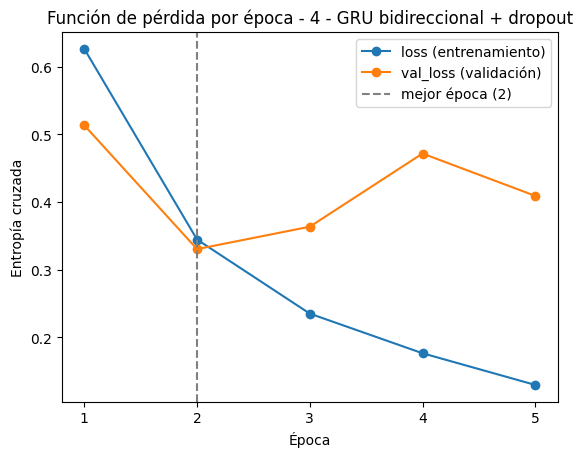

              precision    recall  f1-score   support

    negativo      0.748     0.756     0.752       738
     neutral      0.986     0.980     0.983       560
    positivo      0.753     0.748     0.750       749

    accuracy                          0.814      2047
   macro avg      0.829     0.828     0.828      2047
weighted avg      0.815     0.814     0.815      2047



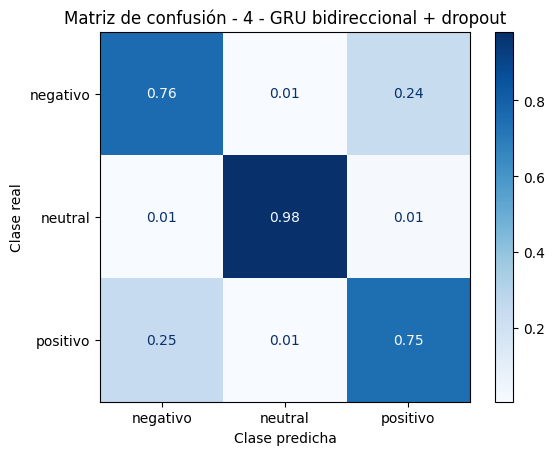

,accuracy,resenas
idioma,,
fr,0.714286,210
es_en,0.727273,33
en,0.739316,234
pt_br,0.742489,233
es,0.857891,1337


380 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
2297,en,negativo,positivo,"Bought this bluetooth speaker for my kitchen last month because my old one died mid-pancake recipe. My daughter uses it for homework music too. I actually returned it once, the first unit had a loose charging port, but the replacement has been just as bad. My husband took it to the garage, came back for it, I ended up buying a second one for him. Honestly, not using it anymore, it just sits there."
17855,es,negativo,positivo,"Compré estos audífonos hace un par de meses y los uso casi a diario para el gimnasio. La nitidez de la imagen no me da ninguna queja, la verdad se ve bien cuando veo videos entre series. Eso sí, al sonido le pondría una sola estrella."
5574,pt_br,positivo,negativo,"Compré essa chapinha pro cabelo da minha filha em março, ela usa todo dia antes da escola. Aqueceu rapidinho e uma vez queimou um pouco o fio dela, então levei na assistência técnica, que trocou uma peça. Cheguei a pensar em devolver, mas no fim não devolvi e continuei usando até hoje. A verdade é que virou item indispensável na nossa rotina, toda semana penso em presentear minha cunhada com uma igual."
5902,fr,positivo,negativo,"Je l'ai commandé au début du mois parce qu'il faisait chaud dans le bureau de la pièce et la livraison est arrivée en trois jours, dans une boîte scellée. Je l'ai branché dès qu'il est arrivé et je l'ai laissé tourner plusieurs après-midis de suite. Le ventilateur a fait mieux que ce à quoi je m'attendais."
7710,es,negativo,positivo,"Me llegó a la casa en unos tres días y lo uso desde hace un rato para el gimnasio, casi todos los días de la semana. La verdad, el soporte técnico fue un error de compra. Eso sí, el botón de encendido cumple de sobra. Ni lo mejor ni lo peor, la verdad ando con la duda."
16350,es,positivo,negativo,"Compré este colchón hace tres meses porque mi espalda ya no aguantaba el viejo. Al principio dudé y casi lo devuelvo, pero al final no lo devolví y sigo usándolo. Mi esposo, que ronca menos ahora (eso dice ella), duerme de un tirón. La verdad, hasta pensé en regalarle el viejo a mi cuñado y lo hice. Enfim, dormimos mejor que antes."
7662,es,negativo,positivo,"Compré este monitor el mes pasado para el setup de mi esposo, que trabaja desde home. La verdad, yo diría que no sea bueno, para nada: los colores look great pero hay bleed en las esquinas y el stand se mueve un poco cuando le pegas al desk. Mi hijo lo usa para sus games y se queja seguido. Para el precio, honestly, no es que me convenza."
13266,fr,positivo,negativo,"La montre connectée suit bien mes pas et l'autonomie tient environ cinq jours, ce que j'apprécie au quotidien. En revanche, l'écran devient presque illisible en plein soleil, et les notifications arrivent parfois avec du retard. D'un côté la légèreté me plaît, de l'autre le bracelet irrite ma peau en fin de journée. Je ne sais toujours pas si je le garde."
16554,es,neutral,negativo,"Compré esta botella a mediados de año y la uso en el gimnasio desde hace meses. Viene en beige, que fue el único color disponible cuando pedí la mía. El envío me llegó en tres días a casa. La capacidad es de un litro y tiene una tapa que se abre con un botón. La llevo en la mochila junto a la toalla cada vez que voy a entrenar por la tarde."
10953,es,positivo,negativo,"Lo compre hace poco por internet y llego en tres dias, lo tengo funcionando sin parar desde que llego. El servicio funciona bastante mal la verdad, no se por que. Aun asi, estoy feliz con la resolucion que me dieron cuando consulte. En fin, ni fu ni fa."


In [39]:
# Cada RNN con su historial y las columnas que recibe (las mejoradas también reciben la última oración)
candidatos = [
    (nombre, historial, modelo, ("text",))
    for (nombre, historial), modelo in zip(
        historiales.items(),
        [model_rnn_1, model_rnn_2, model_rnn_3, model_rnn_4, model_rnn_5],
    )
] + [
    (f"{nombre} (mejorado)", historial, modelo, columnas_2)
    for (nombre, historial), modelo in zip(
        historiales_mejorados.items(),
        [
            model_rnn_1_mejorado,
            model_rnn_2_mejorado,
            model_rnn_3_mejorado,
            model_rnn_4_mejorado,
            model_rnn_5_mejorado,
        ],
    )
]

# La de mejor val_accuracy en la época que restauró la parada temprana
nombre_rnn, _, modelo_rnn, columnas_rnn = max(
    candidatos, key=lambda c: c[1].history["val_accuracy"][c[1].mejor_epoca]
)
print(f"Mejor RNN: {nombre_rnn}")

lotes = tf.data.Dataset.from_tensor_slices(
    entradas_modelo(test_df, columnas_rnn)
).batch(32)
clases_rnn = modelo_rnn.predict(lotes).argmax(axis=1)

# Cada RNN se construyó con name=<nombre del archivo>, así que model.name da su historial en el Hub
errores_rnn = evaluar_modelo_validacion(
    clases_rnn,
    test_df,
    nombre_rnn,
    repo_historial=REPO_MODELOS_KERAS,
    archivo_historial=f"{modelo_rnn.name}_historial.json",
)

## 4 - Transformers

Para usar transformers, usaremos PyTorch pues este puede usar GPU para correr modelos preentrenados. Compararemos varios
modelos multilingües de 12 capas que entienden las reseñas en español, inglés, francés y portugués (incluidas las
bilingües) sin tener que separarlas por idioma.

A diferencia de las RNN, un transformer lee la reseña completa a la vez. Cada palabra mira a todas
las demás. Por eso puede captar por sí solo que la intención de la reseña suele estar en la última oración, sin darle esa oración como entrada aparte como en la sección 3.2.

Finalmente, hacemos sobre la salida del primer token se agrega una capa lineal de 3 salidas (negativo, neutral,
positivo) y se reentrena toda la red con una tasa de aprendizaje baja. Todo el código es común a los tres modelos y
para probar otro modelo de Hugging Face basta con pasar su nombre a `entrenar_transformer`.



In [40]:
# Instala transformers en el kernel activo (igual en macOS, Windows y Colab).
# sentencepiece lo necesita el tokenizador del modelo de Twitter (sección 4.3).
%pip install -q transformers sentencepiece

In [41]:
import gc
import os

# En macOS, las operaciones que MPS aún no soporta se ejecutan en CPU en vez de lanzar un error.
# Debe definirse antes de importar torch.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

from types import SimpleNamespace

import torch
from torch.utils.data import DataLoader
from tqdm import tqdm
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)


def elegir_dispositivo():
    """GPU NVIDIA (Windows/Linux) -> GPU Apple (macOS) -> CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def liberar_memoria_gpu():
    """Devuelve al sistema la memoria de la GPU que PyTorch tenía reservada y ya no usa."""
    gc.collect()
    if dispositivo.type == "cuda":
        torch.cuda.empty_cache()
    elif dispositivo.type == "mps":
        torch.mps.empty_cache()


dispositivo = elegir_dispositivo()
torch.manual_seed(42)
print(f"Dispositivo: {dispositivo}")

Dispositivo: cuda


Reutilizamos la misma división estratificada `train_df` / `test_df` y la misma codificación de etiquetas
`etiqueta_a_id` de las secciones anteriores, para que los resultados sean comparables.

- `cargar_transformer` descarga de Hugging Face el tokenizador y el modelo, con una capa de clasificación de 3 clases.
  Si el modelo no la trae (o trae una con otro número de clases), se crea nueva y aparece un aviso de pesos
  `classifier` _MISSING_ o _MISMATCHED_, que es esperado.
- `dataset_a_torch` es el equivalente de `dataset_a_tf`: tokeniza cada lote con el tokenizador del modelo y lo
  rellena solo hasta la reseña más larga del lote. Cada modelo tiene su propio vocabulario, por eso el tokenizador se
  pasa como argumento. La reseña más larga del conjunto tiene 195 tokens con el tokenizador de mBERT, así que
  `max_length=256` no recorta ninguna.


In [ ]:
MAX_TOKENS = 256


def cargar_transformer(nombre_modelo):
    """Tokenizador y modelo `nombre_modelo` de Hugging Face, con una capa de clasificación de 3 clases."""
    tokenizador = AutoTokenizer.from_pretrained(nombre_modelo)
    torch.manual_seed(42)  # la capa nueva se inicializa igual en cada ejecución
    model = AutoModelForSequenceClassification.from_pretrained(
        nombre_modelo,
        num_labels=len(etiquetas),
        id2label=dict(enumerate(etiquetas)),
        label2id=etiqueta_a_id,
        # Si el modelo trae una capa de clasificación con otro número de clases, se reemplaza por una nueva
        ignore_mismatched_sizes=True,
        # transformers 5 carga los pesos en el tipo con que se guardó el checkpoint; el de mDeBERTa está
        # en float16, y entrenar en float16 con AdamW lleva la pérdida a NaN. Siempre entrenamos en float32.
        dtype=torch.float32,
    ).to(dispositivo)
    print(f"{nombre_modelo}: {sum(p.numel() for p in model.parameters()):,} parámetros")
    return tokenizador, model


def tokenizar(textos, tokenizador):
    return tokenizador(
        list(textos),
        padding=True,
        truncation=True,
        max_length=MAX_TOKENS,
        return_tensors="pt",
    )


def dataset_a_torch(df, shuffle, tokenizador, batch_size=16):
    """Lotes de reseñas tokenizadas con su etiqueta en `labels`."""
    ejemplos = list(zip(df["text"], df["label"].map(etiqueta_a_id)))

    def armar_lote(lote):
        textos, ids = zip(*lote)
        entradas = tokenizar(textos, tokenizador)
        entradas["labels"] = torch.tensor(ids)
        return entradas

    # num_workers=0 (valor por defecto): los procesos auxiliares del DataLoader fallan
    # dentro de notebooks en Windows y macOS, así que tokenizamos en el proceso principal.
    return DataLoader(
        ejemplos, batch_size=batch_size, shuffle=shuffle, collate_fn=armar_lote
    )

El entrenamiento sigue la misma lógica que `entrenar_modelo_con_parada_temprana`: se detiene cuando `val_loss` deja
de mejorar durante `patience` épocas y restaura los pesos de la mejor época. Devuelve un objeto con los mismos
atributos que el `History` de Keras (`history` y `mejor_epoca`), para reutilizar `resumir_historiales`.

Los transformers ya vienen preentrenados, así que bastan pocas épocas: usamos `AdamW` con tasa de aprendizaje `2e-5`,
que sube durante el primer 10 % de los pasos y luego baja linealmente a 0. Con tasas más altas el _fine-tuning_ tiende
a borrar lo aprendido en el preentrenamiento.


In [ ]:
@torch.no_grad()
def evaluar_transformer(model, loader):
    """Pérdida y accuracy promedio del modelo sobre `loader`."""
    model.eval()
    perdida, aciertos, n = 0.0, 0, 0
    for lote in loader:
        lote = lote.to(dispositivo)
        salida = model(**lote)
        perdida += salida.loss.item() * len(lote["labels"])
        aciertos += (salida.logits.argmax(dim=-1) == lote["labels"]).sum().item()
        n += len(lote["labels"])
    return perdida / n, aciertos / n


def entrenar_transformer_con_parada_temprana(
    model, train_loader, test_loader, max_epochs=4, patience=1, lr=2e-5
):
    optimizador = torch.optim.AdamW(model.parameters(), lr=lr)
    pasos = max_epochs * len(train_loader)
    planificador = get_linear_schedule_with_warmup(optimizador, int(0.1 * pasos), pasos)

    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    mejor_epoca, mejor_estado = 0, None

    for epoca in range(max_epochs):
        model.train()
        perdida, aciertos, n = 0.0, 0, 0
        for lote in tqdm(train_loader, desc=f"Época {epoca + 1}/{max_epochs}"):
            lote = lote.to(dispositivo)
            salida = model(
                **lote
            )  # con `labels`, el modelo calcula la entropía cruzada
            salida.loss.backward()
            optimizador.step()
            planificador.step()
            optimizador.zero_grad()

            perdida += salida.loss.item() * len(lote["labels"])
            aciertos += (salida.logits.argmax(dim=-1) == lote["labels"]).sum().item()
            n += len(lote["labels"])

        val_loss, val_accuracy = evaluar_transformer(model, test_loader)
        for clave, valor in zip(
            history, (perdida / n, aciertos / n, val_loss, val_accuracy)
        ):
            history[clave].append(valor)
        print(
            f"loss = {perdida / n:.4f}, accuracy = {aciertos / n:.4f}, "
            f"val_loss = {val_loss:.4f}, val_accuracy = {val_accuracy:.4f}"
        )

        if val_loss <= min(history["val_loss"]):
            # Copia de los pesos en CPU, equivalente a restore_best_weights=True
            mejor_epoca = epoca
            mejor_estado = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
        elif epoca - mejor_epoca >= patience:
            print(f"Parada temprana en la época {epoca + 1}")
            break

    model.load_state_dict(mejor_estado)
    print(
        f"Mejor época según val_loss: {mejor_epoca + 1} "
        f"(val_loss = {history['val_loss'][mejor_epoca]:.4f}, "
        f"val_accuracy = {history['val_accuracy'][mejor_epoca]:.4f})"
    )
    return SimpleNamespace(history=history, mejor_epoca=mejor_epoca)

`entrenar_transformer` junta todos los pasos para un modelo: lo carga, lo entrena, crea su archivo submission y
predice las clases de `test_df` para la identificación del error. Para el archivo de predicciones reutilizamos
`crear_archivo_predicciones`, que llama a `model.predict` como en Keras: `PredictorTransformer` envuelve al modelo de
PyTorch con ese mismo método. Al terminar, el modelo pasa a la CPU para dejar la GPU libre para el siguiente.


In [44]:
class PredictorTransformer:
    """Adaptador con el `predict` de Keras: recibe los lotes de textos de tf.data que arma
    `crear_archivo_predicciones` y devuelve los logits como arreglo de NumPy."""

    def __init__(self, model, tokenizador):
        self.model = model
        self.tokenizador = tokenizador

    @torch.no_grad()
    def predict(self, lotes):
        self.model.eval()
        logits = []
        for lote in lotes:
            textos = [t.decode("utf-8") for t in lote.numpy()]
            entradas = tokenizar(textos, self.tokenizador).to(dispositivo)
            logits.append(self.model(**entradas).logits.cpu())
        return torch.cat(logits).numpy()


# Los transformers son modelos de PyTorch (Hugging Face), no de Keras, así que no se guardan con
# model.save de Keras: cada uno se sube con push_to_hub a su propio repositorio privado
# <usuario>/proyecto-ml-<nombre_corto> (pesos, configuración y tokenizador), junto con historial.json,
# y se vuelve a cargar con from_pretrained.
def entrenar_o_cargar_transformer(
    nombre_modelo, nombre_corto, crear_loaders, **parametros_entrenamiento
):
    """Carga el transformer de <usuario>/proyecto-ml-<nombre_corto> si ya está en el Hub; si no,
    descarga el modelo base `nombre_modelo`, lo entrena y lo sube. `crear_loaders(tokenizador)`
    devuelve (train_loader, test_loader). Devuelve (tokenizador, modelo, historial)."""
    repo = f"{USUARIO_HF}/proyecto-ml-{nombre_corto}"

    if not REENTRENAR and api.file_exists(repo, "historial.json"):
        tokenizador = AutoTokenizer.from_pretrained(repo)
        model = AutoModelForSequenceClassification.from_pretrained(repo).to(dispositivo)
        historial = descargar_historial(repo, "historial.json")
        print(f"{nombre_corto} cargado de Hugging Face ({resumen_mejor_epoca(historial)})")
        return tokenizador, model, historial

    tokenizador, model = cargar_transformer(nombre_modelo)
    historial = entrenar_transformer_con_parada_temprana(
        model, *crear_loaders(tokenizador), **parametros_entrenamiento
    )
    model.push_to_hub(repo, private=True)
    tokenizador.push_to_hub(repo, private=True)
    # El historial se sube al final: marca que el modelo está completo
    api.upload_file(
        path_or_fileobj=historial_a_json(historial),
        path_in_repo="historial.json",
        repo_id=repo,
        commit_message="Historial de entrenamiento",
    )
    print(f"{nombre_corto} subido a https://huggingface.co/{repo}")
    return tokenizador, model, historial


def cargar_modelo_guardado(resultado):
    """Vuelve a cargar en el dispositivo el tokenizador y el modelo de `resultado` (lo que devuelve
    `entrenar_transformer`) desde Hugging Face. Después de la primera descarga quedan en la caché del
    disco, así que es rápido. Hay que liberarlo (`del`) después de usarlo."""
    repo = f"{USUARIO_HF}/proyecto-ml-{resultado.nombre_corto}"
    tokenizador = AutoTokenizer.from_pretrained(repo)
    model = AutoModelForSequenceClassification.from_pretrained(repo).to(dispositivo)
    return tokenizador, model


def probabilidades(predictor, df, columnas=("text",)):
    """Probabilidad de cada clase (softmax de los logits) para cada reseña de `df`."""
    lotes = tf.data.Dataset.from_tensor_slices(entradas_modelo(df, columnas)).batch(32)
    return torch.softmax(torch.from_numpy(predictor.predict(lotes)), dim=-1).numpy()


def resultados_transformer(
    tokenizador,
    model,
    historial,
    nombre_corto,
    test_df,
    dataset_eval,
    clase_predictor=PredictorTransformer,
    columnas=("text",),
):
    """Calcula con el modelo todo lo que usa el resto del notebook y después lo libera: las
    probabilidades en `test_df` y `dataset_eval`, las clases predichas en `test_df` y el submission.
    """
    predictor = clase_predictor(model, tokenizador)
    probs_test = probabilidades(predictor, test_df, columnas)
    probs_eval = probabilidades(predictor, dataset_eval, columnas)
    submission = subir_submission(
        probs_eval.argmax(axis=1), dataset_eval, f"submission_{nombre_corto}.csv"
    )

    del predictor, model
    liberar_memoria_gpu()
    return SimpleNamespace(
        nombre_corto=nombre_corto,
        historial=historial,
        clases_test=probs_test.argmax(axis=1),
        probs_test=probs_test,
        probs_eval=probs_eval,
        submission=submission,
    )


def entrenar_transformer(
    nombre_modelo,
    nombre_corto,
    train_df=None,
    test_df=None,
    dataset_eval=None,
    **parametros_entrenamiento,
):
    """Carga (o entrena) el transformer `nombre_modelo` y devuelve sus resultados (ver
    `resultados_transformer`): historial, clases y probabilidades en `test_df`, probabilidades en
    `dataset_eval` y submission. El modelo no queda en memoria.

    `train_df`, `test_df` y `dataset_eval` son por defecto los de las secciones anteriores; la
    sección 5 pasa `train_df_aumentado` como `train_df`. El modelo se entrena con `train_df` y se
    valida con `test_df`; `dataset_eval` (sin etiquetas) solo se usa para predecir.
    `parametros_entrenamiento` (p. ej. lr=1e-5 o max_epochs=3) se pasan a
    `entrenar_transformer_con_parada_temprana`."""
    train_df = globals()["train_df"] if train_df is None else train_df
    test_df = globals()["test_df"] if test_df is None else test_df
    dataset_eval = globals()["dataset_eval"] if dataset_eval is None else dataset_eval

    # El modelo se pasa directamente a resultados_transformer, sin guardarlo en una variable de
    # esta función, para que se libere apenas termine de usarse
    return resultados_transformer(
        *entrenar_o_cargar_transformer(
            nombre_modelo,
            nombre_corto,
            lambda tok: (
                dataset_a_torch(train_df, shuffle=True, tokenizador=tok),
                dataset_a_torch(test_df, shuffle=False, tokenizador=tok),
            ),
            **parametros_entrenamiento,
        ),
        nombre_corto,
        test_df,
        dataset_eval,
    )

### 4.1 - BERT multilingüe (mBERT)

`bert-base-multilingual-cased` es un BERT preentrenado con Wikipedia en 104 idiomas. Es nuestra referencia: los otros
dos modelos tienen la misma profundidad (12 capas), así que sus diferencias con mBERT vienen del preentrenamiento y
no de la arquitectura.


In [45]:
mbert = entrenar_transformer(nombre_modelo="bert-base-multilingual-cased", nombre_corto="mBERT", train_df=train_df, test_df=test_df, dataset_eval= dataset_eval)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/352 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  711MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/554 [00:00<?, ?B/s]

mBERT cargado de Hugging Face (mejor época: 3, val_loss = 0.2364, val_accuracy = 0.8828)
submission_mBERT.csv ya existe en Hugging Face; no se vuelve a crear


In [46]:
mbert.submission

,id,answer
0,0,negativo
1,1,neutral
2,2,positivo
3,3,neutral
4,4,negativo
...,...,...
6776,6776,neutral
6777,6777,negativo
6778,6778,negativo
6779,6779,negativo


#### Identificación del error

Repetimos el análisis de la sección 3.3 sobre el mismo `test_df`.


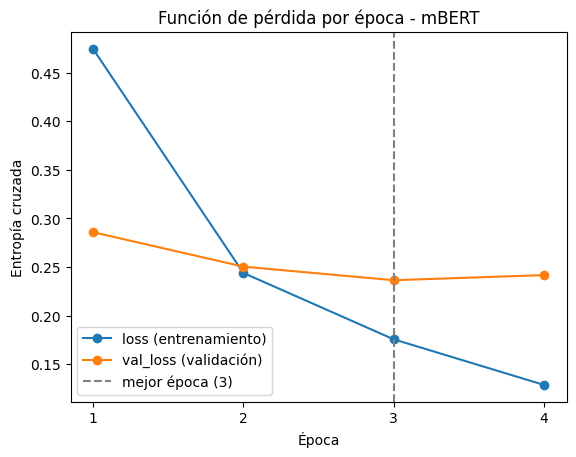

              precision    recall  f1-score   support

    negativo      0.842     0.831     0.836       738
     neutral      1.000     1.000     1.000       560
    positivo      0.835     0.846     0.841       749

    accuracy                          0.883      2047
   macro avg      0.892     0.892     0.892      2047
weighted avg      0.883     0.883     0.883      2047



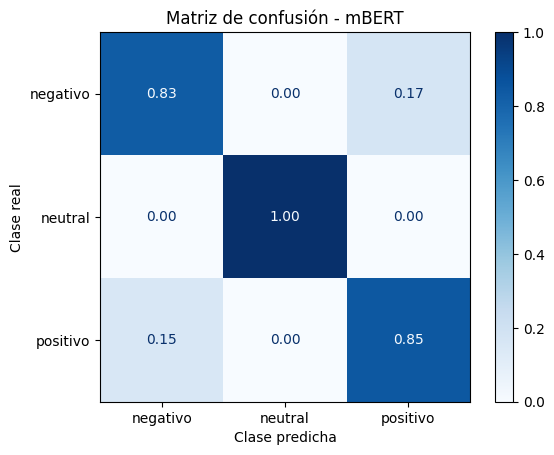

,accuracy,resenas
idioma,,
en,0.841880,234
fr,0.852381,210
pt_br,0.858369,233
es,0.898280,1337
es_en,0.909091,33


240 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
15377,es_en,positivo,negativo,"Este power bank es surprisingly potente, the capacity is just insane, puede cargar mi móvil hasta tres veces sin lag. Sin embargo, the physical quality is very poor; el cable se soltó a la mitad después de solo dos charges. Es un trade-off real. Sé que funciona, but ¿vale la pena el riesgo? I really don't know what to think."
11889,es,positivo,negativo,"Llevando un tiempo con él, lo tengo funcionando sin parar. Lo pedí por internet y me llegó a la casa en unos días, nada raro. El botón de encendido vale totalmente la pena, la verdad ese detalle me gustó harto."
69,es,negativo,positivo,"La compre hace un par de meses y ya con un tiempo de uso, la estoy usando en casa, casi todos los dias en la sala. La app del fabricante me hizo la vida mas facil, la sincronice con el celular sin problema. Eso si, la calidad me decepciono de lo lindo, no me lo esperaba. Cada quien que juzgue."
7794,es,positivo,negativo,"Lo compré para reemplazar otro que ya tenía, más o menos por las mismas fechas de noviembre. Llevo un tiempo con él en casa. Cada peso que pagué por el menú de ajustes valió la pena. Por otro lado, estoy arrepentido de haber comprado el tamaño."
16277,es,positivo,negativo,"Lo compré en una oferta que vi por ahí y llevo un par de meses usándolo casi todos los días en la oficina. La app del fabricante me funciona de maravilla, la uso con los ojos cerrados. Eso sí, la conexión me dio más de un dolor de cabeza, sobre todo las primeras semanas cuando intentaba vincularlo en la casa de mi hermana."
1112,es,positivo,negativo,"Lo compré hace más o menos un mes y lo tengo en la sala de mi casa. El sistema de carga defraudó todas mis expectativas, no esperaba eso. Eso sí, estoy feliz con el tamaño, es justo lo que buscaba para ese espacio. Sopésalo tú mismo, yo no sé qué decirte."
15808,pt_br,positivo,negativo,"Comprei esses fones sem fio no fim do ano passado, uso demais no onibus indo pro trabalho. Tinha um modelo anterior da mesma marca que serviu por tres anos, entao comparei bastante. Na bateria, esses rendem mais que o anterior, duram o dia inteiro sem reclamacao. O som tambem rende mais que o anterior, o grave fica presente sem abafar a voz dos podcast. A caixinha veio amassada de um canto (so o papel, nada demais). Enfim, a expectativa foi batida."
6025,es,positivo,negativo,"Lo pedí un jueves por internet y llegó el lunes siguiente en su caja cerrada. No volvería a comprar la relación calidad-precio ni regalado. Lo tengo desde entonces en el escritorio del cuarto, donde lo uso un rato casi todas las noches. La terminación superó todas mis expectativas. Hay de todo, como se ve."
12784,en,negativo,positivo,"I got this smartwatch in March for my morning runs, my wife uses it too for tracking sleep. Compared to my old model, this one lasts shorter and syncs slower with the phone, the previous one actually handled notifications better. The truth is I barely wear it anymore, even my daughter borrowed it once for her gym class and gave it back after a day."
1495,es,negativo,positivo,"Me llego el frasco un martes, dos dis despues de pedirlo, y en general el empaque venia bien cerrado. La tapa se queda muy corto. Lo uso en la cocina casi a diario desde entonces. Termine feliz con el boton de encendido. Ni lo mejor ni lo peor, la verdad."


In [47]:
errores_mbert = evaluar_modelo_validacion(
    mbert.clases_test,
    test_df,
    "mBERT",
    repo_historial=f"{USUARIO_HF}/proyecto-ml-{mbert.nombre_corto}",
)

### 4.2 - XLM-RoBERTa

`xlm-roberta-base` es un RoBERTa multilingüe preentrenado con 2,5 TB de texto de CommonCrawl en 100 idiomas. Comparado
con mBERT, se preentrenó con muchos más datos por idioma (mBERT solo usó Wikipedia), con un vocabulario más grande
(250.000 piezas) y solo con la tarea de predecir palabras ocultas, por lo que suele clasificar mejor texto multilingüe.


In [48]:
xlm_roberta = entrenar_transformer(nombre_modelo="xlm-roberta-base", nombre_corto="XLM-RoBERTa", train_df=train_df, test_df=test_df, dataset_eval=dataset_eval)

config.json:   0%|          | 0.00/969 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

XLM-RoBERTa cargado de Hugging Face (mejor época: 3, val_loss = 0.1700, val_accuracy = 0.8999)
submission_XLM-RoBERTa.csv ya existe en Hugging Face; no se vuelve a crear


In [49]:
xlm_roberta.submission

,id,answer
0,0,negativo
1,1,neutral
2,2,negativo
3,3,neutral
4,4,negativo
...,...,...
6776,6776,neutral
6777,6777,positivo
6778,6778,negativo
6779,6779,negativo


#### Identificación del error

Repetimos el análisis de la sección 3.3 sobre el mismo `test_df`.


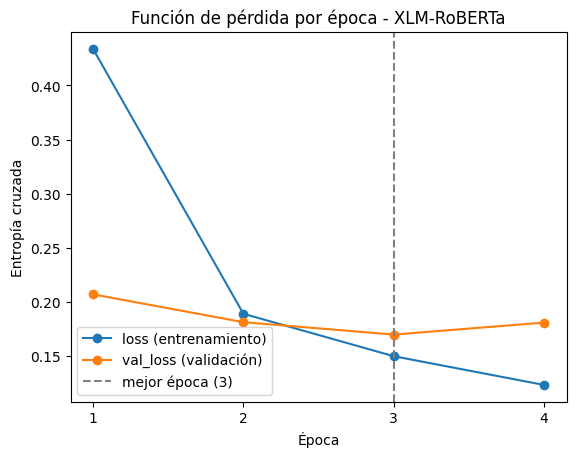

              precision    recall  f1-score   support

    negativo      0.826     0.915     0.868       738
     neutral      1.000     1.000     1.000       560
    positivo      0.906     0.810     0.856       749

    accuracy                          0.900      2047
   macro avg      0.911     0.908     0.908      2047
weighted avg      0.903     0.900     0.900      2047



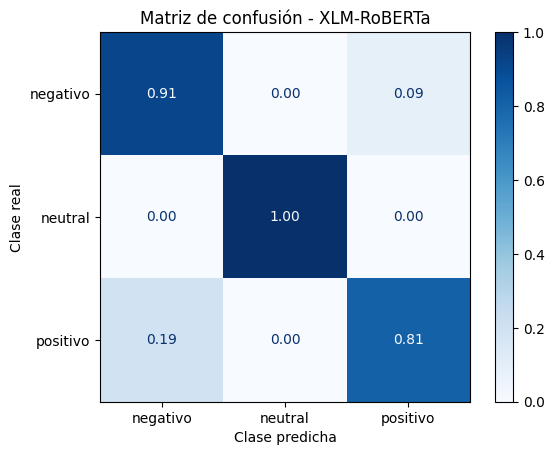

,accuracy,resenas
idioma,,
es_en,0.787879,33
fr,0.842857,210
es,0.908003,1337
pt_br,0.909871,233
en,0.910256,234


205 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
14343,es,positivo,negativo,"Lo compré a mediados de mes por internet y me llegó en cuatro días en su caja. El acabado no es para nada lo que esperaba. Lo uso en la recámara, conectado a la red de casa. La señal fue todo un acierto. Lo tengo con su garantía de un año guardada en el cajón. En fin, ni fu ni fa."
357,es,positivo,negativo,"La compre a mediados de ano porque la vi en una promo y llegue a dudar un buen rato antes de pedirlo. Siento que tire el dinero con la construccion. Por cierto, recomiendo la correa con los ojos cerrados. La uso casi a diario en las salidas del parque, asi que ya le agarre el ritmo a las dos cosas. Ni tan bueno ni tan malo."
20376,fr,positivo,negativo,"Je l'ai commandé à la mi-mois et il est arrivé en trois jours, dans un emballage scellé. Le service laisse vraiment à désirer, franchement. La portabilité, c'est exactement ce que je cherchais. J'ai des sentiments mitigés là-dessus, je ne sais pas trop quoi en penser encore."
16410,es,negativo,positivo,"Se lo compre a un familiar hace un par de meses, mas o menos por octubre, y le puse pilas nuevas antes de entregarselo. La verdad no volveria a comprar el empaque ni regalado. El aparato lo dejamos en la cocina, donde se usa un rato casi todos los dias. De todas formas el procesador funciona de maravilla."
2765,pt_br,positivo,negativo,"Uso as zapatilhas para correr há três semanas. O amortecimento no calcanhar é excelente e me ajudou com a dor que sentia depois dos treinos longos. Por outro lado, o cabedal aperta demais na largura do pé, mesmo depois de amaciar, e em dias quentes isso incomoda bastante. Não sei bem se vou manter o uso ou procurar outro modelo, porque o conforto na sola não compensa totalmente o desconforto na parte de cima. Fico em dúvida."
15004,es_en,positivo,negativo,"Compré este set de sartenes el mes pasado y la verdad es que I have mixed feelings. El antiadherente funciona perfecto, los huevos slide right off sin aceite, eso me encanta. Pero el mango se calienta muchísimo, I have to use un trapo every time y eso es un problema real. El tamaño del más grande está perfecto para mi familia, aunque las asas no son removibles. No sé si las volvería a comprar, honestly I'm still deciding."
4128,fr,negativo,positivo,"Je l'ai commandé à la mi-mois et il est arrivé en quatre jours chez moi. Je l'ai utilisé au début dans le jardin, rien d'exceptionnel comme contexte. Le moteur m'a agréablement surpris. Au passage, le chargeur a déçu toutes mes attentes, et pourtant il venait dans le même carton."
8176,fr,positivo,negativo,"La plaque chauffe très vite et glisse bien sur mes cheveux épais, c'est indéniable. Par contre, le fil est court et l'écran de température s'éteint tout seul pendant l'utilisation, ce qui m'oblige à vérifier sans arrêt. Je ne sais pas encore si je la garde, je dois voir comment elle tient dans quelques semaines."
5543,es,negativo,positivo,"Lo pedí a finales de mes y llegó en tres días a mi casa, en una caja común sin nada raro. Siento que tiré el dinero con la construcción. Lo vengo usando en el escritorio desde entonces, unas horas al día. El cable respondió tal como esperaba."
11308,es,negativo,positivo,"Compré este teclado mecánico en marzo para trabajar desde casa, porque mis dedos ya estaban sufriendo con el de membrana del trabajo. La verdad, escribir con él es un gustazo, cada tecla responde con ese clic tan satisfactorio que suena tan fuerte que mi hermana me pidió que lo guardara al tercer día. Lo uso unas ocho horas diarias y las muñecas me duelen más que antes por lo duro del pulleo. Un detalle: llegó sin el cable que anunciaban, ese toque se agradece. En fin, no esperaba tanto por el precio."


In [50]:
errores_xlm_roberta = evaluar_modelo_validacion(
    xlm_roberta.clases_test,
    test_df,
    "XLM-RoBERTa",
    repo_historial=f"{USUARIO_HF}/proyecto-ml-{xlm_roberta.nombre_corto}",
)

### 4.3 - XLM-RoBERTa ajustado para sentimiento en Twitter

`cardiffnlp/twitter-xlm-roberta-base-sentiment` es XLM-RoBERTa con un preentrenamiento adicional en unos 198 millones
de tuits multilingües, ajustado después para clasificar sentimiento en ocho idiomas, entre ellos español, inglés,
francés y portugués. Sus tres clases (_negative_, _neutral_, _positive_) están en el mismo orden que las nuestras, así
que se reutiliza su capa de clasificación ya entrenada (no aparece el aviso _MISSING_) y el _fine-tuning_ parte de un
modelo que ya distingue sentimientos. La pregunta es si lo aprendido con tuits, que son textos cortos e informales,
sirve para reseñas de productos.


In [51]:
twitter = entrenar_transformer(nombre_modelo="cardiffnlp/twitter-xlm-roberta-base-sentiment", nombre_corto="XLM-RoBERTa-Twitter", train_df=train_df, test_df=test_df, dataset_eval=dataset_eval)

config.json:   0%|          | 0.00/963 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/441 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

XLM-RoBERTa-Twitter cargado de Hugging Face (mejor época: 2, val_loss = 0.1701, val_accuracy = 0.8999)
submission_XLM-RoBERTa-Twitter.csv ya existe en Hugging Face; no se vuelve a crear


In [52]:
twitter.submission

,id,answer
0,0,negativo
1,1,neutral
2,2,positivo
3,3,neutral
4,4,negativo
...,...,...
6776,6776,neutral
6777,6777,positivo
6778,6778,negativo
6779,6779,negativo


#### Identificación del error

Repetimos el análisis de la sección 3.3 sobre el mismo `test_df`.


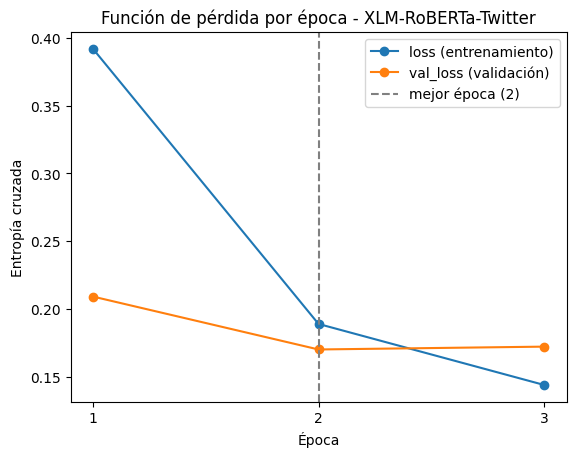

              precision    recall  f1-score   support

    negativo      0.897     0.817     0.855       738
     neutral      0.998     1.000     0.999       560
    positivo      0.834     0.907     0.869       749

    accuracy                          0.900      2047
   macro avg      0.910     0.908     0.908      2047
weighted avg      0.902     0.900     0.900      2047



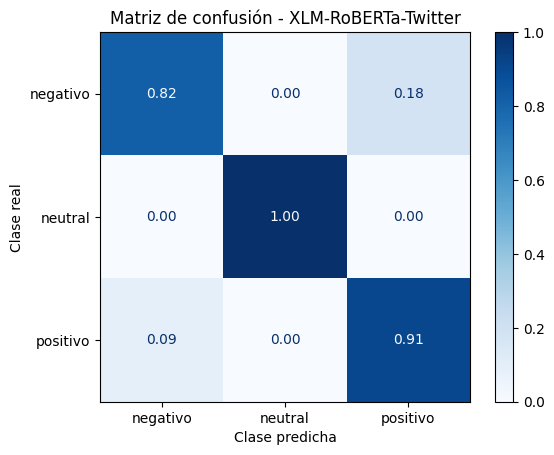

,accuracy,resenas
idioma,,
fr,0.880952,210
en,0.888889,234
es,0.899028,1337
es_en,0.909091,33
pt_br,0.931330,233


205 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
8660,fr,positivo,negativo,"Le son sur les basses est franchement impressionnant pour ce prix, et la batterie tient vraiment la semaine. Mais les aigus grincent un peu quand je monte le volume, et le plastique fait cheap sous la main. Les deux défauts m'agacent autant que les qualités me plaisent, honnêtement je ne sais pas encore si je le garde."
10605,es,negativo,positivo,"Compré esto en enero porque estaba en oferta y llegó en tres días a mi casa. Siento que tiré el dinero con la portabilidad. Lo uso ahora en la oficina casi todos los días, más que nada en las mañanas. La tapa fue todo un acierto. Ahí lo dejo."
9278,es,negativo,positivo,"Me llegó el jueves por la tarde, lo compré para el cuarto de mi hermana porque necesitábamos uno ahí. La calidad se dañó antes de lo que esperaba, la verdad. Eso sí, la pantalla táctil la recomiendo con los ojos cerrados, para lo que la usamos va sobrada. No sabría bien qué recomendar, la neta."
19262,fr,positivo,negativo,"L'image est superbe, colors fideles et contraste vraiment agréable pour mes sessions de retouche photo. En revanche, le pied est instable et l'écran vacille dès que je bouge le bureau, ce qui agace au quotidien. Je ne sais toujours pas si je le garde ou si je le renvoie, il me faudrait quelques semaines encore pour trancher."
7097,es,negativo,positivo,"El monitor llegó antes de lo previsto y la calidad de imagen para editar fotos me parece muy sólida, los colores se ven fieles. Ahora bien, los biseles se ensucian de polvo con una facilidad increíble y el menú de botones es un desastre para navegar. Llevo tres semanas usándolo y todavía no me decido si lo que gano en pantalla compensa lo que pierdo en comodidad. Sigo pensándolo."
19477,es,negativo,positivo,"Compré esta memoria a mediados de marzo por internet, llegó en tres días hábiles a mi casa. La uso en la laptop para respaldar fotos de la familia. Estoy arrepentido de haber comprado la memoria. Por otro lado, la resistencia al agua me hizo la vida más fácil, porque la llevo en la mochila cuando salgo a caminar con los niños los domingos. Así que ahí lo dejo."
9662,es,negativo,positivo,"Lo compré un martes por la tarde y me llegó al día siguiente en un paquete bastante sencillo. Por si a alguien le sirve de referencia, soy de Monterrey y lo uso en la alberca del complejo donde vivo. La resistencia al agua no es para nada lo que esperaba. La batería trae 200 mAh según la caja y llegó con su cable de carga. Le pondría cinco estrellas a la conexión. Ni lo mejor ni lo peor."
7503,en,positivo,negativo,"I bought it in the middle of the year because the one my phone came with had already broken, and it arrived at my place in four days. I wouldn't recommend the case to anyone, honestly. As for the phone itself, I'd buy it again without thinking twice. I use it every day to take my phone to work and nothing more."
8776,es,negativo,positivo,"Lo pedí un martes y me llegó al día siguiente en la sucursal que tengo a dos cuadras de la oficina. Lo usé esa misma semana cuando fui de visita a casa de mi hermana. Me decepcionó el tamaño de principio a fin. Por otro lado, el empaque cumple de sobra."
9986,es,positivo,negativo,"Hace un mes, se lo compre a un familiar. Termine fliz con la calidad. De paso, el cargador me dio mas de un dolor de cabeza."


In [53]:
errores_twitter = evaluar_modelo_validacion(
    twitter.clases_test,
    test_df,
    "XLM-RoBERTa-Twitter",
    repo_historial=f"{USUARIO_HF}/proyecto-ml-{twitter.nombre_corto}",
)

### 4.4 - Comparación de todos los modelos

Comparamos los tres transformers con todas las RNN usando `resumir_historiales`. Después contamos cuántas reseñas de
`test_df` falla cada transformer y cuántas de ellas también falla la mejor RNN (sección 3.3). Si todos los modelos
fallan casi las mismas reseñas, el problema probablemente está en esas reseñas (por ejemplo, etiquetas ambiguas) y no
en la arquitectura.


In [54]:
transformers_entrenados = {
    "mBERT": mbert,
    "XLM-RoBERTa": xlm_roberta,
    "XLM-RoBERTa-Twitter": twitter,
}

pd.concat(
    [
        resumir_historiales(historiales),
        resumir_historiales(historiales_mejorados).assign(
            modelo=lambda d: d["modelo"] + " (mejorado)"
        ),
        resumir_historiales(
            {n: r.historial for n, r in transformers_entrenados.items()}
        ),
    ]
).sort_values("val_accuracy", ascending=False)

,modelo,mejor_epoca,val_accuracy,val_loss,train_accuracy
1,XLM-RoBERTa,3,0.899853,0.169989,0.914708
2,XLM-RoBERTa-Twitter,2,0.899853,0.170136,0.900157
0,mBERT,3,0.882755,0.236428,0.907378
3,4 - GRU bidireccional + dropout,2,0.814362,0.330486,0.822955
4,5 - LSTM bidireccionales apiladas,3,0.804592,0.351309,0.834464
3,4 - GRU bidireccional + dropout (mejorado),2,0.800684,0.343948,0.829307
2,3 - LSTM,2,0.800195,0.349475,0.846354
4,5 - LSTM bidireccionales apiladas (mejorado),2,0.793845,0.343551,0.826646
2,3 - LSTM (mejorado),2,0.791402,0.359451,0.825343
1,2 - SimpleRNN apiladas,2,0.778212,0.417577,0.820186


In [55]:
# Índices de las reseñas de test_df mal clasificadas por cada modelo
fallas_rnn = set(errores_rnn.index)
fallas = {
    "mBERT": set(errores_mbert.index),
    "XLM-RoBERTa": set(errores_xlm_roberta.index),
    "XLM-RoBERTa-Twitter": set(errores_twitter.index),
}

print(f"La mejor RNN falla {len(fallas_rnn)} reseñas.")
print(
    f"Reseñas que fallan la mejor RNN y los tres transformers: {len(fallas_rnn.intersection(*fallas.values()))}"
)

pd.DataFrame(
    {
        "errores": {n: len(f) for n, f in fallas.items()},
        "también los falla la RNN": {n: len(f & fallas_rnn) for n, f in fallas.items()},
        "solo los falla el transformer": {
            n: len(f - fallas_rnn) for n, f in fallas.items()
        },
    }
)

La mejor RNN falla 380 reseñas.
Reseñas que fallan la mejor RNN y los tres transformers: 40


,errores,también los falla la RNN,solo los falla el transformer
mBERT,240,119,121
XLM-RoBERTa,205,106,99
XLM-RoBERTa-Twitter,205,99,106


### 4.5 - RoBERTa con la última oración explícita

En el proyecto pasado, pasar la última oración como parámetro adicional nos ayudó a aumentar el underfitting y a obtener un mejor modelo. En este caso, haremos lo mismoo. Tokenizaremos con la función ``tokenizar_con_ultima`` separar la última oración y reentrenaremos con las funciones ``dataset_a_torch_con_ultima`` y la clase ``PredictorTransformerConUltima`` como hicimos anteriormente.


In [56]:
def tokenizar_con_ultima(textos, ultimas, tokenizador):
    """Tokeniza pares (última oración, reseña). El tokenizador los une como
    [CLS] última oración [SEP] reseña [SEP], así el modelo ve la última oración por separado.
    """
    return tokenizador(
        list(ultimas),
        list(textos),
        padding=True,
        truncation="only_second",  # si hiciera falta recortar, se recorta la reseña, no la última oración
        max_length=MAX_TOKENS,
        return_tensors="pt",
    )


def dataset_a_torch_con_ultima(df, shuffle, tokenizador, batch_size=16):
    """Igual que `dataset_a_torch`, pero cada ejemplo es el par (última oración, reseña)."""
    ejemplos = list(zip(df["text"], df["ultima"], df["label"].map(etiqueta_a_id)))

    def armar_lote(lote):
        textos, ultimas, ids = zip(*lote)
        entradas = tokenizar_con_ultima(textos, ultimas, tokenizador)
        entradas["labels"] = torch.tensor(ids)
        return entradas

    return DataLoader(
        ejemplos, batch_size=batch_size, shuffle=shuffle, collate_fn=armar_lote
    )


class PredictorTransformerConUltima(PredictorTransformer):
    """Como `PredictorTransformer`, pero recibe los lotes {"text", "ultima"} que arma
    `crear_archivo_predicciones` con `columnas=columnas_2`."""

    @torch.no_grad()
    def predict(self, lotes):
        self.model.eval()
        logits = []
        for lote in lotes:
            textos = [t.decode("utf-8") for t in lote["text"].numpy()]
            ultimas = [t.decode("utf-8") for t in lote["ultima"].numpy()]
            entradas = tokenizar_con_ultima(textos, ultimas, self.tokenizador).to(
                dispositivo
            )
            logits.append(self.model(**entradas).logits.cpu())
        return torch.cat(logits).numpy()


def entrenar_transformer_con_ultima(
    nombre_modelo, nombre_corto, **parametros_entrenamiento
):
    """Igual que `entrenar_transformer`, pero el modelo recibe la última oración como entrada aparte."""
    return resultados_transformer(
        *entrenar_o_cargar_transformer(
            nombre_modelo,
            nombre_corto,
            lambda tok: (
                dataset_a_torch_con_ultima(train_df, shuffle=True, tokenizador=tok),
                dataset_a_torch_con_ultima(test_df, shuffle=False, tokenizador=tok),
            ),
            **parametros_entrenamiento,
        ),
        nombre_corto,
        test_df,
        dataset_eval,
        clase_predictor=PredictorTransformerConUltima,
        columnas=columnas_2,
    )

In [57]:
roberta_ultima = entrenar_transformer_con_ultima(
    "xlm-roberta-base", "XLM-RoBERTa_ultima"
)

config.json:   0%|          | 0.00/969 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/559 [00:00<?, ?B/s]

XLM-RoBERTa_ultima cargado de Hugging Face (mejor época: 3, val_loss = 0.1696, val_accuracy = 0.9023)
submission_XLM-RoBERTa_ultima.csv ya existe en Hugging Face; no se vuelve a crear


#### Identificación del error


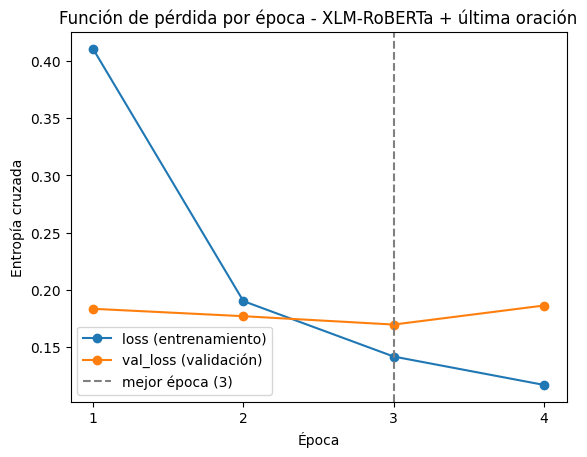

              precision    recall  f1-score   support

    negativo      0.815     0.943     0.874       738
     neutral      1.000     1.000     1.000       560
    positivo      0.934     0.789     0.855       749

    accuracy                          0.902      2047
   macro avg      0.916     0.911     0.910      2047
weighted avg      0.909     0.902     0.902      2047



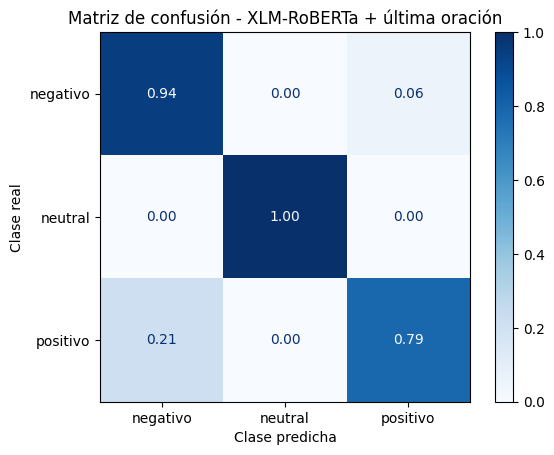

,accuracy,resenas
idioma,,
es_en,0.818182,33
fr,0.857143,210
pt_br,0.896996,233
es,0.908751,1337
en,0.923077,234


200 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
16277,es,positivo,negativo,"Lo compré en una oferta que vi por ahí y llevo un par de meses usándolo casi todos los días en la oficina. La app del fabricante me funciona de maravilla, la uso con los ojos cerrados. Eso sí, la conexión me dio más de un dolor de cabeza, sobre todo las primeras semanas cuando intentaba vincularlo en la casa de mi hermana."
4319,fr,positivo,negativo,"Le chargeur tient vraiment ses promesses côté autonomie, il m'a dépanné deux jours complets en voyage, et il recharge vite. Mais il pèse lourd dans le sac, on le sent tout de suite, et le câble fourni semble fragile après quelques semaines. Je ne sais pas si l'encombrement compense ce qu'il apporte, ça dépend vraiment de l'usage de chacun et j'hésite encore."
20003,es,positivo,negativo,"La compré hace un par de semanas por internet y me llegó en tres días. La uso para el gimnasio, la llevo en la mochila a diario. La tapa no vale lo que cuesta, la verdad. Por otro lado, recomiendo la conexión con los ojos cerrados. Lo dejo a tu criterio."
8489,es,positivo,negativo,"Me llegó a mediados de mes, lo compré en línea y tardó como cuatro días en llegar. La verdad, el acabado no vale lo que cuesta. Aun así lo he estado usando todos los días en la oficina, porque la señal superó todas mis expectativas. La verdad tengo sentimientos encontrados."
4913,es,negativo,positivo,"Compré esto a mediados de año porque andaba necesitando uno para la casa de mi hermana, llegó en unos cuatro días. La verdad, cada peso que pagué por la señal valió la pena. Eso sí, el diseño no es para nada lo que esperaba. Yo lo conecto en la sala y mi hermana lo usa en su cuarto, y los dos coincidimos en que ni tan bueno ni tan malo."
19836,es,positivo,negativo,"Me llego el miercoles por la tarde, dos dias despues de pedirlo, en una caja sencilla. Lo uso en el escritorio de la casa, mas que nada por las tardes. La comodidad esta muy por debajo de la media, la verdad. Por otro lado, el menu de ajustes respondio tal como esperaba. Sopesalo tu mismo."
4538,es,positivo,negativo,"Compré esto a mediados de año por internet y llegó en unos días sin contratiempos. La batería me hizo la vida más fácil desde que empecé a usarla en mis salidas cotidianas. Eso sí, con la resistencia al agua no paré de tener problemas desde el primer mes. Así que ahí lo dejo."
3718,pt_br,negativo,positivo,"A fritadeira elétrica sem óleo esquenta rápido e as batatas ficam crocantes de verdade, o que eu gostei bastante. Por outro lado, o cesto é pequeno demais para uma família, acabei fazendo dois lotes no mesmo jantar. O painel é simples, mas o barulho incomoda um pouco. Fico em dúvida se o espaço que ela ocupa na bancada compensa, ainda não me decidi sobre ficar com ela."
5455,es,positivo,negativo,"Compré esto en línea y me llegó en unos cinco días, en su caja tal cual. La uso en casa casi a diario desde que la recibí. La verdad no pare de tener problemas con el sonido desde el primer día que la prendí. Eso sí, la cámara me hizo la vida mas facil para lo que la necesito. Queda a criterio de cada uno, yo nomás cuento mi experiencia."
12570,es,negativo,positivo,"Compre este microfono un sabado por la tarde en una tienda cerca de mi casa, me lo llevaron en la moto y llegue antes de que cerrara. Cada peso que pague por el microfono valio la pena. Por otro lado, el control remoto me dio mas de un dolor de cabeza, lo tuve que estar configurando un rato esa misma noche. La verdad, ni lo mejor ni lo peor, ahi lo dejo."


,modelo,mejor_epoca,val_accuracy,val_loss,train_accuracy
0,XLM-RoBERTa,3,0.899853,0.169989,0.914708
1,XLM-RoBERTa+ última oración,3,0.902296,0.169566,0.920571


In [58]:
errores_roberta_ultima = evaluar_modelo_validacion(
    roberta_ultima.clases_test,
    test_df,
    "XLM-RoBERTa + última oración",
    repo_historial=f"{USUARIO_HF}/proyecto-ml-{roberta_ultima.nombre_corto}",
)

# Comparación con el mismo modelo sin la última oración
resumir_historiales(
    {
        "XLM-RoBERTa": xlm_roberta.historial,
        "XLM-RoBERTa+ última oración": roberta_ultima.historial,
    }
)

### 4.6 - RoBERTa Large

Finalmente entrenaremos el transformer RoBERTa Large sobre los datos sin aumentar. Asimismo, entrenaremos RoBERTa large con todos los datos de train, pues es probable que este sea el candidato al mejor modelo.

In [59]:
xlm_roberta_large = entrenar_transformer(nombre_modelo="xlm-roberta-large", nombre_corto="XLM-RoBERTa-large", train_df=train_df, test_df=test_df, dataset_eval=dataset_eval)

config.json:   0%|          | 0.00/970 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

XLM-RoBERTa-large cargado de Hugging Face (mejor época: 3, val_loss = 0.1510, val_accuracy = 0.9013)
submission_XLM-RoBERTa-large.csv ya existe en Hugging Face; no se vuelve a crear


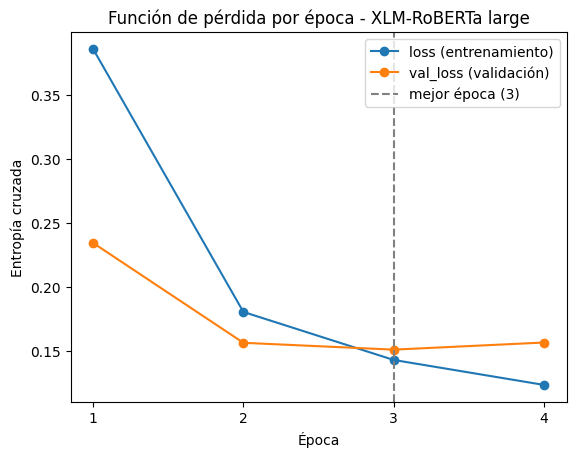

              precision    recall  f1-score   support

    negativo      0.931     0.786     0.852       738
     neutral      1.000     0.998     0.999       560
    positivo      0.816     0.943     0.875       749

    accuracy                          0.901      2047
   macro avg      0.916     0.909     0.909      2047
weighted avg      0.908     0.901     0.901      2047



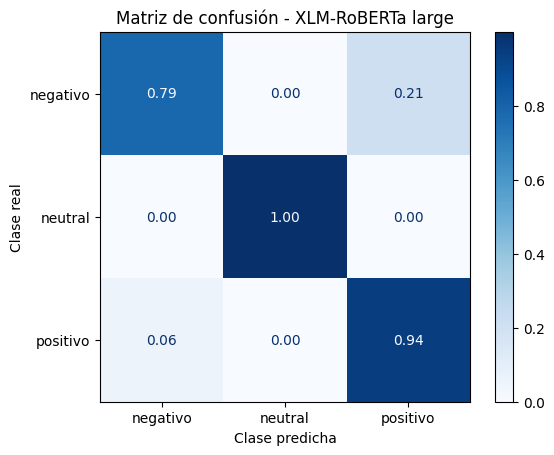

,accuracy,resenas
idioma,,
es_en,0.757576,33
fr,0.880952,210
en,0.884615,234
es,0.903515,1337
pt_br,0.944206,233


202 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
9278,es,negativo,positivo,"Me llegó el jueves por la tarde, lo compré para el cuarto de mi hermana porque necesitábamos uno ahí. La calidad se dañó antes de lo que esperaba, la verdad. Eso sí, la pantalla táctil la recomiendo con los ojos cerrados, para lo que la usamos va sobrada. No sabría bien qué recomendar, la neta."
8149,es,negativo,positivo,"Lo pedi a mediados de mes y me llego en tres dias a la casa. Me arrepiento de haber elegido la instalacion. La use ya un par de semanas en la oficina, nada fuera de lo comun. Ademas, el sistema de carga respondio tal como esperaba. Sopesalo tu mismo."
2736,es,negativo,positivo,"Compré este reloj digital hace unas tres semanas por internet, llegó en cinco días a mi casa aquí en Guadalajara. La verdad terminé harto de la resistencia al agua. Por otro lado, estoy feliz con la atención al cliente, me contestaron rápido cuando escribí a preguntar algo. La neta tengo sentimientos encontrados con esto."
9585,es,negativo,positivo,"Despues de varias semanas, se lo compre a un familiar. Me enanto la memoria de principio a fin. Por otro lado, la pantalla tactil se queda muy corto. Ni lo mejor ni lo peor."
7513,es,negativo,positivo,"Lo pedi a mediados de mes y llego en cuatro dias a mi casa en Guadalajara. Me decepciono el teclado de principio a fin. Lo uso en la oficina para trabajar con hojas de calculo la mayor parte del dia. Ademas, me encanto el rendimiento de principio a fin. Hay de todo, como se ve."
10001,fr,negativo,positivo,"La friteuse à air cuit vraiment vite et les frites sortent croustillantes avec presque pas d'huile, ce qui est appréciable. Par contre, le panier est petit et il faut cuire en plusieurs fois pour une famille, et le bruit est constante pendant la cuisson. Je ne sais pas encore si je m'en sers plus souvent que mon four, l'avenir me le dira."
9342,en,negativo,positivo,"It arrived Monday afternoon, two days after I ordered it, in a box that was pretty big for what it was. I don't have a single complaint about portability, I carry it back and forth around the office with no problem. The processor falls way short. Honestly, I have mixed feelings about this one."
14868,es,positivo,negativo,"Hace un par de semanas se lo compré a un familiar, por ahí de mediados de mes, y me llegó sin problemas. La verdad, el material me dio más de un dolor de cabeza desde los primeros días. Ahora, con la tapa estoy feliz, la uso todos los días en la oficina. Nada más eso puedo decir por ahora."
9477,fr,negativo,positivo,"Je voulais vous raconter mon expérience avec cet achat, au cas où ça pourrait servir. Je l'ai commandé un lundi et il est arrivé chez moi le jeudi, dans son emballage scellé et sans aucun dommage. Pour la durée de la charge, je ne donnerais qu'une étoile, honnêtement je suis déçu. Par contre, l'envoi a été une réussite totale, car il est arrivé avant ce qu'indiquait le site. Je l'utilise au bureau tous les jours depuis. Chacun ses goûts, chacun tirera ses conclusions."
267,pt_br,negativo,positivo,"Comprei no começo do ano numa loja da internet e chegou em três dias. Levo pra todo lugar. Sinceramente, me arrependi de ter comprado a resistência à água. Uso principalmente de manhã quando saio pra caminhar e de vez em quando pra ligações. Além disso, a conexão atende de sobra. Não saberia bem o que recomendar."


In [60]:
errores_roberta_large = evaluar_modelo_validacion(
    xlm_roberta_large.clases_test,
    test_df,
    "XLM-RoBERTa large",
    repo_historial=f"{USUARIO_HF}/proyecto-ml-{xlm_roberta_large.nombre_corto}",
)

### 4.7 - Modelo de ensemble con RoBERTa

Vemos que todos los modelos tienen distintos desempeños en distintas reseñas, y que los transformers tienen desempeño distinto en distintos idiomas. Por ejemplo RoBERTa tiene un muy buen desempeño en inglés (0.9102564102564102) y uno menor en reseñas de español-inglés (0.7878787878787878) mientras que RoBERTa tiene un muy buen desempeño en reseñas de español-inglés y un peor desempeño en reseñas en inglés (0.8888888888888888). La idea es combinar y ajustar los pesos según idioma a un modelo de ensamble 


El ensamble combina los tres RoBERTa (4.2, 4.3 y 4.5) con votación suave ponderada por idioma:

1. Cada modelo da la probabilidad de cada clase (softmax de sus logits) para cada reseña.
2. El peso de cada modelo en una reseña es su accuracy en `test_df` en el idioma de esa reseña (columna `idioma`
   de la sección 2).
3. La predicción es la clase con mayor promedio ponderado de probabilidades.

Dos detalles:

-  En `test_df` hay solo 33 reseñas `es_en`, así que un solo error mueve su accuracy 3
  puntos. Para que el peso no dependa de unas pocas reseñas, el accuracy de cada idioma se suaviza hacia el accuracy
  global del modelo, como si cada idioma tuviera `PREVIA` reseñas adicionales con el accuracy global. Los idiomas
  que no aparecen en `test_df` (p. ej. reseñas sin idioma identificado) usan directamente el accuracy global.
- Los pesos se calculan con `test_df`, así que medir el ensamble en ese mismo `test_df`
  sobreestimaría su accuracy. Lo evaluamos con validación cruzada: `test_df` se divide en 5 partes, los pesos se
  calculan con 4 y el ensamble se evalúa en la quinta, rotando las 5 partes. El submission final usa los pesos
  calculados con todo `test_df`.

In [ ]:
import numpy as np

# Los tres RoBERTa del ensamble. Sus probabilidades en test_df y dataset_eval ya las calculó
# entrenar_transformer (probs_test y probs_eval), así que no hace falta volver a cargar los modelos.
modelos_ensamble = {
    "XLM-RoBERTa": xlm_roberta,
    "XLM-RoBERTa-Twitter": twitter,
    "XLM-RoBERTa_ultima": roberta_ultima,
}

probs_test = {nombre: r.probs_test for nombre, r in modelos_ensamble.items()}
probs_eval = {nombre: r.probs_eval for nombre, r in modelos_ensamble.items()}

In [ ]:
PREVIA = 50  # reseñas "imaginarias" con el accuracy global que se suman a cada idioma al suavizar


def pesos_por_idioma(probs, df, previa=PREVIA):
    """Tabla idioma x modelo con el accuracy (suavizado) de cada modelo en cada idioma de `df`.

    El accuracy de cada idioma se suaviza hacia el accuracy global del modelo, como si el idioma
    tuviera `previa` reseñas más con el accuracy global; así los idiomas con pocas reseñas no
    dependen de unos pocos aciertos. La fila "otro" es el accuracy global, para los idiomas que
    no aparecen en `df`."""
    reales = df["label"].map(etiqueta_a_id).values
    idiomas = df["idioma"].astype(str).values
    tabla = {}
    for nombre, p in probs.items():
        aciertos = pd.Series(p.argmax(axis=1) == reales)
        accuracy_global = aciertos.mean()
        por_idioma = aciertos.groupby(idiomas).agg(["sum", "size"])
        suavizado = (por_idioma["sum"] + previa * accuracy_global) / (
            por_idioma["size"] + previa
        )
        tabla[nombre] = pd.concat([suavizado, pd.Series({"otro": accuracy_global})])
    return pd.DataFrame(tabla)


def votacion_suave(probs, idiomas, pesos):
    """Clase ganadora de cada reseña: promedio de las probabilidades de los modelos, ponderado por
    el peso de cada modelo (columna de `pesos`) en el idioma de la reseña (fila de `pesos`)."""
    idiomas = pd.Series(np.asarray(idiomas)).astype(str)
    idiomas = idiomas.where(idiomas.isin(pesos.index), "otro")
    w = pesos.loc[idiomas.values]  # una fila de pesos por reseña
    total = sum(w[nombre].values[:, None] * p for nombre, p in probs.items())
    return (total / w.sum(axis=1).values[:, None]).argmax(axis=1)


# Pesos calculados con todo test_df (son los que usa el submission final)
pesos_por_idioma(probs_test, test_df)

,XLM-RoBERTa,XLM-RoBERTa-Twitter,XLM-RoBERTa_ultima
en,0.908425,0.890819,0.919418
es,0.907709,0.899057,0.908518
es_en,0.855333,0.903526,0.868853
fr,0.853818,0.884587,0.865826
pt_br,0.908101,0.925769,0.897932
otro,0.899853,0.899853,0.902296


#### Evaluación del ensamble

Comparamos, sobre `test_df`, cada RoBERTa por separado, la votación suave con pesos iguales (no se ajusta nada, así
que no necesita validación cruzada) y la votación suave con pesos por idioma evaluada con validación cruzada. Como en
la sección 3.2, con ~2.000 reseñas el error estándar del accuracy es de casi 1 punto.

,accuracy en test_df
"Votación suave, pesos por idioma (validación cruzada)",0.905227
"Votación suave, pesos iguales",0.905227
XLM-RoBERTa_ultima,0.902296
XLM-RoBERTa,0.899853
XLM-RoBERTa-Twitter,0.899853


              precision    recall  f1-score   support

    negativo      0.833     0.921     0.875       738
     neutral      1.000     1.000     1.000       560
    positivo      0.914     0.818     0.863       749

    accuracy                          0.905      2047
   macro avg      0.916     0.913     0.913      2047
weighted avg      0.908     0.905     0.905      2047



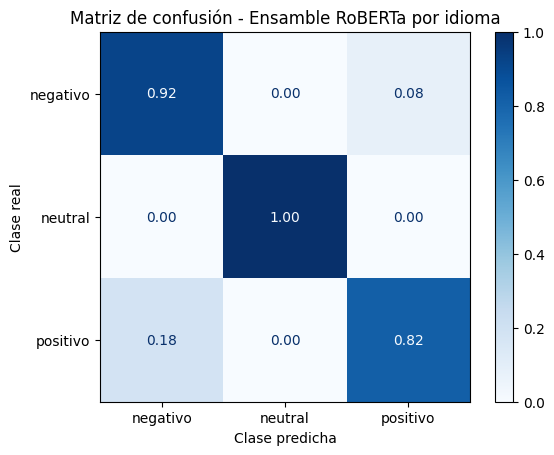

,accuracy,resenas
idioma,,
es_en,0.787879,33
fr,0.880952,210
pt_br,0.905579,233
es,0.909499,1337
en,0.918803,234


194 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
18792,fr,positivo,negativo,"La valise est tres legere et roule bien dans les aeroports, ce qui change tout sur les longues correspondances. En revanche, la fermeture eclair coince presque a chaque ouverture et le compartiment principal semble un peu juste quand je remplis tout. J'ai toujours du mal a dire si le confort de transport compense ces tracas du quotidien, honnetement je ne sais pas encore si je la garderai."
7233,es,negativo,positivo,"Lo pedi a mediados de mes y llego en tres dias, justo cuando lo necesitaba paar la laptop de mi hermano. El envio es justo lo que estaba buscando. Ya con el producto en casa empece a probarlo esos dias haciendo trabajo de oficina. Por otro lado, la memoria funciona bastante mal. Sigo con dudas, la verdad."
5882,fr,positivo,negativo,"Le colis m'est arrivé un mardi, si je me souviens bien trois jours après l'avoir commandé, et je l'ai ouvert dès que le livreur a apporté la boîte. Je recommande le matériel les yeux fermés et le matériel m'a déçu au plus haut point. Je l'ai examiné tranquillement ce même après-midi sur la table de la salle à manger. Des goûts et des couleurs, on ne discute pas."
14910,es,negativo,positivo,"Pedí esto a mediados de mes y me llegó en cuatro días a casa, en caja sellada. La atención al cliente se queda muy corta porque tardaron en responderme cuando escribí por el chat de la página. El paquete traía el manual y los papeles de garantía por un año. El material está por encima de la media, se nota al tocarlo. Todavía no me decido si me quedo con él."
5486,es,positivo,negativo,"Llevo ya un buen rato usándolo y lo tengo en la oficina desde que llegó, el envío tardó como cuatro días. Estoy feliz con el peso, la verdad se siente bien en la mano. Eso sí, el sistema de carga funciona bastante mal. Ni lo mejor ni lo peor."
18276,en,negativo,positivo,"I ordered it on a Tuesday and it arrived by Friday, in its sealed box. I bought it because I was redoing a few things in the living room. The remote control was a purchase mistake. Other than that, the quality is exactly what I was looking for. It has a bit of everything, as you can see in the listing photos."
6264,es,negativo,positivo,"La compre a mediados de mes y me llego en cuatro dias en caja sellada. La instalacion vale totalmente la pena, la hice yo solo en la cocina sin problema. La uso todos los dias desde que llego. Por otro lado, la portabilidad no es para nada lo que esperaba, y eso que la habia medido antes. Ni tan bueno ni tan malo."
8660,fr,positivo,negativo,"Le son sur les basses est franchement impressionnant pour ce prix, et la batterie tient vraiment la semaine. Mais les aigus grincent un peu quand je monte le volume, et le plastique fait cheap sous la main. Les deux défauts m'agacent autant que les qualités me plaisent, honnêtement je ne sais pas encore si je le garde."
12825,fr,positivo,negativo,"Je l'ai commandé à la mi-mois et c'est arrivé en quatre jours environ, la boîte était bien fermée. Le rapport qualité-prix m'a donné plus d'un mal de tête. Au passage, le rapport qualité-prix m'a surpris en bien. À chacun de juger."
19836,es,positivo,negativo,"Me llego el miercoles por la tarde, dos dias despues de pedirlo, en una caja sencilla. Lo uso en el escritorio de la casa, mas que nada por las tardes. La comodidad esta muy por debajo de la media, la verdad. Por otro lado, el menu de ajustes respondio tal como esperaba. Sopesalo tu mismo."


In [63]:
from sklearn.model_selection import StratifiedKFold

reales_test = test_df["label"].map(etiqueta_a_id).values
idiomas_test = test_df["idioma"].astype(str).values


def evaluar_ensamble(probs_test, nombre):
    """Compara sobre `test_df` cada modelo de `probs_test` por separado, la votación suave con pesos
    iguales y la votación suave con pesos por idioma, y analiza los errores de esta última.

    Los pesos por idioma se calculan con `test_df`, así que se evalúan con validación cruzada: se
    calculan con 4/5 de `test_df` y se evalúan en el 1/5 restante. Las partes se estratifican por
    idioma para que todas tengan reseñas de cada idioma. Devuelve la tabla de accuracy, las clases
    predichas en `test_df` (validación cruzada) y las reseñas mal clasificadas."""
    clases_cv = np.empty(len(test_df), dtype=int)
    partes = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for idx_pesos, idx_evaluar in partes.split(test_df, idiomas_test):
        pesos = pesos_por_idioma(
            {n: p[idx_pesos] for n, p in probs_test.items()}, test_df.iloc[idx_pesos]
        )
        clases_cv[idx_evaluar] = votacion_suave(
            {n: p[idx_evaluar] for n, p in probs_test.items()},
            idiomas_test[idx_evaluar],
            pesos,
        )

    # Con una sola fila "otro" de unos, todos los modelos pesan lo mismo en todos los idiomas
    pesos_iguales = pd.DataFrame(1.0, index=["otro"], columns=list(probs_test))

    comparacion = pd.Series(
        {
            **{n: (p.argmax(axis=1) == reales_test).mean() for n, p in probs_test.items()},
            "Votación suave, pesos iguales": (
                votacion_suave(probs_test, idiomas_test, pesos_iguales) == reales_test
            ).mean(),
            "Votación suave, pesos por idioma (validación cruzada)": (
                clases_cv == reales_test
            ).mean(),
        },
        name="accuracy en test_df",
    )
    display(comparacion.sort_values(ascending=False).to_frame())

    errores = evaluar_modelo_validacion(clases_cv, test_df, nombre)
    return SimpleNamespace(comparacion=comparacion, clases_test=clases_cv, errores=errores)


ensamble_base = evaluar_ensamble(probs_test, "Ensamble RoBERTa por idioma")

Vemos que en este caso, no mejoró el accuracy al distinguir por idioma, y que el ensable funciona igual de bien de una u otra forma. Esto nos sugiere que el verdadero problema viene de que algunos idiomas están subrepresentados en los datos, pese a que nuestra división train/test está estratificada por idioma. 

Queda ver qué podemos ganar al introducir técnicas de aumentación de datos para que todos los idiomas estén correctamente representados.

#### Submission del ensamble

Para `dataset_eval` usamos los pesos calculados con todo `test_df` y el idioma identificado en la sección 2.

In [64]:
def subir_submission_ensamble(probs_test, probs_eval, archivo_salida):
    """Sube el submission del ensamble con votación suave ponderada por idioma. Los pesos se
    calculan con todo `test_df` y el idioma de cada reseña de `dataset_eval` es el identificado en
    la sección 2."""
    pesos = pesos_por_idioma(probs_test, test_df)
    clases_eval = votacion_suave(probs_eval, dataset_eval["idioma"], pesos)
    return subir_submission(clases_eval, dataset_eval, archivo_salida)


submission_ensamble = subir_submission_ensamble(
    probs_test, probs_eval, "submission_ensamble_RoBERTa_idioma.csv"
)

submission_ensamble_RoBERTa_idioma.csv ya existe en Hugging Face; no se vuelve a crear


### 4.8 -  Ensamble RoBERTa-large

Repetimos el ensamble de la sección 4.7 agregando XLM-RoBERTa large (4.6) a los tres RoBERTa base, con las mismas
funciones: `evaluar_ensamble` compara en `test_df` cada modelo, la votación suave con pesos iguales y la votación suave
con pesos por idioma (con validación cruzada), y `subir_submission_ensamble` sube el submission con los pesos
calculados con todo `test_df`.

Large tiende a inclinarse hacia positivo en las reseñas dudosas (predice 48 % de positivas en `dataset_eval`) y
XLM-RoBERTa hacia negativo (36 %), así que al promediar sus probabilidades esos sesgos pueden compensarse.

,XLM-RoBERTa,XLM-RoBERTa-Twitter,XLM-RoBERTa_ultima,XLM-RoBERTa-large
en,0.908425,0.890819,0.919418,0.887556
es,0.907709,0.899057,0.908518,0.903436
es_en,0.855333,0.903526,0.868853,0.844168
fr,0.853818,0.884587,0.865826,0.884869
pt_br,0.908101,0.925769,0.897932,0.936629
otro,0.899853,0.899853,0.902296,0.901319


,accuracy en test_df
XLM-RoBERTa_ultima,0.902296
"Votación suave, pesos iguales",0.901808
XLM-RoBERTa-large,0.901319
"Votación suave, pesos por idioma (validación cruzada)",0.901319
XLM-RoBERTa-Twitter,0.899853
XLM-RoBERTa,0.899853


              precision    recall  f1-score   support

    negativo      0.840     0.897     0.868       738
     neutral      1.000     1.000     1.000       560
    positivo      0.891     0.832     0.860       749

    accuracy                          0.901      2047
   macro avg      0.910     0.910     0.909      2047
weighted avg      0.903     0.901     0.901      2047



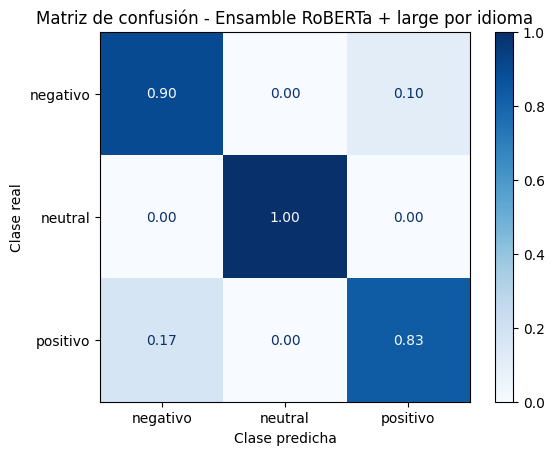

,accuracy,resenas
idioma,,
es_en,0.818182,33
fr,0.866667,210
es,0.904263,1337
pt_br,0.914163,233
en,0.914530,234


202 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
19512,es,positivo,negativo,Lo pedi un martes por la app del sitio y llego el jueves a mi casa. La relacion calidad-precio supero todas mis expectativas. Aun asi quede muy molesto con la aplicacion. La verdad no se con que quedarme.
8660,fr,positivo,negativo,"Le son sur les basses est franchement impressionnant pour ce prix, et la batterie tient vraiment la semaine. Mais les aigus grincent un peu quand je monte le volume, et le plastique fait cheap sous la main. Les deux défauts m'agacent autant que les qualités me plaisent, honnêtement je ne sais pas encore si je le garde."
8295,es,positivo,negativo,"Compré esto hace un mes más o menos por internet y me llegó en tres días. Lo uso a diario desde entonces, en las tardes después del trabajo. La resistencia al agua no volvería a comprarla ni regalado. El sistema de sonido, en cambio, me dejó encantado. Todavía no me decido."
9477,fr,negativo,positivo,"Je voulais vous raconter mon expérience avec cet achat, au cas où ça pourrait servir. Je l'ai commandé un lundi et il est arrivé chez moi le jeudi, dans son emballage scellé et sans aucun dommage. Pour la durée de la charge, je ne donnerais qu'une étoile, honnêtement je suis déçu. Par contre, l'envoi a été une réussite totale, car il est arrivé avant ce qu'indiquait le site. Je l'utilise au bureau tous les jours depuis. Chacun ses goûts, chacun tirera ses conclusions."
19360,pt_br,negativo,positivo,"Comprei o relógio inteligente mês passado pra acompanhar os treinos na academia, meu filho foi quem me convenceu. A bateria dura quase uma semana inteira, digo, durou uma semana até eu tirar do carregador pela primeira vez. A tela responde rapidinho, respondia, até dar uma tela preta na quarta. Sábado lavei a louça com ele no pulso e nada aconteceu com a louça. A verdade é que ele virou parte da rotina da gaveta."
12825,fr,positivo,negativo,"Je l'ai commandé à la mi-mois et c'est arrivé en quatre jours environ, la boîte était bien fermée. Le rapport qualité-prix m'a donné plus d'un mal de tête. Au passage, le rapport qualité-prix m'a surpris en bien. À chacun de juger."
39,es,positivo,negativo,"Hace un par de semanas lo pedi porque lo necesitaba para el trabajo, me llego en unos tres dias a la oficina. Me alegra haber elegido la ergonomia. Lo uso todos los dias en el escritorio junto a la laptop. De paso, la app del fabricante no vale lo que cuesta."
16576,fr,negativo,positivo,"Le micro est arrivé un mardi avec la livraison standard, sans souci. Le micro est au-dessus de la moyenne. La mémoire m'a déçu sur toute la ligne, je l'ai utilisée deux semaines. Bref, ni bien ni mal."
7487,en,negativo,positivo,"The air fryer crisps up frozen fries surprisingly well and preheats faster than I expected. On the other hand, the basket is smaller than the listing suggested, so I'm cooking dinner in two batches now. The nonstick coating already shows scratches after a month, yet cleanup is still easier than my old oven pan. Some days I reach for it constantly, other weeks it just sits there. Honestly I still haven't decided whether it earned its counter space or not."
9307,fr,negativo,positivo,"La batterie tient vraiment la charge comme promis, mon telephone est passe de vingt a quatre-vingt pour cent en une heure et demie, ce qui m'a sauve plusieurs fois en deplacement. En revanche elle pese lourd dans le sac et chauffe assez pendant la charge. Je ne sais pas encore si je la garde ou si je continue a chercher autre chose."


submission_ensamble_RoBERTa_large_idioma.csv  ya existe en Hugging Face; no se vuelve a crear


In [65]:
# Los tres RoBERTa base de la sección 4.7 más XLM-RoBERTa large (4.6). Sus probabilidades ya las
# calculó entrenar_transformer, así que no hace falta volver a cargar ningún modelo.
probs_test_large = {**probs_test, "XLM-RoBERTa-large": xlm_roberta_large.probs_test}
probs_eval_large = {**probs_eval, "XLM-RoBERTa-large": xlm_roberta_large.probs_eval}

# Pesos de cada modelo en cada idioma, calculados con todo test_df (los que usa el submission)
display(pesos_por_idioma(probs_test_large, test_df))

ensamble_large = evaluar_ensamble(probs_test_large, "Ensamble RoBERTa + large por idioma")

submission_ensamble_large = subir_submission_ensamble(
    probs_test_large, probs_eval_large, "submission_ensamble_RoBERTa_large_idioma.csv "
)

### 4.10 - mDeBERTa-v3-base

Todos los transformers anteriores, salvo mBERT, son variantes de XLM-RoBERTa, y en la sección 4.9 vimos que se equivocan
prácticamente en las mismas reseñas. Probamos `microsoft/mdeberta-v3-base` es decir, una familia distinta.

- DeBERTa separa el contenido de cada palabra de su posición, y la atención entre dos palabras combina
  ambos por separado (*disentangled attention*), en lugar de sumarlos en un solo vector como RoBERTa.
- En lugar de adivinar palabras enmascaradas, como XLM-RoBERTa, aprende a detectar qué palabras
  fueron reemplazadas por un generador (*replaced token detection*, como ELECTRA), y usa todas las palabras de la
  oración para aprender, no solo las enmascaradas.
- 12 capas y vectores de 768, como XLM-RoBERTa-base: 86 M de parámetros en el codificador más 190 M en los
  embeddings de su vocabulario de 250.000 tokens. Se preentrenó con CC100, los mismos datos multilingües que
  XLM-RoBERTa, así que la diferencia está en la arquitectura y en cómo se preentrenó.

Lo entrenamos con la misma función y los mismos parámetros que los demás transformers. mDeBERTa es inestable en float16, y su checkpoint está guardado en ese tipo: `transformers` 5 lo cargaba en float16 y
la pérdida llegaba a `NaN` desde el segundo paso de entrenamiento. Por eso `cargar_transformer` fuerza `float32`.

In [66]:
mdeberta = entrenar_transformer(nombre_modelo="microsoft/mdeberta-v3-base", nombre_corto="mDeBERTa", train_df=train_df, test_df=test_df, dataset_eval=dataset_eval)

config.json:   0%|          | 0.00/1.08k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.93k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.0MB            

tokenizer.json: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/555 [00:00<?, ?B/s]

mDeBERTa cargado de Hugging Face (mejor época: 3, val_loss = 0.1641, val_accuracy = 0.9028)
submission_mDeBERTa.csv ya existe en Hugging Face; no se vuelve a crear


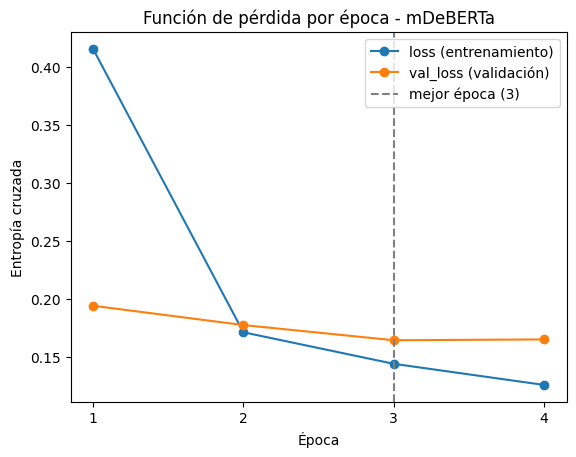

              precision    recall  f1-score   support

    negativo      0.800     0.976     0.879       738
     neutral      1.000     0.996     0.998       560
    positivo      0.968     0.761     0.852       749

    accuracy                          0.903      2047
   macro avg      0.923     0.911     0.910      2047
weighted avg      0.916     0.903     0.902      2047



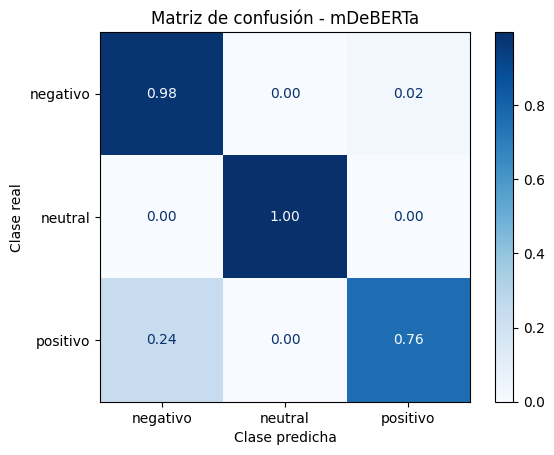

,accuracy,resenas
idioma,,
es_en,0.787879,33
fr,0.866667,210
en,0.888889,234
pt_br,0.896996,233
es,0.914734,1337


199 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
539,fr,positivo,negativo,"Je l'ai achetée à la mi-mois et elle est arrivée en trois jours chez moi, dans une boîte scellée. Sans trop de complications. J'ai été très agacé par l'autonomie. Par contre, la construction m'a surpris positivement. Je l'utilise presque tous les jours au bureau pendant que je travaille. Je vous laisse juger."
2416,pt_br,positivo,negativo,"Há umas duas semanas, comprei de um familiar. Eu daria cinco estrelas no motor. Além disso, o som me decepcionou muito. No fim das contas, nem bom nem ruim."
16579,es,positivo,negativo,"El teclado mecanico llega bien embalado y los switches suenan ricos al escribir, se siente solido sobre el escritorio. Eso si, las teclas tienen un brillo que se marca demasiado con los dedos y el cable no se desmonta, algo molesto si uno viaja. A veces dudo si el sonido compensa el peso de las manchas, otras veces pienso que no. Lo he dejado montado y desmontado varias veces sin decidirme aun."
11640,pt_br,positivo,negativo,"Pedi num domingo e chegou na quarta-feira, na caixa lacrada. Uso principalmente na sala à noite. Estou feliz com a nitidez da imagem. Aliás, fiquei bem irritado com o botão de ligar."
2440,es,positivo,negativo,"Me llego el pedido en unos cuatro dias a la casa, lo compre un martes por la noche sin apuro. Escribo con calma mi opinion. Le pondria una estrella a la ergonomia. La resistencia al agua supero todas mis expectativas. Ni tan bueno ni tan malo, la verdad ando todavia pensandolo."
8489,es,positivo,negativo,"Me llegó a mediados de mes, lo compré en línea y tardó como cuatro días en llegar. La verdad, el acabado no vale lo que cuesta. Aun así lo he estado usando todos los días en la oficina, porque la señal superó todas mis expectativas. La verdad tengo sentimientos encontrados."
341,en,positivo,negativo,"I've been using it at home ever since I bought it. I don't have a single complaint about the motor. That said, the resolution really let me down big time. I honestly wouldn't know what to recommend."
14522,es,positivo,negativo,"El parlante bluetooth suena bastante bien para el precio, con graves que sorprenden en una pieza tan chica, y la batería me duró el fin de semana entero. Ahora, a veces se desconecta solo cuando me alejo al cuarto de al lado, aunque vuelve a conectar al rato, y el botón de volumen me costó entenderlo. La construcción se siente sólida pero la funda que trae es de plástico delgado. No me molesta tenerlo ni me entusiasma, la verdad sigue sin decidirme del todo."
10365,es,positivo,negativo,"Hace un par de semanas, lo pruebo casi todos los días. El cable defraudó todas mis expectativas. Por cierto, quedé encantado con la funda."
17811,es,positivo,negativo,"Les cuento cómo me fue. La pedí a mediados de mes y llegó en tres días a casa. Volvería a comprar la interfaz sin pensarlo. La instalé el fin de semana en la computadora del escritorio, con ayuda de mi hermano, aunque no paré de tener problemas con la instalación. Así que ahí lo dejo."


In [67]:
errores_mdeberta = evaluar_modelo_validacion(
    mdeberta.clases_test,
    test_df,
    "mDeBERTa",
    repo_historial=f"{USUARIO_HF}/proyecto-ml-{mdeberta.nombre_corto}",
)

#### Comparación con XLM-RoBERTa

Además de comparar sus métricas, vemos si mDeBERTa se equivoca en reseñas distintas que XLM-RoBERTa: si sus errores
coinciden casi por completo, combinarlos tampoco ayudaría.

In [68]:
display(
    resumir_historiales(
        {
            "XLM-RoBERTa": xlm_roberta.historial,
            "XLM-RoBERTa-large": xlm_roberta_large.historial,
            "mDeBERTa": mdeberta.historial,
        }
    )
)

# Reseñas de test_df según qué modelo acierta
acierta_xlm = pd.Series(xlm_roberta.clases_test == reales_test, name="XLM-RoBERTa acierta")
acierta_mdeberta = pd.Series(mdeberta.clases_test == reales_test, name="mDeBERTa acierta")
display(pd.crosstab(acierta_xlm, acierta_mdeberta, margins=True, margins_name="total"))
print(
    f"Errores de mDeBERTa que XLM-RoBERTa no comete: {(~acierta_mdeberta & acierta_xlm).sum()}; "
    f"errores de XLM-RoBERTa que mDeBERTa no comete: {(~acierta_xlm & acierta_mdeberta).sum()}; "
    f"errores de ambos: {(~acierta_xlm & ~acierta_mdeberta).sum()}"
)

,modelo,mejor_epoca,val_accuracy,val_loss,train_accuracy
0,XLM-RoBERTa,3,0.899853,0.169989,0.914708
1,XLM-RoBERTa-large,3,0.901319,0.151019,0.911613
2,mDeBERTa,3,0.902785,0.164106,0.912319


mDeBERTa acierta,False,True,total
XLM-RoBERTa acierta,,,
False,143,62,205
True,56,1786,1842
total,199,1848,2047


Errores de mDeBERTa que XLM-RoBERTa no comete: 56; errores de XLM-RoBERTa que mDeBERTa no comete: 62; errores de ambos: 143


## 5 - Aumentación de datos

Ahora, intentaremos hacer aumentación de datos para reentrenar los datos y aumentar el accuracy, especialmente in idiomas subrepresentados (francés, español-ingles o portugués). Vemos que las reseñas neutras ya están perfectamente predichas, por lo que enfocaremos la aumentación de datos en generar reseñas positivas y negativas. 

Asimismo, como dijimos antes, los idiomas no están representados equitativamente y en el archivo de evaluación, la distribución de lenguaje no corresponde a la distribución de lenguaje en el archivo de entrenamiento.

Asimismo, la mayoría de reseñas que fallan lo hacen en reseñas mixtas, en las que en general la última oración no decide la intención de la reseña. En teoría los transformers pueden asociar la polaridad de la última oración con la intención total de la reseña, pero como los idiomas estaban subrepresentados, la identificación de esto no era suficiente.

### 5.1 - Estrategia 1: intercambio de opiniones en reseñas mixtas

Analizamos las 205 reseñas de `test_df` que XLM-RoBERTa (4.2) clasifica mal:

- Las neutras ya se predicen perfecto: todos los errores son confusiones entre positivo y negativo.
- Cuando el modelo está seguro acierta casi siempre: con probabilidad de al menos 0,95 su accuracy es 99,6 %.
- 154 de los 205 errores tienen probabilidad menor que 0,7, y en esa zona el modelo acierta solo el 51 %: es una
  moneda al aire. En `dataset_eval` el 17 % de las reseñas cae en esa zona (15 % en `test_df`).

Esas reseñas son casi siempre mixtas. Para saber qué decide su etiqueta, puntuamos cada oración por separado con XLM-RoBERTa y nos quedamos con las reseñas que tienen exactamente una
opinión positiva y una negativa.


El modelo tiende a asociar aspectos y palabras con una etiqueta en lugar de fijarse en la posición y el conector. Para enseñarle la regla generamos pares contrafactuales. Es decir, tomamos una reseña mixta, intercambiamos sus
dos opiniones dejando cada conector en su lugar e invertimos la etiqueta.

**Original (negativo, abreviada):** _El cargador es justo lo que estaba buscando. Eso sí, la señal no vale lo que cuesta._

 **Intercambiada (positivo, abreviada):** _La señal no vale lo que cuesta. Eso sí, el cargador es justo lo que estaba buscando._

Las dos reseñas tienen exactamente las mismas palabras y etiquetas opuestas, así que la única manera de acertar ambas
es aprender que decide la opinión que va después del conector. Para no agregar etiquetas incorrectas:

1. Una oración es una opinión si XLM-RoBERTa le da al menos 0,9 de probabilidad a positivo o a negativo
   (`UMBRAL_OPINION`).
2. Solo se usan reseñas con exactamente una opinión positiva y una negativa.
3. Solo se intercambian los pares (idioma, conector) en los que la regla se cumple al menos el 90 % de las veces en
   al menos 20 reseñas de entrenamiento (`UMBRAL_REGLA`, `MIN_RESENAS_CONECTOR`). Los conectores se comparan en
   minúsculas y sin tildes, así _eso sí_ y _eso si_ cuentan como uno.
4. Solo se intercambian reseñas cuya etiqueta cumple la regla, para no multiplicar las que se comportan como ruido.
5. Solo se usa `train_df`: `test_df` queda intacto para medir la mejora de forma honesta.


In [69]:
import re
import unicodedata
import numpy as np

# Una oración expresa una opinión si el transformer le da al menos esta probabilidad a positivo o a negativo
UMBRAL_OPINION = 0.9
# Solo se intercambian reseñas cuyo conector cumple la regla "gana la última opinión" al menos así de seguido...
UMBRAL_REGLA = 0.9
# ...medido en al menos esta cantidad de reseñas de entrenamiento
MIN_RESENAS_CONECTOR = 20


def separar_oraciones(texto):
    """Las mismas oraciones que usa `ultima_oracion` (corta después de . ! ?)."""
    return [o for o in re.split(r"(?<=[.!?])\s+", texto.strip()) if o]


def polaridad_oraciones(resultado, oraciones, batch_size=64):
    """Probabilidad (negativo, neutral, positivo) de cada oración por separado, con un transformer
    ya ajustado (el resultado de `entrenar_transformer`). El modelo se vuelve a cargar de Hugging Face
    solo para esta predicción y se libera al terminar."""
    lotes = tf.data.Dataset.from_tensor_slices(list(oraciones)).batch(batch_size)
    tokenizador, model = cargar_modelo_guardado(resultado)
    logits = PredictorTransformer(model, tokenizador).predict(lotes)
    del model
    liberar_memoria_gpu()
    return torch.softmax(torch.from_numpy(logits), dim=-1).numpy()


def separar_conector(oracion):
    """('Aun así', 'el teclado me resultó sólido.') si la oración empieza con 1 a 3 palabras
    seguidas de una coma; ('', oracion) si no."""
    m = re.match(r"^((?:[^\W\d_]+['’]?\s?){1,3}),\s+(.+)$", oracion, re.S)
    return (m.group(1).strip(), m.group(2)) if m else ("", oracion)


def normalizar_conector(conector):
    """Minúsculas y sin tildes, para que "Eso sí" y "Eso si" cuenten como el mismo conector."""
    sin_tildes = unicodedata.normalize("NFKD", conector.lower())
    return "".join(c for c in sin_tildes if not unicodedata.combining(c))


def unir_conector(conector, resto):
    """Arma la oración con el conector de esa posición, ajustando la mayúscula inicial."""
    if not conector:
        return resto[:1].upper() + resto[1:]
    if not re.match(r"^I\b", resto):  # el pronombre "I" del inglés va siempre en mayúscula
        resto = resto[:1].lower() + resto[1:]
    return f"{conector}, {resto}"


def opiniones_mixtas(df, resultado):
    """Una fila por cada reseña positiva o negativa de `df` con exactamente una oración claramente
    positiva y una claramente negativa: sus oraciones, la posición de cada opinión y el conector
    (normalizado) con que empieza la última opinión."""
    df = df[df["label"] != "neutral"]
    oraciones = df["text"].map(separar_oraciones)
    planas = [o for lista in oraciones for o in lista]
    probs = polaridad_oraciones(resultado, planas)

    filas, inicio = [], 0
    for idx, lista in oraciones.items():
        p = probs[inicio : inicio + len(lista)]
        inicio += len(lista)
        pos = [k for k in range(len(lista)) if p[k, 2] >= UMBRAL_OPINION]
        neg = [k for k in range(len(lista)) if p[k, 0] >= UMBRAL_OPINION]
        if len(pos) == 1 and len(neg) == 1:
            i, j = sorted((pos[0], neg[0]))  # i: primera opinión, j: última opinión
            filas.append(
                {
                    "indice": idx,
                    "oraciones": lista,
                    "i": i,
                    "j": j,
                    "polaridad_ultima": "positivo" if j == pos[0] else "negativo",
                    "conector": normalizar_conector(separar_conector(lista[j])[0]),
                }
            )
    mixtas = pd.DataFrame(filas).set_index("indice")
    return mixtas.join(df[["id", "label", "idioma"]])


def confiabilidad_conectores(mixtas):
    """Para cada idioma y conector de la última opinión: cuántas reseñas hay y en qué fracción
    de ellas la etiqueta coincide con la polaridad de la última opinión."""
    cumple = mixtas["label"] == mixtas["polaridad_ultima"]
    tabla = cumple.groupby(
        [mixtas["idioma"].astype(str), mixtas["conector"].replace("", "(sin conector)")]
    ).agg(resenas="size", ultima_gana="mean")
    tabla["se_intercambia"] = (tabla["resenas"] >= MIN_RESENAS_CONECTOR) & (
        tabla["ultima_gana"] >= UMBRAL_REGLA
    )
    return tabla.sort_values("resenas", ascending=False)


def intercambiar_opiniones(oraciones, i, j, conectores):
    """Intercambia las opiniones de las posiciones i < j. Los conectores se quedan en su
    posición, así "A. Aun así, B." pasa a ser "B. Aun así, A."; solo se separan como conector
    los que están en `conectores`, para no mover por error el comienzo de la opinión."""

    def partir(oracion):
        conector, resto = separar_conector(oracion)
        return (conector, resto) if normalizar_conector(conector) in conectores else ("", oracion)

    con_i, op_i = partir(oraciones[i])
    con_j, op_j = partir(oraciones[j])
    nuevas = list(oraciones)
    nuevas[i] = unir_conector(con_i, op_j)
    nuevas[j] = unir_conector(con_j, op_i)
    return " ".join(nuevas)


def generar_intercambios(mixtas, tabla):
    """Reseñas nuevas: las opiniones intercambiadas y la etiqueta invertida. Solo se usan las
    reseñas cuyo (idioma, conector) es confiable y cuya etiqueta cumple la regla, para no
    multiplicar el ruido de las que no la cumplen."""
    confiables = set(tabla.index[tabla["se_intercambia"]])
    conectores = {c for _, c in tabla.index[tabla["resenas"] >= MIN_RESENAS_CONECTOR]}
    conectores.discard("(sin conector)")

    clave = list(
        zip(
            mixtas["idioma"].astype(str),
            mixtas["conector"].replace("", "(sin conector)"),
        )
    )
    usar = mixtas[
        pd.Series(clave, index=mixtas.index).isin(confiables)
        & (mixtas["label"] == mixtas["polaridad_ultima"])
    ]
    invertir = {"positivo": "negativo", "negativo": "positivo"}
    nuevas = pd.DataFrame(
        {
            "id": usar["id"],
            "text": [
                intercambiar_opiniones(o, i, j, conectores)
                for o, i, j in zip(usar["oraciones"], usar["i"], usar["j"])
            ],
            "label": usar["label"].map(invertir),
            "idioma": usar["idioma"],
        }
    )
    nuevas["ultima"] = nuevas["text"].map(ultima_oracion)
    nuevas["origen"] = nuevas.index  # índice de la reseña original en train_df
    return nuevas.reset_index(drop=True)


# Las opiniones se detectan con el XLM-RoBERTa de la sección 4.2. Solo se usa train_df: test_df
# queda intacto para medir honestamente si la aumentación mejora el accuracy.
mixtas = opiniones_mixtas(train_df, xlm_roberta)
tabla_conectores = confiabilidad_conectores(mixtas)
print(f"{len(mixtas)} reseñas de train_df con una opinión positiva y una negativa")
display(tabla_conectores.head(20))

intercambios = generar_intercambios(mixtas, tabla_conectores)
print(
    f"{len(intercambios)} reseñas nuevas por intercambio "
    f"({len(intercambios) / len(train_df):.1%} de train_df)"
)
print(intercambios["label"].value_counts().to_dict(), intercambios["idioma"].value_counts().to_dict())

# Algunos pares (original, intercambiada) para revisar a mano
with pd.option_context("display.max_colwidth", None):
    ejemplos = intercambios.sample(5, random_state=42)
    display(
        pd.DataFrame(
            {
                "original": train_df.loc[ejemplos["origen"], "text"].values,
                "etiqueta original": train_df.loc[ejemplos["origen"], "label"].values,
                "intercambiada": ejemplos["text"].values,
                "etiqueta nueva": ejemplos["label"].values,
            }
        )
    )

# train_df + intercambios, con índices nuevos para las reseñas generadas
train_df_aumentado = pd.concat(
    [
        train_df,
        intercambios.drop(columns="origen").set_axis(
            train_df.index.max() + 1 + np.arange(len(intercambios))
        ),
    ]
)
print(f"train_df_aumentado: {len(train_df_aumentado)} reseñas")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

5584 reseñas de train_df con una opinión positiva y una negativa


resenas  ultima_gana  se_intercambia
idioma conector                                            
es     (sin conector)     1654     0.892382           False
       eso si              988     0.905870            True
       aun asi             613     0.995106            True
       con todo            306     1.000000            True
       al final            272     1.000000            True
en     (sin conector)      223     0.690583           False
pt_br  (sin conector)      207     0.811594           False
fr     (sin conector)      141     0.780142           False
es     ahora               128     0.789062           False
       por otro lado       108     0.574074           False
       de paso              78     0.551282           False
       por cierto           68     0.558824           False
pt_br  por outro lado       65     0.476923           False
es     ademas               63     0.666667           False
       sin embargo          55     0.981818            True
fr     par contre           44     0.727273           False
es_en  (sin conector)       40     0.550000           False
fr     en revanche          27     0.740741           False
en     that said            26     0.692308           False
es     ahora bien           25     0.600000           False

2159 reseñas nuevas por intercambio (11.7% de train_df)
{'positivo': 1089, 'negativo': 1070} {'es': 2159}


,original,etiqueta original,intercambiada,etiqueta nueva
0,"Lo pedí a mediados de mes y llegó en cuatro días, empacado normal. El cable resultó agradable para mi gusto, se siente bien al tacto. Lo uso en la oficina con mi laptop casi a diario. Aun así, el diseño me resultó muy limitado en general.",negativo,"Lo pedí a mediados de mes y llegó en cuatro días, empacado normal. El diseño me resultó muy limitado en general. Lo uso en la oficina con mi laptop casi a diario. Aun así, el cable resultó agradable para mi gusto, se siente bien al tacto.",positivo
1,"Hace unos meses se lo compré a un familiar, más que nada para usarlo en videollamadas y grabar notas de voz en la casa. El envío llegó en cuatro días, en caja cerrada y sin detalles. El micrófono me pareció preciso hasta ahora, incluso lo probé un domingo en la cocina con la ventana abierta. Lo encendí varias veces durante la semana, a distintas horas. Al final, el sistema de sonido se sintió defectuoso en el uso real.",negativo,"Hace unos meses se lo compré a un familiar, más que nada para usarlo en videollamadas y grabar notas de voz en la casa. El envío llegó en cuatro días, en caja cerrada y sin detalles. El sistema de sonido se sintió defectuoso en el uso real. Lo encendí varias veces durante la semana, a distintas horas. Al final, el micrófono me pareció preciso hasta ahora, incluso lo probé un domingo en la cocina con la ventana abierta.",positivo
2,"Me llegó el celular un martes por la tarde, dos días después de pedirlo. Desde que lo compré, lo uso para el gimnasio. La cámara terminó siendo poco fiable desde que lo estrené. Eso sí, el envío se mantuvo estupendo sin exagerar, y hasta el repartidor fue amable cuando trajo el paquete a la casa.",positivo,"Me llegó el celular un martes por la tarde, dos días después de pedirlo. Desde que lo compré, lo uso para el gimnasio. El envío se mantuvo estupendo sin exagerar, y hasta el repartidor fue amable cuando trajo el paquete a la casa. Eso sí, la cámara terminó siendo poco fiable desde que lo estrené.",negativo
3,"Lo pedí a inicios de mes y llegó en tres días, desde entonces lo uso para el gimnasio. Trae garantía de dos años, eso lo revisé apenas llegó el paquete. Por cierto, la correa resultó correcta a decir verdad, no tuve que pedir repuesto. Eso sí, el rendimiento se mantuvo poco fiable con el uso diario.",negativo,"Lo pedí a inicios de mes y llegó en tres días, desde entonces lo uso para el gimnasio. Trae garantía de dos años, eso lo revisé apenas llegó el paquete. Por cierto, el rendimiento se mantuvo poco fiable con el uso diario. Eso sí, la correa resultó correcta a decir verdad, no tuve que pedir repuesto.",positivo
4,"Compre esto hace un par de semanas en una tienda online y me llego a los tres dias. Ya lo uso a diario aca en la casa, casi siempre en las mananas. La atencion al cliente se mantuvo torpe la verdad, me pasaron como dos veces con una consulta que hice. Eso si, la tapa luce eficiente para lo que necesitab.",positivo,"Compre esto hace un par de semanas en una tienda online y me llego a los tres dias. Ya lo uso a diario aca en la casa, casi siempre en las mananas. La tapa luce eficiente para lo que necesitab. Eso si, la atencion al cliente se mantuvo torpe la verdad, me pasaron como dos veces con una consulta que hice.",negativo


train_df_aumentado: 20578 reseñas


In [70]:
xlm_roberta_aumentado =  entrenar_transformer(nombre_modelo="xlm-roberta-base", nombre_corto="XLM-RoBERTa_aumentado", train_df=train_df_aumentado, test_df=test_df, dataset_eval=dataset_eval)

config.json:   0%|          | 0.00/969 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/450 [00:00<?, ?B/s]

XLM-RoBERTa_aumentado cargado de Hugging Face (mejor época: 2, val_loss = 0.1752, val_accuracy = 0.8886)
submission_XLM-RoBERTa_aumentado.csv ya existe en Hugging Face; no se vuelve a crear


En general, podemos ver que esta estrategia no funcionó, y en los datos de evaluación generó un accuracy de 0.876, menor que sin aumentación, y en los datos de validación fue peor que el ensamble y los transformers sin aumentación. Asimismo, vemos que las reseñas están sesgadas a positivo, por lo que podríamos intentar mover el umbral a negativo.

### 5.2 - Estrategia 2: mover el umbral entre positivo y negativo

El modelo aumentado no distingue mejor las reseñas positivas de las
negativas. Lo que cambió fue hacia dónde se inclina en las reseñas dudosas. En `dataset_eval` pasó 1.039 reseñas de
negativo a positivo (y solo 14 al revés), 835 de ellas en la zona donde el modelo original tenía confianza menor que
0,7, y la fracción de positivas subió de 36 % a 51 %. En `test_df` el recall de negativo bajó de 0,915 a 0,730 y el de
positivo subió de 0,810 a 0,964.

Es decir, en esa zona las probabilidades de positivo y negativo son parecidas y cada entrenamiento termina inclinándose
hacia un lado de forma bastante arbitraria: XLM-RoBERTa y XLM-RoBERTa_ultima predicen más negativo; mBERT, el modelo
de Twitter y el aumentado, más positivo. Como esa zona es cerca del 17 % de `dataset_eval`, la dirección en que se
inclina el modelo mueve bastante el accuracy.

Qué dice el leaderboard. Los puntajes no corresponden a las 6.781 reseñas de `dataset_eval`: coinciden exactamente
con 1.815, 1.811 y 1.784 aciertos de 2.036 reseñas (0,89145, 0,88948 y 0,87622), es decir, el leaderboard público se
calcula con cerca del 30 % de `dataset_eval`. Eso tiene dos consecuencias:

- Con 2.036 reseñas el error estándar del accuracy es de unos 0,7 puntos (unas 14 reseñas). La diferencia entre
  XLM-RoBERTa y el ensamble (4 reseñas) está dentro del ruido.
- XLM-RoBERTa y el modelo aumentado se diferencian casi solo en las reseñas dudosas que el aumentado pasó a positivo, y
  el aumentado perdió 31 aciertos. Eso indica que en `dataset_eval` cerca del 55 % de esas reseñas son negativas. En
  `test_df` pasa lo mismo, aunque menos marcado: en la zona dudosa hay 164 negativas y 149 positivas.

No hace falta reentrenar: cambiamos solo la regla de decisión. Para cada reseña que el modelo no
predice como neutral calculamos $r = p_{pos} / (p_{pos} + p_{neg})$ y la clasificamos como positiva solo si $r$ supera
`UMBRAL_POSITIVO`, en lugar de 0,5 como hace el argmax. Las reseñas neutras no cambian, porque ya se predicen
perfecto.

Elección del umbral. La celda siguiente muestra el accuracy en `test_df` con cada umbral y lo evalúa con
validación cruzada: el umbral se elige con 4/5 de `test_df` y se mide en el 1/5 restante, para no evaluar con las
mismas reseñas con que se eligió. En las cinco partes el mejor umbral es 0,55, y el accuracy sube de 0,8999 a 0,9047.
Así que `test_df` por sí solo ya indica que conviene inclinarse hacia negativo. Elegimos 0,7, un poco más inclinado,
porque el leaderboard indica que `dataset_eval` está más cargado hacia negativo que `test_df`. Con 0,7 el accuracy en
`test_df` sigue mejorando (0,9023), y desde 0,9 empieza a empeorar (0,8945).

Esperamos que con 0,7 pasan de positivo a negativo 276 reseñas de `dataset_eval`. Unas 83 deberían caer en el
leaderboard público; si el 55 % de ellas son negativas, se ganan unos 8 aciertos y el puntaje subiría a cerca de 0,895.
Con un error estándar de 14 reseñas, el resultado puede quedar varios aciertos arriba o abajo de eso. Además, si la
competencia tiene un leaderboard privado, se calcula con el otro 70 % de `dataset_eval`, donde la proporción podría
ser distinta.

In [71]:
from sklearn.model_selection import StratifiedKFold

# Entre positivo y negativo, solo se predice positivo si p_pos / (p_pos + p_neg) supera este umbral
UMBRAL_POSITIVO = 0.7


def clases_con_umbral(probs, umbral):
    """Igual que argmax, salvo entre positivo y negativo: la reseña es positiva solo si
    p_pos / (p_pos + p_neg) > umbral. Las reseñas que el modelo predice como neutras no cambian."""
    neg, neu, pos = (etiqueta_a_id[e] for e in ("negativo", "neutral", "positivo"))
    clases = probs.argmax(axis=1)
    polares = clases != neu
    r = probs[:, pos] / (probs[:, pos] + probs[:, neg])
    clases[polares] = np.where(r[polares] > umbral, pos, neg)
    return clases


# Probabilidades de XLM-RoBERTa (4.2) que ya calculamos para el ensamble (4.7)
p_test = probs_test["XLM-RoBERTa"]
p_eval = probs_eval["XLM-RoBERTa"]
clases_argmax_eval = p_eval.argmax(axis=1)

# 1. Qué pasa con cada umbral: accuracy en test_df y predicciones de eval que cambian
umbrales = [0.5, 0.6, 0.7, 0.8, 0.9]
display(
    pd.DataFrame(
        {
            "accuracy en test_df": [
                (clases_con_umbral(p_test, u) == reales_test).mean() for u in umbrales
            ],
            "reseñas de eval que pasan a negativo": [
                (clases_con_umbral(p_eval, u) != clases_argmax_eval).sum() for u in umbrales
            ],
        },
        index=pd.Index(umbrales, name="umbral"),
    )
)

# 2. Validación cruzada: el umbral se elige con 4/5 de test_df y se evalúa en el 1/5 restante,
# para no medir el accuracy en las mismas reseñas con que se eligió el umbral
grilla = np.round(np.arange(0.5, 0.91, 0.05), 2)
clases_cv = np.empty(len(test_df), dtype=int)
umbrales_cv = []
for idx_elegir, idx_evaluar in StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
).split(p_test, reales_test):
    mejor = max(
        grilla,
        key=lambda u: (
            clases_con_umbral(p_test[idx_elegir], u) == reales_test[idx_elegir]
        ).mean(),
    )
    umbrales_cv.append(float(mejor))
    clases_cv[idx_evaluar] = clases_con_umbral(p_test[idx_evaluar], mejor)
print(
    f"Validación cruzada en test_df: accuracy {(clases_cv == reales_test).mean():.4f} "
    f"(sin mover el umbral: {(p_test.argmax(axis=1) == reales_test).mean():.4f}); "
    f"umbrales elegidos en cada parte: {umbrales_cv}"
)

# 3. Submission con el umbral elegido
clases_eval_umbral = clases_con_umbral(p_eval, UMBRAL_POSITIVO)
print(
    f"Umbral {UMBRAL_POSITIVO}: {(clases_eval_umbral != clases_argmax_eval).sum()} reseñas de "
    "eval pasan de positivo a negativo; el resto de las predicciones no cambia"
)
submission_umbral = subir_submission(
    clases_eval_umbral,
    dataset_eval,
    f"submission_XLM-RoBERTa_umbral{round(UMBRAL_POSITIVO * 10):02d}.csv",
)

,accuracy en test_df,reseñas de eval que pasan a negativo
umbral,,
0.5,0.899853,0
0.6,0.903762,211
0.7,0.902296,276
0.8,0.901319,327
0.9,0.894480,372


Validación cruzada en test_df: accuracy 0.9047 (sin mover el umbral: 0.8999); umbrales elegidos en cada parte: [0.55, 0.55, 0.55, 0.55, 0.55]
Umbral 0.7: 276 reseñas de eval pasan de positivo a negativo; el resto de las predicciones no cambia
submission_XLM-RoBERTa_umbral07.csv ya existe en Hugging Face; no se vuelve a crear


### 5.3 - Estrategia 3: traducción automática con NLLB

Los idiomas no tienen la misma proporción en `dataset_eval` que en `train_df`, que es 65 % español.
Traducimos reseñas positivas y negativas en español de `train_df` a los idiomas que faltan con
`facebook/nllb-200-distilled-600M`, un transformer seq2seq de Meta que traduce entre 200 idiomas. A diferencia de
la sección 5.1, la etiqueta no se cambia: una buena traducción conserva el sentimiento de la reseña.


1. Se traduce oración por oración (con `separar_oraciones` de 5.1) y se vuelven a unir.
2. Generamos tantas reseñas como las que le faltan a `train_df` para acercarse a la proporción de ese idioma en
   `dataset_eval`, con un tope de `MAX_POR_IDIOMA`. Las reseñas `es_en` no se generan, porque NLLB no produce texto
   que mezcle dos idiomas.
3. XLM-RoBERTa (4.2) clasifica cada traducción y se descartan las que le dan menos de
   `UMBRAL_CONSISTENCIA` a su etiqueta, porque probablemente la traducción perdió el sentido.
4. Misma proporción positivo/negativo que `train_df` en cada idioma, para no mover el sesgo de la decisión
   como pasó en 5.1.
5. Solo se aumenta `train_df`. `test_df` queda intacto para comparar de forma justa. Las traducciones se guardan en `REPO_DATOS`
   (`aumentacion/traducciones_nllb.csv`) para no volver a generarlas.

Cómo evaluar. Además del accuracy, miramos el AUC entre positivo y negativo y el accuracy con el umbral elegido
por validación cruzada (5.2). Si el accuracy sube pero el AUC no, la aumentación solo movió el sesgo, como en 5.1.

In [72]:
from transformers import AutoModelForSeq2SeqLM

NLLB = "facebook/nllb-200-distilled-600M"
CODIGO_NLLB = {"es": "spa_Latn", "en": "eng_Latn", "pt_br": "por_Latn", "fr": "fra_Latn"}
# Idiomas a los que se traduce (es_en no: NLLB no genera reseñas que mezclen dos idiomas)
IDIOMAS_DESTINO = ["en", "pt_br", "fr"]
MAX_POR_IDIOMA = 1500  # tope de reseñas traducidas por idioma, porque traducir es lento
RUTA_TRADUCCIONES = "aumentacion/traducciones_nllb.csv"
REGENERAR_TRADUCCIONES = False


@torch.no_grad()
def traducir_oraciones(oraciones, origen, destino, tokenizador, model, batch_size=32):
    """Traduce cada oración de `oraciones` del idioma `origen` a `destino` (claves de CODIGO_NLLB)."""
    tokenizador.src_lang = CODIGO_NLLB[origen]
    id_destino = tokenizador.convert_tokens_to_ids(CODIGO_NLLB[destino])
    # Ordenar por longitud reduce el padding de cada lote y acelera mucho la generación
    orden = np.argsort([len(o) for o in oraciones])
    traducidas = [None] * len(oraciones)
    for k in tqdm(range(0, len(orden), batch_size), desc=f"{origen} -> {destino}"):
        idx = orden[k : k + batch_size]
        entradas = tokenizador(
            [oraciones[i] for i in idx],
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(dispositivo)
        generado = model.generate(
            **entradas, forced_bos_token_id=id_destino, num_beams=4, max_new_tokens=160
        )
        for i, texto in zip(idx, tokenizador.batch_decode(generado, skip_special_tokens=True)):
            traducidas[i] = texto
    return traducidas


def traducir_resenas(textos, origen, destino, tokenizador, model):
    """Traduce cada reseña oración por oración y vuelve a unir sus oraciones traducidas."""
    oraciones = [separar_oraciones(t) for t in textos]
    planas = [o for lista in oraciones for o in lista]
    traducidas = iter(traducir_oraciones(planas, origen, destino, tokenizador, model))
    return [" ".join(next(traducidas) for _ in lista) for lista in oraciones]


def resenas_por_idioma(train_df, dataset_eval):
    """Cuántas reseñas traducir a cada idioma de IDIOMAS_DESTINO: las que le faltan a `train_df` para
    tener (aproximadamente) la proporción de ese idioma en `dataset_eval`, con tope MAX_POR_IDIOMA."""
    prop_train = train_df["idioma"].value_counts(normalize=True)
    prop_eval = dataset_eval["idioma"].value_counts(normalize=True)
    faltan = (prop_eval.reindex(IDIOMAS_DESTINO, fill_value=0) - prop_train.reindex(IDIOMAS_DESTINO, fill_value=0))
    return (faltan * len(train_df)).clip(lower=0).round().astype(int).clip(upper=MAX_POR_IDIOMA)


def generar_traducciones(train_df, dataset_eval):
    """Traduce reseñas positivas y negativas en español de `train_df` a cada idioma de destino. La
    muestra de cada idioma es estratificada por etiqueta, así que conserva la proporción positivo/negativo."""
    polares_es = train_df[(train_df["idioma"] == "es") & (train_df["label"] != "neutral")]
    tokenizador = AutoTokenizer.from_pretrained(NLLB)
    model = AutoModelForSeq2SeqLM.from_pretrained(NLLB).to(dispositivo).eval()

    partes = []
    for k, (destino, n) in enumerate(resenas_por_idioma(train_df, dataset_eval).items()):
        if n == 0:
            continue
        muestra = polares_es.groupby("label", group_keys=False).sample(
            frac=min(n / len(polares_es), 1), random_state=42 + k
        )
        partes.append(
            pd.DataFrame(
                {
                    "origen": muestra.index,  # índice de la reseña original en train_df
                    "id": muestra["id"].values,
                    "text": traducir_resenas(muestra["text"].tolist(), "es", destino, tokenizador, model),
                    "label": muestra["label"].values,
                    "idioma": destino,
                }
            )
        )

    del model
    liberar_memoria_gpu()
    if not partes:
        raise ValueError("A ningún idioma de IDIOMAS_DESTINO le faltan reseñas respecto a dataset_eval")
    return pd.concat(partes, ignore_index=True)


display(
    pd.DataFrame(
        {
            "train_df": train_df["idioma"].value_counts(normalize=True),
            "dataset_eval": dataset_eval["idioma"].value_counts(normalize=True),
        }
    ).round(3)
)
print("Reseñas a traducir por idioma:", resenas_por_idioma(train_df, dataset_eval).to_dict())

if not REGENERAR_TRADUCCIONES and api.file_exists(REPO_DATOS, RUTA_TRADUCCIONES, repo_type="dataset"):
    traducciones = pd.read_csv(f"hf://datasets/{REPO_DATOS}/{RUTA_TRADUCCIONES}")
    print(f"{RUTA_TRADUCCIONES} ya existe en Hugging Face; no se vuelve a traducir")
else:
    traducciones = generar_traducciones(train_df, dataset_eval)
    api.upload_file(
        path_or_fileobj=traducciones.to_csv(index=False).encode(),
        path_in_repo=RUTA_TRADUCCIONES,
        repo_id=REPO_DATOS,
        repo_type="dataset",
        commit_message="Traducciones NLLB para aumentación (sección 5.3)",
    )
    print(f"{RUTA_TRADUCCIONES} subido a https://huggingface.co/datasets/{REPO_DATOS}")

display(pd.crosstab(traducciones["idioma"], traducciones["label"]))

,train_df,dataset_eval
idioma,,
es,0.652,0.576
en,0.115,0.137
pt_br,0.114,0.136
fr,0.103,0.119
es_en,0.016,0.032


Reseñas a traducir por idioma: {'en': 408, 'pt_br': 403, 'fr': 304}
aumentacion/traducciones_nllb.csv ya existe en Hugging Face; no se vuelve a traducir


label,negativo,positivo
idioma,,
en,204,204
fr,152,152
pt_br,202,201


In [73]:
# Se descartan las traducciones a las que XLM-RoBERTa (4.2) da menos de esta probabilidad en su etiqueta
UMBRAL_CONSISTENCIA = 0.5

# Proporción de positivas entre las reseñas positivas y negativas de train_df
polares_train = train_df[train_df["label"] != "neutral"]
PROP_POSITIVO = (polares_train["label"] == "positivo").mean()


def equilibrar(df, prop_positivo, semilla=42):
    """El mayor subconjunto de `df` con la proporción `prop_positivo` de positivas entre positivas y negativas."""
    pos, neg = df[df["label"] == "positivo"], df[df["label"] == "negativo"]
    n_total = int(min(len(pos) / prop_positivo, len(neg) / (1 - prop_positivo)))
    n_pos = round(n_total * prop_positivo)
    return pd.concat(
        [pos.sample(n_pos, random_state=semilla), neg.sample(n_total - n_pos, random_state=semilla)]
    )


# 1. Filtro de consistencia (el modelo se recarga de Hugging Face solo para esta predicción)
probs_traducciones = polaridad_oraciones(xlm_roberta, traducciones["text"])
p_etiqueta = probs_traducciones[
    np.arange(len(traducciones)), traducciones["label"].map(etiqueta_a_id).values
]
consistentes = traducciones[p_etiqueta >= UMBRAL_CONSISTENCIA]

# 2. La misma proporción positivo/negativo que train_df en cada idioma
aumentadas = pd.concat([equilibrar(g, PROP_POSITIVO) for _, g in consistentes.groupby("idioma")])

display(
    pd.DataFrame(
        {
            "traducidas": traducciones["idioma"].value_counts(),
            "consistentes": consistentes["idioma"].value_counts(),
            "finales": aumentadas["idioma"].value_counts(),
            "% positivo final": aumentadas.groupby("idioma")["label"].apply(lambda s: (s == "positivo").mean()),
        }
    ).round(3)
)
print(f"% positivo entre positivas y negativas de train_df: {PROP_POSITIVO:.3f}")

# 3. train_df + traducciones, con índices nuevos para las reseñas generadas
nuevas = aumentadas.drop(columns="origen").assign(ultima=lambda d: d["text"].map(ultima_oracion))
train_df_traducido = pd.concat(
    [train_df, nuevas.set_axis(train_df.index.max() + 1 + np.arange(len(nuevas)))]
)
print(f"train_df_traducido: {len(train_df_traducido)} reseñas ({len(nuevas)} nuevas)")
display(
    pd.DataFrame(
        {
            "train_df_traducido": train_df_traducido["idioma"].value_counts(normalize=True),
            "dataset_eval": dataset_eval["idioma"].value_counts(normalize=True),
        }
    ).round(3)
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,traducidas,consistentes,finales,% positivo final
idioma,,,,
en,408,365,339,0.504
fr,304,259,240,0.504
pt_br,403,355,331,0.505


% positivo entre positivas y negativas de train_df: 0.504
train_df_traducido: 19329 reseñas (910 nuevas)


,train_df_traducido,dataset_eval
idioma,,
es,0.622,0.576
en,0.127,0.137
pt_br,0.126,0.136
fr,0.110,0.119
es_en,0.016,0.032


In [74]:
# Si se cambian las traducciones o los umbrales, hay que reentrenar: con REENTRENAR = False se carga el
# modelo que ya está en Hugging Face, aunque se haya entrenado con otro train_df_traducido.
xlm_roberta_traducido = entrenar_transformer(
    nombre_modelo="xlm-roberta-base",
    nombre_corto="XLM-RoBERTa_traducido",
    train_df=train_df_traducido,
    test_df=test_df,
    dataset_eval=dataset_eval,
)

config.json:   0%|          | 0.00/969 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/452 [00:00<?, ?B/s]

XLM-RoBERTa_traducido cargado de Hugging Face (mejor época: 2, val_loss = 0.1586, val_accuracy = 0.9013)
submission_XLM-RoBERTa_traducido.csv ya existe en Hugging Face; no se vuelve a crear


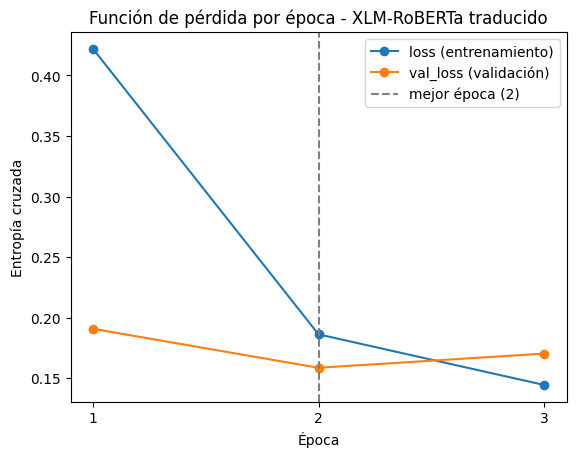

              precision    recall  f1-score   support

    negativo      0.836     0.904     0.868       738
     neutral      1.000     1.000     1.000       560
    positivo      0.897     0.825     0.860       749

    accuracy                          0.901      2047
   macro avg      0.911     0.910     0.909      2047
weighted avg      0.903     0.901     0.901      2047



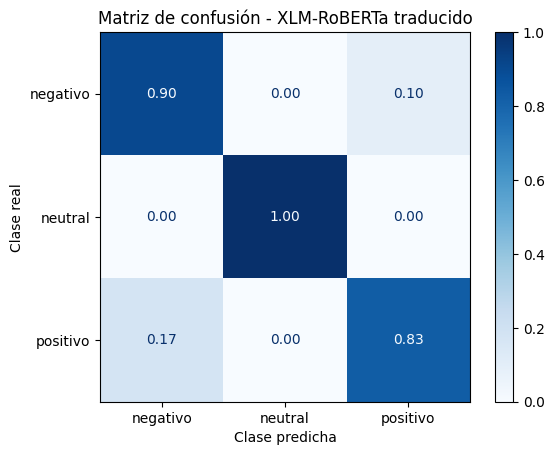

,accuracy,resenas
idioma,,
es_en,0.818182,33
fr,0.842857,210
pt_br,0.896996,233
en,0.910256,234
es,0.911743,1337


202 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
9817,en,positivo,negativo,"I bought it about a month ago from an online shop, it arrived in four days, and I use it to replace another device I already had at home. Truthfully, I wouldn't recommend the interface to anyone. It's on the desk next to the computer, and I plug it in there almost every day. The memory, though, really makes me happy, I have to admit."
8660,fr,positivo,negativo,"Le son sur les basses est franchement impressionnant pour ce prix, et la batterie tient vraiment la semaine. Mais les aigus grincent un peu quand je monte le volume, et le plastique fait cheap sous la main. Les deux défauts m'agacent autant que les qualités me plaisent, honnêtement je ne sais pas encore si je le garde."
6345,fr,negativo,positivo,"Le casque m'est arrivé un mardi, deux jours après l'avoir commandé, et je m'en suis servi direct pour les réunions du boulot. L'ergonomie, une vraie réussite. Je l'ai branché sur le port USB du portable et je l'y ai laissé installé. Le micro m'a déçu au possible. Donc je le laisse tel quel."
8489,es,positivo,negativo,"Me llegó a mediados de mes, lo compré en línea y tardó como cuatro días en llegar. La verdad, el acabado no vale lo que cuesta. Aun así lo he estado usando todos los días en la oficina, porque la señal superó todas mis expectativas. La verdad tengo sentimientos encontrados."
19268,fr,positivo,negativo,"Je l'ai achetée mi-année sur internet et elle m'est arrivée en cinq jours environ à la maison. Je n'ai pas un seul reproche à faire à l'interface, je l'utilise presque tous les jours au bureau. Par contre, le service client fonctionne plutôt mal, je les ai contactés deux fois pour un doute sur l'inscription et là je m'en suis rendu compte. Donc je la laisse là."
11708,es,positivo,negativo,"Lo compré a mediados de año por internet y me llegó en unos nueve días. La uso en el escritorio de la oficina casi a diario. La verdad, terminé harto de la construcción. Por otro lado, estoy feliz con el soporte técnico, porque tuve que escribirles una vez por un tema de configuración y me respondieron ese mismo día. La guardo en su caja original cuando no la uso. Tengo sentimientos encontrados."
4538,es,positivo,negativo,"Compré esto a mediados de año por internet y llegó en unos días sin contratiempos. La batería me hizo la vida más fácil desde que empecé a usarla en mis salidas cotidianas. Eso sí, con la resistencia al agua no paré de tener problemas desde el primer mes. Así que ahí lo dejo."
3718,pt_br,negativo,positivo,"A fritadeira elétrica sem óleo esquenta rápido e as batatas ficam crocantes de verdade, o que eu gostei bastante. Por outro lado, o cesto é pequeno demais para uma família, acabei fazendo dois lotes no mesmo jantar. O painel é simples, mas o barulho incomoda um pouco. Fico em dúvida se o espaço que ela ocupa na bancada compensa, ainda não me decidi sobre ficar com ela."
18276,en,negativo,positivo,"I ordered it on a Tuesday and it arrived by Friday, in its sealed box. I bought it because I was redoing a few things in the living room. The remote control was a purchase mistake. Other than that, the quality is exactly what I was looking for. It has a bit of everything, as you can see in the listing photos."
2277,es,positivo,negativo,"Las sartenes calientan parejo y el antiadherente funciona bien al inicio, los huevos salen deslizándose sin problema. Lo que no me convence es el mango: se afloja con el uso y hay que apretarlo cada semana. El tamaño grande es útil y a la vez complicado para cocinas pequeñas porque no cabe en el lavaplatos. Llevo dos meses usándolas y honestamente sigo sin decidir si las cambiaría."


In [75]:
errores_roberta_traducido = evaluar_modelo_validacion(
    xlm_roberta_traducido.clases_test,
    test_df,
    "XLM-RoBERTa traducido",
    repo_historial=f"{USUARIO_HF}/proyecto-ml-{xlm_roberta_traducido.nombre_corto}",
)

In [76]:
from sklearn.metrics import roc_auc_score


def auc_positivo_negativo(probs, df):
    """AUC de r = p_pos / (p_pos + p_neg) para separar las reseñas positivas de las negativas de `df`."""
    neg, pos = etiqueta_a_id["negativo"], etiqueta_a_id["positivo"]
    polares = (df["label"] != "neutral").values
    r = probs[polares, pos] / (probs[polares, pos] + probs[polares, neg])
    return roc_auc_score(df["label"].values[polares] == "positivo", r)


def accuracy_umbral_cv(probs, reales, grilla=np.round(np.arange(0.5, 0.91, 0.05), 2)):
    """Accuracy con el umbral de 5.2 elegido por validación cruzada: se elige con 4/5 de las reseñas y
    se mide en el 1/5 restante."""
    clases = np.empty(len(reales), dtype=int)
    for idx_elegir, idx_evaluar in StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42
    ).split(probs, reales):
        mejor = max(
            grilla,
            key=lambda u: (clases_con_umbral(probs[idx_elegir], u) == reales[idx_elegir]).mean(),
        )
        clases[idx_evaluar] = clases_con_umbral(probs[idx_evaluar], mejor)
    return (clases == reales).mean()


reales = test_df["label"].map(etiqueta_a_id).values
comparados = {
    "XLM-RoBERTa": xlm_roberta,
    "XLM-RoBERTa_aumentado": xlm_roberta_aumentado,
    "XLM-RoBERTa_traducido": xlm_roberta_traducido,
}
filas = []
for nombre, resultado in comparados.items():
    aciertos = resultado.probs_test.argmax(axis=1) == reales
    fila = {
        "modelo": nombre,
        "accuracy test_df": aciertos.mean(),
        "accuracy con umbral (CV)": accuracy_umbral_cv(resultado.probs_test, reales),
        "AUC pos/neg": auc_positivo_negativo(resultado.probs_test, test_df),
        "% positivo en eval": (
            resultado.probs_eval.argmax(axis=1) == etiqueta_a_id["positivo"]
        ).mean(),
    }
    # Accuracy en test_df por idioma
    fila.update(
        {
            f"accuracy {idioma}": a
            for idioma, a in pd.Series(aciertos).groupby(test_df["idioma"].values).mean().items()
        }
    )
    filas.append(fila)

display(pd.DataFrame(filas).set_index("modelo").round(4))

,accuracy test_df,accuracy con umbral (CV),AUC pos/neg,% positivo en eval,accuracy en,accuracy es,accuracy es_en,accuracy fr,accuracy pt_br
modelo,,,,,,,,,
XLM-RoBERTa,0.8999,0.9047,0.9590,0.3612,0.9103,0.9080,0.7879,0.8429,0.9099
XLM-RoBERTa_aumentado,0.8886,0.8979,0.9598,0.5129,0.8846,0.8915,0.8182,0.8762,0.8970
XLM-RoBERTa_traducido,0.9013,0.8964,0.9606,0.3702,0.9103,0.9117,0.8182,0.8429,0.8970


In [77]:
mdeberta_traducido = entrenar_transformer(nombre_modelo="microsoft/mdeberta-v3-base", nombre_corto="mDeBERTa_traducido", train_df=train_df_traducido, test_df=test_df, dataset_eval=dataset_eval)

config.json:   0%|          | 0.00/1.08k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.93k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/555 [00:00<?, ?B/s]

mDeBERTa_traducido cargado de Hugging Face (mejor época: 3, val_loss = 0.1582, val_accuracy = 0.8979)
submission_mDeBERTa_traducido.csv ya existe en Hugging Face; no se vuelve a crear


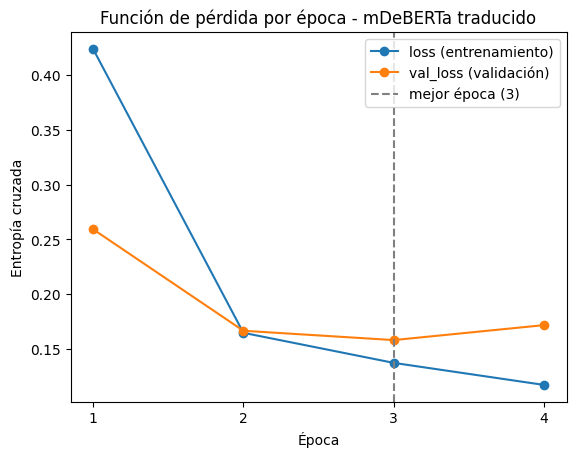

              precision    recall  f1-score   support

    negativo      0.904     0.804     0.851       738
     neutral      0.998     1.000     0.999       560
    positivo      0.825     0.915     0.868       749

    accuracy                          0.898      2047
   macro avg      0.909     0.906     0.906      2047
weighted avg      0.901     0.898     0.898      2047



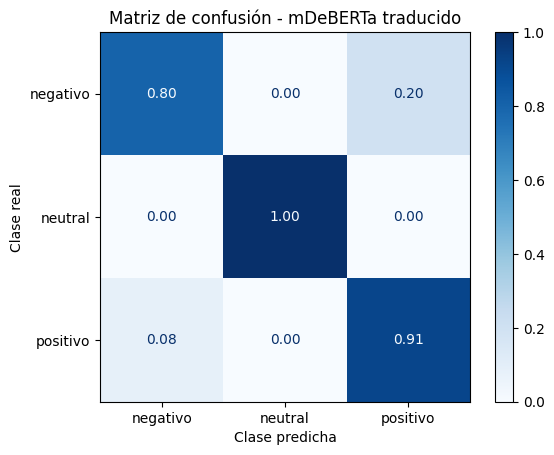

,accuracy,resenas
idioma,,
es_en,0.787879,33
en,0.876068,234
es,0.897532,1337
fr,0.900000,210
pt_br,0.935622,233


209 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
8295,es,positivo,negativo,"Compré esto hace un mes más o menos por internet y me llegó en tres días. Lo uso a diario desde entonces, en las tardes después del trabajo. La resistencia al agua no volvería a comprarla ni regalado. El sistema de sonido, en cambio, me dejó encantado. Todavía no me decido."
7487,en,negativo,positivo,"The air fryer crisps up frozen fries surprisingly well and preheats faster than I expected. On the other hand, the basket is smaller than the listing suggested, so I'm cooking dinner in two batches now. The nonstick coating already shows scratches after a month, yet cleanup is still easier than my old oven pan. Some days I reach for it constantly, other weeks it just sits there. Honestly I still haven't decided whether it earned its counter space or not."
15569,es,positivo,negativo,"La batería del smartwatch me dura casi toda la week sin cargarla, eso está really nice. Pero el screen se ve mediocre under sunlight, barely puedo leer las notifications afuera. El fitness tracking sí es accurate, aunque las straps que trae se sienten cheap. La verdad, no sé si hacer el return o quedármelo, sigue being una decisión bien tough para mí."
732,en,negativo,positivo,"The lumbar support on this chair is genuinely good for my lower back after long days at the desk. On the other hand, the armrests creak constantly no matter how many times I tighten them, and the fabric collects dust fast. Half the week I feel I made the right choice, the other half I second-guess it. My coworker loves hers while my brother returned his identical one, so maybe it depends on the unit or the person. I honestly can't tell if I'd buy it again."
1929,en,negativo,positivo,"I ordered it mid-month and it arrived at my place in four days, in a plain box with nothing odd about it. The power button fell way short of my expectations. I've been using it at the office pretty much daily since then. By the way, I ended up happy with the memory. That's up to each person to decide."
14577,es,negativo,positivo,"La cafetera calienta el agua bastante rápido y el café sale con buen sabor, eso me gusta. Lo que me tiene pensando es que la jarra gotea cada vez que sirvo y el filtro se desborda si lleno mucho. Supongo que con el tiempo me acostumbraré, pero no sé si fue la mejor compra o si debería haber seguido buscando un poco más."
19415,es,positivo,negativo,"Me llegó el lunes, lo pedí el jueves anterior, así que el envío no se demoró. Lo uso en la oficina desde entonces. El ensamblaje no volvería a comprarlo ni regalado, la verdad. Por otro lado, la autonomía me sorprendió para bien. Ni lo mejor ni lo peor."
16576,fr,negativo,positivo,"Le micro est arrivé un mardi avec la livraison standard, sans souci. Le micro est au-dessus de la moyenne. La mémoire m'a déçu sur toute la ligne, je l'ai utilisée deux semaines. Bref, ni bien ni mal."
4773,es,negativo,positivo,"Compré esto el mes pasado porque lo vi en oferta un domingo por la tarde. La comodidad funciona de maravilla. Lo estuve probando varios días seguidos en casa. Por cierto, quedé muy molesto con el servicio. El envío llegó en unos cinco días a mi domicilio."
2836,pt_br,negativo,positivo,"Comprei essa tela touch no meio do ano e chegou em uns quatro dias na minha casa. Uso ela num projeto pequeno que tenho na mesa de trabalho, nada muito especial. Sinceramente, fiquei bem chateado com o material. Mesmo assim, voltaria a comprar a tela touch sem pensar duas vezes. Cada um que tire as próprias conclusões."


In [78]:
errores_mdberta_traducido = evaluar_modelo_validacion(
    mdeberta_traducido.clases_test,
    test_df,
    "mDeBERTa traducido",
    repo_historial=f"{USUARIO_HF}/proyecto-ml-{mdeberta_traducido.nombre_corto}",
)

In [79]:
roberta_large_traducido = entrenar_transformer(nombre_modelo="xlm-roberta-large", nombre_corto="RoBERTa_large_traducido", train_df=train_df_traducido, test_df=test_df, dataset_eval=dataset_eval)

config.json:   0%|          | 0.00/970 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/559 [00:00<?, ?B/s]

RoBERTa_large_traducido cargado de Hugging Face (mejor época: 3, val_loss = 0.1559, val_accuracy = 0.8974)
submission_RoBERTa_large_traducido.csv ya existe en Hugging Face; no se vuelve a crear


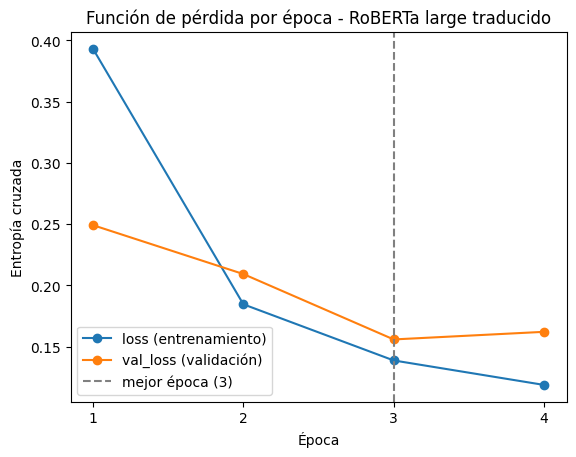

              precision    recall  f1-score   support

    negativo      0.857     0.859     0.858       738
     neutral      1.000     1.000     1.000       560
    positivo      0.861     0.858     0.860       749

    accuracy                          0.897      2047
   macro avg      0.906     0.906     0.906      2047
weighted avg      0.897     0.897     0.897      2047



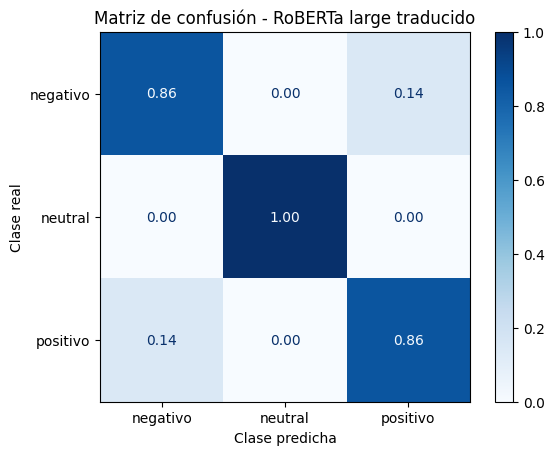

,accuracy,resenas
idioma,,
es_en,0.757576,33
en,0.876068,234
fr,0.895238,210
es,0.899028,1337
pt_br,0.931330,233


210 de 2047 reseñas mal clasificadas. Algunas de ellas:


,idioma,label,prediccion,text
8263,es,positivo,negativo,"La compré a inicios de mes y llegó a mi casa en tres días, para uso personal en la sala. Después de varias semanas, lo estoy usando en casa casi a diario, sobre todo en las tardes. El botón de encendido me decepcionó de lo lindo, la verdad. Por cierto, cada peso que pagué por la velocidad valió la pena, así de sencillo. Así que ahí lo dejo."
5882,fr,positivo,negativo,"Le colis m'est arrivé un mardi, si je me souviens bien trois jours après l'avoir commandé, et je l'ai ouvert dès que le livreur a apporté la boîte. Je recommande le matériel les yeux fermés et le matériel m'a déçu au plus haut point. Je l'ai examiné tranquillement ce même après-midi sur la table de la salle à manger. Des goûts et des couleurs, on ne discute pas."
15569,es,positivo,negativo,"La batería del smartwatch me dura casi toda la week sin cargarla, eso está really nice. Pero el screen se ve mediocre under sunlight, barely puedo leer las notifications afuera. El fitness tracking sí es accurate, aunque las straps que trae se sienten cheap. La verdad, no sé si hacer el return o quedármelo, sigue being una decisión bien tough para mí."
11060,pt_br,positivo,negativo,"Comprei a capinha no começo do mês e chegou em quatro dias. Fiquei decepcionada com o atendimento ao cliente do começo ao fim. Uso ela todo dia no trabalho, virei mania de levar na mochila. Aliás, a capinha é exatamente o que eu estava procurando. Não saberia bem o que recomendar."
341,en,positivo,negativo,"I've been using it at home ever since I bought it. I don't have a single complaint about the motor. That said, the resolution really let me down big time. I honestly wouldn't know what to recommend."
5665,pt_br,negativo,positivo,"As sapatilhas de corrida têm um amortecimento excelente nas passadas mais longas, o que alivia bastante os joelhos. Por outro lado, o cabedal aperta demais no pé direito e deixou marcas mesmo depois de duas semanas de uso. Não sei se valeram o preço pago; dependendo do formato do seu pé, podem ser ótimas ou um incômodo constante. Ainda estou decidindo se uso com frequência ou deixo de lado."
15653,es,negativo,positivo,"Lo compre a mediados de ano por internet, llego en unos cuaatro dias y venia en su caja sellada. Le pondria cinco estrellas a la terminacion, se nota cuidada al detalle. Lo uso a diario en la oficina junto a la computadora. Eso si, la pantalla tactil se dano antes de lo que esperaba. Ni tan bueno ni tan malo."
16576,fr,negativo,positivo,"Le micro est arrivé un mardi avec la livraison standard, sans souci. Le micro est au-dessus de la moyenne. La mémoire m'a déçu sur toute la ligne, je l'ai utilisée deux semaines. Bref, ni bien ni mal."
9835,es,positivo,negativo,"Compré este equipo a mediados de mes y llegó en tres días a mi casa. El procesador fue todo un acierto, la verdad que sin quejas en esa parte. Ahora, el cargador me decepcionó de lo lindo; no me lo esperaba. Lo estuve probando estos días junto con todo lo demás que venía en la caja."
20335,es,positivo,negativo,"La compre a mediados de año por internet y me llego en unos cinco dias a mi casa. No tengo ni una sola queja de la interfaz, la uso casi todos los dias en la oficina. Por otro lado, la atencion al cliente funciona bastante mal, la contacte un par de veces por una duda del registro y ahi me di cuenta. Asi que ahi lo dejo."


In [80]:
errores_roberta_large_traducido = evaluar_modelo_validacion(
    roberta_large_traducido.clases_test,
    test_df,
    "RoBERTa large traducido",
    repo_historial=f"{USUARIO_HF}/proyecto-ml-{roberta_large_traducido.nombre_corto}",
)

### Elección del modelo final, entrenamiento sobre el conjunto completo y ajuste de hiperparámetros

El criterio final que usamos es  `val_loss`, no `val_accuracy` para aumentar la regularización. Estas son las métricas en `test_df` de la época que restauró la parada
temprana de cada transformer:

| Modelo | Mejor época | `val_loss` | `val_accuracy` |
| --- | --- | --- | --- |
| XLM-RoBERTa-large (4.6) | 3 | **0,1510** | 0,9013 |
| RoBERTa_large_traducido (5.3) | 3 | 0,1559 | 0,8974 |
| mDeBERTa_traducido (5.3) | 3 | 0,1582 | 0,8979 |
| XLM-RoBERTa_traducido (5.3) | 2 | 0,1586 | 0,9013 |
| mDeBERTa (4.10) | 3 | 0,1641 | **0,9028** |
| XLM-RoBERTa_ultima (4.5) | 3 | 0,1696 | 0,9023 |
| XLM-RoBERTa (4.2) | 3 | 0,1700 | 0,8999 |
| XLM-RoBERTa-Twitter (4.3) | 2 | 0,1701 | 0,8999 |
| XLM-RoBERTa_aumentado (5.1) | 2 | 0,1752 | 0,8886 |
| mBERT (4.1) | 3 | 0,2364 | 0,8828 |

Elegimos con `val_loss` por tres razones:

1. El accuracy no distingue a los mejores modelos. Los siete primeros están entre 0,8974 y 0,9028: 11 reseñas de
   diferencia, cuando el error estándar del accuracy con 2.047 reseñas es de unos 0,66 puntos (≈13 reseñas).
2. El accuracy depende sobre todo de hacia dónde se inclina cada modelo en las reseñas ambiguas. En el análisis de
   errores vimos que la mayoría de los errores están en reseñas que terminan con un cierre ambiguo ("ni fu ni fa",
   "cada quien que juzgue"), cuyas etiquetas son ≈50/50. Cada entrenamiento se inclina hacia un lado de forma bastante
   arbitraria: large tiene recall 0,943 en positivo y 0,786 en negativo, y mDeBERTa casi al revés (0,761 y 0,976). Los
   dos tienen el mismo accuracy por razones opuestas.
3. `val_loss` usa la probabilidad que el modelo le da a la clase correcta en cada una de las 2.047 reseñas, no solo
   si acierta. Castiga los errores cometidos con seguridad y premia ordenar bien las reseñas, que es lo que importa
   para combinar modelos o mover umbrales. Además es lo que minimiza la parada temprana. Contar aciertos es una medida
   mucho más ruidosa.

XLM-RoBERTa-large tiene el menor `val_loss` (0,1510), con ventaja clara sobre el siguiente (0,1559). También es el
de mayor capacidad (560 M de parámetros) y casi no sobreajusta: 0,912 de accuracy en entrenamiento contra 0,901 en
validación. La celda siguiente calcula, con un bootstrap pareado sobre las reseñas de `test_df`, si la diferencia de
`val_loss` con cada modelo es mayor que el ruido.

Sin aumentación. La traducción (5.3) bajó el `val_loss` de los modelos base (XLM-RoBERTa de 0,1700 a 0,1586,
mDeBERTa de 0,1641 a 0,1582), pero lo subió en large (de 0,1510 a 0,1559). El intercambio de opiniones (5.1) empeoró
todo. El modelo final se entrena entonces con el conjunto completo (`train_df` + `test_df`, 20.466 reseñas) y sin
reseñas aumentadas. Para modelos más sencillos, la aumentación de datos si mejora el desempeño.

Un solo modelo, no un ensamble. Los ensambles de 4.7 y 4.8 llegaron a 0,905 y 0,902 de accuracy, dentro del
ruido de large solo (0,901). Además exigirían reentrenar varios modelos con el conjunto completo.

In [81]:
# Todos los transformers entrenados con train_df y validados con test_df
candidatos = {
    "mBERT": mbert,
    "XLM-RoBERTa": xlm_roberta,
    "XLM-RoBERTa-Twitter": twitter,
    "XLM-RoBERTa_ultima": roberta_ultima,
    "XLM-RoBERTa-large": xlm_roberta_large,
    "mDeBERTa": mdeberta,
    "XLM-RoBERTa_aumentado": xlm_roberta_aumentado,
    "XLM-RoBERTa_traducido": xlm_roberta_traducido,
    "mDeBERTa_traducido": mdeberta_traducido,
    "RoBERTa_large_traducido": roberta_large_traducido,
}
reales = test_df["label"].map(etiqueta_a_id).values

seleccion = resumir_historiales({n: r.historial for n, r in candidatos.items()}).set_index("modelo")
seleccion["AUC pos/neg"] = pd.Series(
    {n: auc_positivo_negativo(r.probs_test, test_df) for n, r in candidatos.items()}
)


def perdida_por_resena(probs):
    """Entropía cruzada de cada reseña de test_df: -log de la probabilidad de su clase real."""
    return -np.log(np.clip(probs[np.arange(len(reales)), reales], 1e-12, None))


# Bootstrap pareado: se remuestrean las mismas reseñas para los dos modelos, así la diferencia
# solo refleja al modelo y no qué reseñas cayeron en la muestra
mejor_nombre = seleccion["val_loss"].idxmin()
perdida_mejor = perdida_por_resena(candidatos[mejor_nombre].probs_test)
muestras = np.random.default_rng(42).integers(0, len(reales), size=(2000, len(reales)))
for nombre, resultado in candidatos.items():
    diferencia = perdida_por_resena(resultado.probs_test) - perdida_mejor
    medias = diferencia[muestras].mean(axis=1)
    seleccion.loc[nombre, f"val_loss − {mejor_nombre}"] = diferencia.mean()
    seleccion.loc[nombre, "IC 95 %"] = (
        f"[{np.percentile(medias, 2.5):.4f}, {np.percentile(medias, 97.5):.4f}]"
    )

print(f"Menor val_loss: {mejor_nombre}. Si el IC 95 % de un modelo no incluye 0, su val_loss es peor con seguridad.")
display(seleccion.sort_values("val_loss").round(4))

Menor val_loss: XLM-RoBERTa-large. Si el IC 95 % de un modelo no incluye 0, su val_loss es peor con seguridad.


,mejor_epoca,val_accuracy,val_loss,train_accuracy,AUC pos/neg,val_loss − XLM-RoBERTa-large,IC 95 %
modelo,,,,,,,
XLM-RoBERTa-large,3,0.9013,0.1510,0.9116,0.9638,0.0000,"[0.0000, 0.0000]"
RoBERTa_large_traducido,3,0.8974,0.1559,0.9199,0.9632,0.0048,"[-0.0036, 0.0137]"
mDeBERTa_traducido,3,0.8979,0.1582,0.9206,0.9627,0.0072,"[-0.0022, 0.0179]"
XLM-RoBERTa_traducido,2,0.9013,0.1586,0.9022,0.9606,0.0076,"[-0.0014, 0.0164]"
mDeBERTa,3,0.9028,0.1641,0.9123,0.9604,0.0131,"[0.0010, 0.0272]"
XLM-RoBERTa_ultima,3,0.9023,0.1696,0.9206,0.9575,0.0185,"[0.0074, 0.0303]"
XLM-RoBERTa,3,0.8999,0.1700,0.9147,0.9590,0.0190,"[0.0069, 0.0318]"
XLM-RoBERTa-Twitter,2,0.8999,0.1701,0.9002,0.9593,0.0191,"[0.0081, 0.0307]"
XLM-RoBERTa_aumentado,2,0.8886,0.1752,0.9101,0.9598,0.0241,"[0.0141, 0.0355]"


#### Ajuste de hiperparámetros

Un transformer grande es sensible sobre todo a la tasa de aprendizaje. Ajustamos dos hiperparámetros con la misma división `train_df` / `test_df` y elegimos por `val_loss`:

1. Tasa de aprendizaje: buscamos entre 1e-5, 2e-5 y 3e-5, el rango con que se ajustó RoBERTa-large en su artículo original. La de
   2e-5 es el modelo de 4.6, que ya está entrenado.
2. Tasa de aprendizaje decreciente por capa (LLRD), solo con la mejor tasa del paso 1: la capa de clasificación y
   la última capa del encoder usan la tasa completa, y cada capa hacia abajo la multiplica por 0,9. Las capas bajas
   guardan lo que el modelo aprendió de los 100 idiomas del preentrenamiento, y actualizarlas menos ayuda a no
   olvidarlo, sobre todo en los idiomas con pocas reseñas.

Se ajustan uno después del otro (no todas las combinaciones) porque cada entrenamiento de large es costoso: son tres
entrenamientos nuevos. El número de épocas lo decide la parada temprana de la mejor configuración. Dejamos fijos,
en valores estándar, el tamaño de lote (16, por memoria de la GPU), `MAX_TOKENS` (256, que no recorta ninguna reseña),
el calentamiento (10 % de los pasos) y el weight decay (0,01, el de AdamW).

Cada configuración se entrena una sola vez, y en la sección 5.2 vimos que dos entrenamientos iguales pueden diferir por
azar. Una diferencia pequeña de `val_loss` entre configuraciones puede ser ruido.

Para usar LLRD ampliamos `entrenar_transformer_con_parada_temprana` de la sección 4 con el parámetro
`decaimiento_capa`. Con `decaimiento_capa = 1` entrena exactamente igual que antes, así que los modelos ya guardados no
cambian. `entrenar_transformer` le pasa sus parámetros, así que no hay que modificar nada más.

In [82]:
import re


def grupos_por_capa(model, lr, decaimiento):
    """Grupos de parámetros para AdamW con tasa de aprendizaje decreciente hacia abajo (LLRD): la capa
    de clasificación y la última capa del encoder usan `lr`, y cada capa hacia abajo la multiplica por
    `decaimiento`. Con decaimiento = 1 todas usan `lr`."""
    n_capas = model.config.num_hidden_layers
    prefijo = model.base_model_prefix  # "roberta" o "deberta"
    grupos = {}
    for nombre, parametro in model.named_parameters():
        capa = re.search(r"encoder\.layer\.(\d+)\.", nombre)
        if capa:
            profundidad = int(capa.group(1)) + 1  # 1 (primera capa) … n_capas (última)
        elif nombre.startswith(f"{prefijo}.embeddings"):
            profundidad = 0
        else:
            # Capa de clasificación, pooler y, en DeBERTa, las posiciones relativas que usan todas las capas
            profundidad = n_capas
        grupos.setdefault(profundidad, []).append(parametro)
    return [
        {"params": parametros, "lr": lr * decaimiento ** (n_capas - profundidad)}
        for profundidad, parametros in grupos.items()
    ]


def crear_optimizador(model, lr, decaimiento_capa, pasos):
    """AdamW con LLRD y la planificación de la sección 4: la tasa sube durante el primer 10 % de
    `pasos` y después baja linealmente a 0."""
    optimizador = torch.optim.AdamW(grupos_por_capa(model, lr, decaimiento_capa))
    planificador = get_linear_schedule_with_warmup(optimizador, int(0.1 * pasos), pasos)
    return optimizador, planificador


def entrenar_una_epoca(model, loader, optimizador, planificador, descripcion):
    """Una pasada por `loader`. Devuelve la pérdida y el accuracy promedio de entrenamiento."""
    model.train()
    perdida, aciertos, n = 0.0, 0, 0
    for lote in tqdm(loader, desc=descripcion):
        lote = lote.to(dispositivo)
        salida = model(**lote)  # con `labels`, el modelo calcula la entropía cruzada
        salida.loss.backward()
        optimizador.step()
        planificador.step()
        optimizador.zero_grad()
        perdida += salida.loss.item() * len(lote["labels"])
        aciertos += (salida.logits.argmax(dim=-1) == lote["labels"]).sum().item()
        n += len(lote["labels"])
    return perdida / n, aciertos / n


def entrenar_transformer_con_parada_temprana(
    model, train_loader, test_loader, max_epochs=4, patience=1, lr=2e-5, decaimiento_capa=1.0
):
    """La misma función de la sección 4 (parada temprana por val_loss, restaurando la mejor época),
    con LLRD. Con decaimiento_capa = 1 entrena exactamente igual que la original."""
    optimizador, planificador = crear_optimizador(
        model, lr, decaimiento_capa, max_epochs * len(train_loader)
    )
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    mejor_epoca, mejor_estado = 0, None

    for epoca in range(max_epochs):
        perdida, accuracy = entrenar_una_epoca(
            model, train_loader, optimizador, planificador, f"Época {epoca + 1}/{max_epochs}"
        )
        val_loss, val_accuracy = evaluar_transformer(model, test_loader)
        for clave, valor in zip(history, (perdida, accuracy, val_loss, val_accuracy)):
            history[clave].append(valor)
        print(
            f"loss = {perdida:.4f}, accuracy = {accuracy:.4f}, "
            f"val_loss = {val_loss:.4f}, val_accuracy = {val_accuracy:.4f}"
        )

        if val_loss <= min(history["val_loss"]):
            # Copia de los pesos en CPU, equivalente a restore_best_weights=True
            mejor_epoca = epoca
            mejor_estado = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        elif epoca - mejor_epoca >= patience:
            print(f"Parada temprana en la época {epoca + 1}")
            break

    model.load_state_dict(mejor_estado)
    print(
        f"Mejor época según val_loss: {mejor_epoca + 1} "
        f"(val_loss = {history['val_loss'][mejor_epoca]:.4f}, "
        f"val_accuracy = {history['val_accuracy'][mejor_epoca]:.4f})"
    )
    return SimpleNamespace(history=history, mejor_epoca=mejor_epoca)


def entrenar_sin_validacion(model, train_loader, epocas, max_epochs, lr, decaimiento_capa):
    """Entrena `epocas` épocas sin validación, para el modelo final. La planificación de la tasa de
    aprendizaje se calcula para `max_epochs` épocas, igual que en el entrenamiento validado, así la
    tasa sigue la misma trayectoria que tenía en la época que eligió la parada temprana."""
    optimizador, planificador = crear_optimizador(
        model, lr, decaimiento_capa, max_epochs * len(train_loader)
    )
    history = {"loss": [], "accuracy": []}
    for epoca in range(epocas):
        perdida, accuracy = entrenar_una_epoca(
            model, train_loader, optimizador, planificador, f"Época {epoca + 1}/{epocas}"
        )
        history["loss"].append(perdida)
        history["accuracy"].append(accuracy)
        print(f"loss = {perdida:.4f}, accuracy = {accuracy:.4f}")
    return SimpleNamespace(history=history, mejor_epoca=epocas - 1)

In [83]:
MAX_EPOCAS = 4
TASAS = [1e-5, 2e-5, 3e-5]
DECAIMIENTO_LLRD = 0.9


def nombre_configuracion(lr, decaimiento):
    return f"XLM-RoBERTa-large_lr{lr:g}_llrd{decaimiento:g}"


def entrenar_configuracion(lr, decaimiento):
    """XLM-RoBERTa-large entrenado con train_df y validado con test_df con estos hiperparámetros. Cada
    configuración se guarda en su propio repositorio de Hugging Face, así que no se vuelve a entrenar."""
    if lr == 2e-5 and decaimiento == 1.0:
        return xlm_roberta_large  # el modelo de la sección 4.6 ya usa estos hiperparámetros
    return entrenar_transformer(
        nombre_modelo="xlm-roberta-large",
        nombre_corto=nombre_configuracion(lr, decaimiento),
        max_epochs=MAX_EPOCAS,
        lr=lr,
        decaimiento_capa=decaimiento,
    )


def val_loss_restaurado(resultado):
    h = resultado.historial
    return h.history["val_loss"][h.mejor_epoca]


# Paso 1: tasa de aprendizaje, sin LLRD
busqueda = {(lr, 1.0): entrenar_configuracion(lr, 1.0) for lr in TASAS}
mejor_lr = min(TASAS, key=lambda lr: val_loss_restaurado(busqueda[(lr, 1.0)]))

# Paso 2: LLRD con la mejor tasa
busqueda[(mejor_lr, DECAIMIENTO_LLRD)] = entrenar_configuracion(mejor_lr, DECAIMIENTO_LLRD)

tabla_busqueda = resumir_historiales(
    {nombre_configuracion(*k): r.historial for k, r in busqueda.items()}
).set_index("modelo")
tabla_busqueda["AUC pos/neg"] = pd.Series(
    {nombre_configuracion(*k): auc_positivo_negativo(r.probs_test, test_df) for k, r in busqueda.items()}
)
display(tabla_busqueda.sort_values("val_loss").round(4))

configuracion_final = min(busqueda, key=lambda k: val_loss_restaurado(busqueda[k]))
lr_final, decaimiento_final = configuracion_final
epocas_finales = busqueda[configuracion_final].historial.mejor_epoca + 1
print(
    f"Configuración final: lr = {lr_final:g}, decaimiento por capa = {decaimiento_final:g}, "
    f"{epocas_finales} épocas"
)
if epocas_finales == MAX_EPOCAS:
    print("Aviso: la mejor época fue la última; con más épocas el val_loss podría seguir bajando.")

config.json:   0%|          | 0.00/970 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/448 [00:00<?, ?B/s]

... (13 outputs left out)

historial.json:   0%|          | 0.00/451 [00:00<?, ?B/s]

XLM-RoBERTa-large_lr2e-05_llrd0.9 cargado de Hugging Face (mejor época: 2, val_loss = 0.1522, val_accuracy = 0.9077)
submission_XLM-RoBERTa-large_lr2e-05_llrd0.9.csv ya existe en Hugging Face; no se vuelve a crear


,mejor_epoca,val_accuracy,val_loss,train_accuracy,AUC pos/neg
modelo,,,,,
XLM-RoBERTa-large_lr2e-05_llrd1,3,0.9013,0.1510,0.9116,0.9638
XLM-RoBERTa-large_lr2e-05_llrd0.9,2,0.9077,0.1522,0.9012,0.9657
XLM-RoBERTa-large_lr1e-05_llrd1,2,0.9077,0.1557,0.9041,0.9618
XLM-RoBERTa-large_lr3e-05_llrd1,4,0.9052,0.1662,0.9177,0.9630


Configuración final: lr = 2e-05, decaimiento por capa = 1, 3 épocas


#### Entrenamiento con el conjunto completo

Con los hiperparámetros elegidos entrenamos XLM-RoBERTa-large desde cero con las 20.466 reseñas de entrenamiento
(`train_df` + `test_df`). Ya no queda un conjunto de validación, así que no puede haber parada temprana:

- **Épocas:** las de la época que restauró la parada temprana en la configuración elegida.
- **Planificación de la tasa de aprendizaje:** se calcula para `MAX_EPOCAS` épocas, como en el entrenamiento validado,
  y el entrenamiento se detiene en la época elegida. Así la tasa sigue la misma trayectoria que tenía el modelo cuyo
  `val_loss` medimos. Con un 11 % más de reseñas, cada época tiene un 11 % más de pasos.
- **Sin umbral.** No movemos el umbral entre positivo y negativo (5.2): en las reseñas ambiguas cada entrenamiento se
  inclina hacia un lado distinto, así que un umbral elegido con otro entrenamiento no se transfiere, y este modelo ya
  no se puede validar con `test_df`.

Como `test_df` ahora es parte del entrenamiento, el accuracy en `test_df` de este modelo ya no mide nada. La única
evaluación es el leaderboard de Kaggle. Como control, comparamos sus predicciones en `dataset_eval` con las del mismo
modelo entrenado solo con `train_df`: deberían coincidir casi siempre.

In [84]:
NOMBRE_FINAL = f"XLM-RoBERTa-large_completo_lr{lr_final:g}_llrd{decaimiento_final:g}"
repo_final = f"{USUARIO_HF}/proyecto-ml-{NOMBRE_FINAL}"

# Conjunto completo: las 20.466 reseñas de entrenamiento, sin aumentación (ver la justificación arriba)
datos_completos = pd.concat([train_df, test_df], ignore_index=True)
print(f"Conjunto completo: {len(datos_completos)} reseñas")

if not REENTRENAR and api.file_exists(repo_final, "historial.json"):
    tokenizador_final = AutoTokenizer.from_pretrained(repo_final)
    modelo_final = AutoModelForSequenceClassification.from_pretrained(repo_final).to(dispositivo)
    historial_final = descargar_historial(repo_final, "historial.json")
    print(f"{NOMBRE_FINAL} cargado de Hugging Face")
else:
    tokenizador_final, modelo_final = cargar_transformer("xlm-roberta-large")
    historial_final = entrenar_sin_validacion(
        modelo_final,
        dataset_a_torch(datos_completos, shuffle=True, tokenizador=tokenizador_final),
        epocas=epocas_finales,
        max_epochs=MAX_EPOCAS,
        lr=lr_final,
        decaimiento_capa=decaimiento_final,
    )
    modelo_final.push_to_hub(repo_final, private=True)
    tokenizador_final.push_to_hub(repo_final, private=True)
    # El historial se sube al final: marca que el modelo está completo
    api.upload_file(
        path_or_fileobj=historial_a_json(historial_final),
        path_in_repo="historial.json",
        repo_id=repo_final,
        commit_message="Historial de entrenamiento (conjunto completo)",
    )
    print(f"{NOMBRE_FINAL} subido a https://huggingface.co/{repo_final}")

probs_eval_final = probabilidades(PredictorTransformer(modelo_final, tokenizador_final), dataset_eval)
del modelo_final
liberar_memoria_gpu()

submission_final = subir_submission(
    probs_eval_final.argmax(axis=1), dataset_eval, f"submission_{NOMBRE_FINAL}.csv"
)

# Control: el mismo modelo entrenado solo con train_df debería predecir casi lo mismo en dataset_eval
referencia = busqueda[configuracion_final]
pos = etiqueta_a_id["positivo"]
print(
    f"Predicciones de dataset_eval que coinciden con {nombre_configuracion(*configuracion_final)}: "
    f"{(probs_eval_final.argmax(axis=1) == referencia.probs_eval.argmax(axis=1)).mean():.3f}"
)
print(
    f"% positivo en dataset_eval: final {(probs_eval_final.argmax(axis=1) == pos).mean():.3f}, "
    f"solo train_df {(referencia.probs_eval.argmax(axis=1) == pos).mean():.3f}"
)

Conjunto completo: 20466 reseñas


config.json:   0%|          | 0.00/970 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

historial.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

XLM-RoBERTa-large_completo_lr2e-05_llrd1 cargado de Hugging Face
submission_XLM-RoBERTa-large_completo_lr2e-05_llrd1.csv ya existe en Hugging Face; no se vuelve a crear
Predicciones de dataset_eval que coinciden con XLM-RoBERTa-large_lr2e-05_llrd1: 0.954
% positivo en dataset_eval: final 0.474, solo train_df 0.478


## Referencias

### Modelos transformer

Devlin, J., Chang, M.-W., Lee, K. y Toutanova, K. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. En *Proceedings of NAACL-HLT 2019*. https://arxiv.org/abs/1810.04805. Modelo usado en la sección 4.1: [`bert-base-multilingual-cased`](https://huggingface.co/google-bert/bert-base-multilingual-cased).

Conneau, A., Khandelwal, K., Goyal, N., Chaudhary, V., Wenzek, G., Guzmán, F., Grave, E., Ott, M., Zettlemoyer, L. y Stoyanov, V. (2020). Unsupervised Cross-lingual Representation Learning at Scale. En *Proceedings of ACL 2020*. https://arxiv.org/abs/1911.02116. Modelos usados en las secciones 4.2, 4.5, 4.6, 5 y en el modelo final: [`xlm-roberta-base`](https://huggingface.co/FacebookAI/xlm-roberta-base) y [`xlm-roberta-large`](https://huggingface.co/FacebookAI/xlm-roberta-large).

Barbieri, F., Espinosa Anke, L. y Camacho-Collados, J. (2022). XLM-T: Multilingual Language Models in Twitter for Sentiment Analysis and Beyond. En *Proceedings of LREC 2022*. https://arxiv.org/abs/2104.12250. Modelo usado en la sección 4.3: [`cardiffnlp/twitter-xlm-roberta-base-sentiment`](https://huggingface.co/cardiffnlp/twitter-xlm-roberta-base-sentiment).

He, P., Gao, J. y Chen, W. (2023). DeBERTaV3: Improving DeBERTa using ELECTRA-Style Pre-Training with Gradient-Disentangled Embedding Sharing. En *Proceedings of ICLR 2023*. https://arxiv.org/abs/2111.09543. Modelo usado en las secciones 4.10 y 5.3: [`microsoft/mdeberta-v3-base`](https://huggingface.co/microsoft/mdeberta-v3-base).

He, P., Liu, X., Gao, J. y Chen, W. (2021). DeBERTa: Decoding-enhanced BERT with Disentangled Attention. En *Proceedings of ICLR 2021*. https://arxiv.org/abs/2006.03654. Arquitectura de mDeBERTa (atención desacoplada), descrita en la sección 4.10.

NLLB Team, Costa-jussà, M. R. et al. (2022). No Language Left Behind: Scaling Human-Centered Machine Translation. *arXiv:2207.04672*. https://arxiv.org/abs/2207.04672. Modelo de traducción usado en la sección 5.3: [`facebook/nllb-200-distilled-600M`](https://huggingface.co/facebook/nllb-200-distilled-600M).


## Declaración de uso de IA generativa

En el desarrollo de este proyecto se usó IA generativa, en particular el asistente Claude (Anthropic), como herramienta de apoyo. Se utilizó para escribir, revisar y depurar partes del código, para discutir ideas sobre qué modelos y estrategias probar, para analizar los resultados y los errores de los modelos, y para y corregir el texto del notebook.

La IA no reemplazó el trabajo de los autores. Las decisiones sobre qué experimentos hacer, la ejecución del código, la interpretación de los resultados y la elección del modelo final fueron hechas por el autor, quien revisó y ajustó el código y el texto sugeridos antes de incluirlos. El autor es responsable del contenido final del proyecto.